In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import Spectral_Preprocessing as sp

from argparse import ArgumentParser, Namespace
from scipy import stats

In [3]:
parser = ArgumentParser()
parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

_StoreAction(option_strings=['--baseline'], dest='baseline', nargs=None, const=None, default=5, type=<class 'int'>, choices=None, required=False, help=None, metavar=None)

In [61]:
###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800)
args.wn_range_ir_2 = (2720, 2980)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.2#0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float 
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

In [62]:
path = 'Reference_library_reb/'
dirs = os.listdir(path)
#del dirs[1]
dirs = [x for x in dirs if x not in ['.DS_Store', 'Archive for reference data', 'Processed']]
dirs

['20230708 0.05 M sucrose',
 '20230524 200 to 9900 nm PE bulk',
 '20230423 1.0 and 3.0 um PSL',
 '20230708 0.05 M NaNO3',
 '20230707 200 to 9900 nm PE EtOH iced atomized',
 '20230728 3.0 um PSL bulk',
 '20230708 0.05 M NH2SO4',
 '20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced',
 '20230524 1-5 um PP bulk']

In [32]:
file_list = []
for d in dirs:
    #print(os.listdir(path + d + '/Data/Processed/mIRage OPTIR+Raman/'))
    path_2 = path + d + '/Data/Processed/mIRage OPTIR+Raman/'
    dirs_2 = os.listdir(path_2)
    #file_list = file_list + [path_2 + dd for dd in dirs_2 if dd[-4:] == "xlsx"]
    file_list = file_list + [path_2 + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]

In [33]:
file_list = file_list + [d + '/' + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]

In [34]:
file_list

['Reference_library_reb/20230708 0.05 M sucrose/Data/Processed/mIRage OPTIR+Raman/20240509_50mMsucrose_RP_mIRage_allccdata.xlsx',
 'Reference_library_reb/20230423 1.0 and 3.0 um PSL/Data/Processed/mIRage OPTIR+Raman/20230424_1and3umPSL_allccdata.xlsx',
 'Reference_library_reb/20230708 0.05 M NaNO3/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNaNO3_RP_mIRage_allccdata.xlsx',
 'Reference_library_reb/20230707 200 to 9900 nm PE EtOH iced atomized/Data/Processed/mIRage OPTIR+Raman/20230707_200to9900nmPE_EtOHiced_atomized_mIRage_allccdata.xlsx',
 'Reference_library_reb/20230708 0.05 M NH2SO4/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNH42SO4_RP_mIRage_allccdata.xlsx',
 'Reference_library_reb/20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced/Data/Processed/mIRage OPTIR+Raman/20230906_1to5umPP_2minsonic_iced_30minMPSstg2_allspectra.xlsx']

In [35]:
polymer_list = np.array(['sucrose', 'PE', 'PSL', 'NaNO3', 'NH2SO4', 'PP'])

In [36]:
wn_list = []
df_list = []
for i, f in enumerate(file_list):
    df = pd.read_excel(f, sheet_name=None)#['Raman', 'Raman spectra']
    print(f)
    if 'Raman' in df.keys():
        df_raman = df['Raman']
    elif 'Raman spectra' in df.keys():
        df_raman = df['Raman spectra']
    df_raman.columns = ['wavenumber'] + list(range(df_raman.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_raman = df_raman.set_index('wavenumber')
    df_raman = df_raman.T.reset_index(drop=True)
    df_raman['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_raman['map_x'] = 0
    df_raman['map_y'] = 0
    
    if 'O-PTIR' in df.keys():
        df_ir = df['O-PTIR']
    elif 'PTIR spectra' in df.keys():
        df_ir = df['PTIR spectra']
    df_ir.columns = ['wavenumber'] + list(range(df_ir.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_ir = df_ir.set_index('wavenumber')
    df_ir = df_ir.T.reset_index(drop=True)
    df_ir['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_ir['map_x'] = 0
    df_ir['map_y'] = 0
    
    df_list.append([df_ir,df_raman])
#df_all_raman = pd.concat(df_list, axis=0).reset_index(drop=True)

Reference_library_reb/20230708 0.05 M sucrose/Data/Processed/mIRage OPTIR+Raman/20240509_50mMsucrose_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230423 1.0 and 3.0 um PSL/Data/Processed/mIRage OPTIR+Raman/20230424_1and3umPSL_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NaNO3/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNaNO3_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230707 200 to 9900 nm PE EtOH iced atomized/Data/Processed/mIRage OPTIR+Raman/20230707_200to9900nmPE_EtOHiced_atomized_mIRage_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NH2SO4/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNH42SO4_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced/Data/Processed/mIRage OPTIR+Raman/20230906_1to5umPP_2minsonic_iced_30minMPSstg2_allspectra.xlsx


In [3]:
IR_spectra = pd.read_excel(open('multiview_hqi_cp/20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra')
IR_spectra.columns = ['wavenumber'] + list(range(1, 676))
IR_spectra = IR_spectra.set_index('wavenumber').T

Raman_spectra = pd.read_excel(open('multiview_hqi_cp/20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra')
Raman_spectra.columns = ['wavenumber'] + list(range(1, 676))
Raman_spectra = Raman_spectra.set_index('wavenumber').T


In [64]:
labels = pd.read_csv('/Users/eochoa/Documents/conformal-hqi/rebecca_data_labels.csv')

In [65]:
Raman_spectra = Raman_spectra.loc[labels['id'],:]
IR_spectra = IR_spectra.loc[labels['id'],:]

In [66]:
Raman_spectra['polymer'] = list(labels['polymer'])
Raman_spectra['map_x'] = 0
Raman_spectra['map_y'] = 0
Raman_spectra = Raman_spectra.reset_index(drop=True)
Raman_spectra

wavenumber,326.122150793817,329.593768660664,333.06538652751,336.537004394357,340.008622261204,343.480240128051,346.951857994897,350.423475861744,353.895093728591,357.366711595437,...,3856.7575213769,3860.22913924374,3863.70075711059,3867.17237497744,3870.64399284428,3874.11561071113,3877.58722857798,polymer,map_x,map_y
0,8860.0,8687.957031,8793.525391,8828.403320,8717.911133,8774.787109,8861.554688,8960.846680,9057.664062,9133.549805,...,4165.931152,4209.408203,4189.356445,4186.843262,4265.183105,4198.424805,4274.0,PSL,0,0
1,12572.0,12453.622070,12389.363281,12368.252930,12389.205078,12471.358398,12492.412109,12557.039062,12612.623047,12657.501953,...,5502.442383,5381.349609,5368.081543,5355.459961,5429.685547,5491.009277,5480.0,PP,0,0
2,7984.0,7939.805176,7910.516113,7910.766602,7944.572754,8004.608398,8128.855469,8063.730469,7981.246094,8021.808594,...,5719.488770,5649.394531,5641.479004,5645.303711,5760.113770,5687.101562,5748.0,LDPE,0,0
3,17206.0,17087.621094,16991.892578,17075.919922,17327.402344,17496.449219,17583.585938,17498.363281,17411.246094,17442.171875,...,12773.843750,12821.677734,12756.069336,12627.841797,12824.100586,12902.442383,12900.0,PP,0,0
4,7424.0,7417.686523,7468.451172,7555.564941,7630.721191,7595.963379,7617.872559,7753.738281,7827.015625,7757.832520,...,4568.143066,4571.723145,4531.808594,4602.695312,4509.408691,4501.778809,4578.0,PP,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,8728.0,8718.529297,8703.178711,8735.304688,8828.153320,8943.484375,8958.952148,8843.922852,8819.271484,8996.541016,...,5818.511230,5826.643555,5909.780273,5744.768066,5805.823730,5804.959961,5862.0,PP,0,0
303,7750.0,7734.216309,7676.383301,7716.102539,7819.530762,7693.140137,7760.602051,7923.398926,8027.470215,8017.019043,...,6710.921875,6722.314941,6654.370605,6813.766602,6872.667480,6821.858398,6770.0,LDPE,0,0
304,8138.0,8139.578613,8089.879883,8094.553223,8143.471680,8054.998047,8175.331543,8208.338867,8254.816406,8372.846680,...,7590.336426,7621.685059,7491.754883,7551.920898,7635.622559,7584.990723,7780.0,LDPE,0,0
305,5048.0,5041.686523,4893.136719,4759.462402,4721.925781,4769.322266,4876.443359,4935.615234,4930.242676,4899.301270,...,3903.258301,3870.854736,3767.274658,3880.692139,3891.069092,3857.778564,3804.0,PP,0,0


In [67]:
IR_spectra['polymer'] = list(labels['polymer'])
IR_spectra['map_x'] = 0
IR_spectra['map_y'] = 0
IR_spectra = IR_spectra.reset_index(drop=True)
IR_spectra

wavenumber,948,950,952,954,956,958,960,962,964,966,...,2990,2992,2994,2996,2998,3000,3002,polymer,map_x,map_y
0,0.715333,-0.796451,-0.242472,-0.223528,0.469898,-0.854349,-0.696183,-0.040006,-0.007353,0.587008,...,1.474805,2.696880,-0.933596,-1.981116,-4.203133,1.617839,-2.045081,PSL,0,0
1,0.212056,0.631615,0.563838,-0.662932,-0.868097,-0.258387,0.462888,0.137573,-0.227954,-0.112606,...,0.959519,0.416842,2.594737,3.435453,7.815598,5.074497,0.018592,PP,0,0
2,-2.809015,-1.161700,-0.103105,-0.696837,-0.460958,-0.163590,-0.108635,0.048189,-0.262481,0.126052,...,3.489550,2.045514,3.839099,5.089821,4.200088,1.962945,-1.957872,LDPE,0,0
3,0.907647,1.582182,0.226826,0.964313,2.846518,3.215438,2.578081,3.015029,3.710880,3.420349,...,9.897161,9.784099,8.416503,6.132834,6.585536,2.560741,0.113437,PP,0,0
4,2.654582,1.032135,2.270468,2.311975,1.311133,0.616356,1.093986,0.371043,0.011685,-0.189297,...,0.074082,0.924865,1.607217,1.664135,-1.100636,0.684565,-0.967188,PP,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,-1.422591,-1.219176,-0.015696,0.373648,0.304687,-0.818974,-0.145508,0.474503,0.351838,0.369664,...,-1.130242,2.869189,2.439980,2.501683,5.052835,1.391070,-0.610705,PP,0,0
303,6.690961,4.018644,1.844441,1.607432,2.945086,1.756880,1.271004,0.695251,-0.401238,0.054554,...,0.189997,-0.791460,-2.893322,7.555471,11.155536,12.644450,9.459931,LDPE,0,0
304,1.956264,-1.039013,-1.287263,-1.772918,-0.534097,1.334240,0.619750,0.499230,-0.725076,0.319652,...,0.031530,-2.316761,2.183955,-1.379082,-2.503834,-3.271935,-1.201404,LDPE,0,0
305,-4.237171,-2.157758,-4.014765,-2.045916,-1.014409,-1.626439,-0.714248,-0.255864,-1.197456,-1.264664,...,-3.386601,-1.144255,-0.757519,-3.771131,-9.972785,-7.940541,-13.721879,PP,0,0


In [6]:
list(IR_spectra.iloc[0,:])

[0.715332746505737,
 -0.796450972557068,
 -0.242471843957901,
 -0.223527625203133,
 0.469898104667664,
 -0.854348540306091,
 -0.696183323860168,
 -0.0400064885616302,
 -0.00735324993729591,
 0.5870081782341,
 0.3609519302845,
 0.338477551937103,
 0.12739434838295,
 -0.269989430904388,
 -0.0743344947695732,
 0.0379532799124718,
 0.0422041825950146,
 -0.198003619909286,
 -0.102493397891521,
 0.023259598761797,
 0.0234909001737833,
 -0.0505446642637253,
 -0.0673007667064667,
 -0.128896832466125,
 -0.0862477123737335,
 -0.0558751598000526,
 -0.111667737364769,
 0.0143864778801799,
 0.104169778525829,
 -0.00296029192395508,
 -0.0610049106180668,
 -0.0778653845191002,
 -0.078155517578125,
 -0.1347346752882,
 -0.0129068689420819,
 0.0022867014631629,
 -0.0510540641844273,
 0.0592160858213902,
 0.117414362728596,
 0.0647869855165482,
 0.0122480290010571,
 -0.0421023964881897,
 -0.000521318346727639,
 -0.0275504663586617,
 -0.0562997423112392,
 -0.0962803214788437,
 -0.174823567271233,
 -0.0361

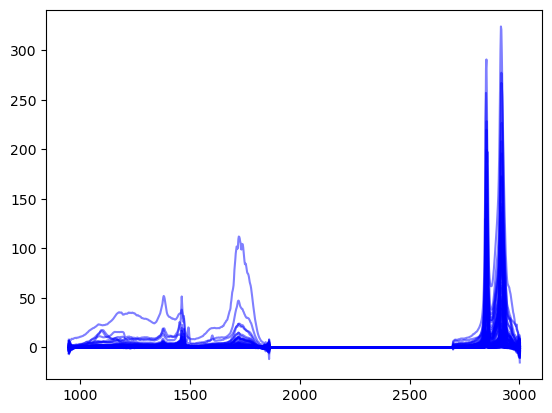

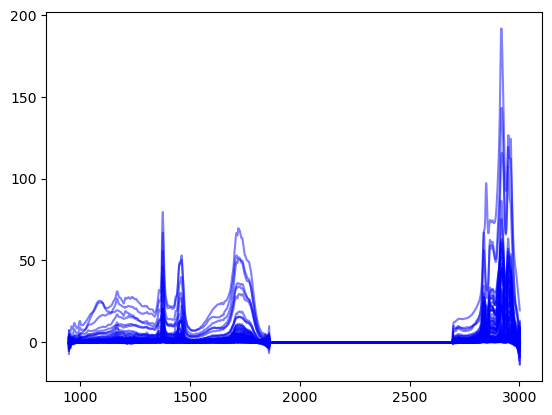

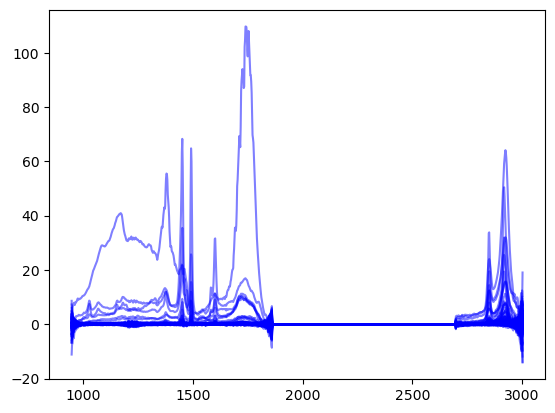

In [68]:
for poly in np.unique(labels['polymer']):
    _ = plt.plot(IR_spectra.query('polymer == @poly').iloc[:,:-3].T,c='b', alpha=.5)
    _ = plt.show()

In [69]:
np.unique(labels['polymer'])

array(['LDPE', 'PP', 'PSL'], dtype=object)

In [70]:
df_list = [[IR_spectra, Raman_spectra]]

In [71]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


In [72]:
ir_final

array([[-5.33373900e-01, -7.15455336e-01, -4.37026875e-01, ...,
         2.43863507e-01, -1.68173840e+00, -1.87571160e+00],
       [-3.85078837e-01, -3.82350565e-01, -3.89339296e-01, ...,
         3.18511418e-01, -3.90180704e-02,  1.54444148e-01],
       [-2.59014887e-01, -2.61691628e-01, -2.60792608e-01, ...,
         2.89841359e-02,  2.89932843e-03, -7.33069315e-03],
       ...,
       [ 5.65725939e-01,  2.51298058e-01, -8.79443319e-01, ...,
         4.25282924e+00,  5.57954780e-01, -1.08736603e+00],
       [-5.96498029e-01, -6.43858145e-01, -6.13417088e-01, ...,
        -1.28577258e+00, -1.01817999e+00, -1.19671683e+00],
       [-2.24918974e-01, -7.46902692e-02,  3.53117423e-01, ...,
        -4.89623219e+00, -5.17213853e+00, -4.62652599e+00]])

0.031932587293305524


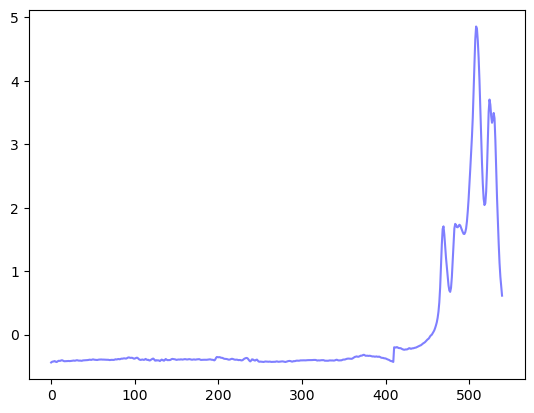

0.032661204186129694


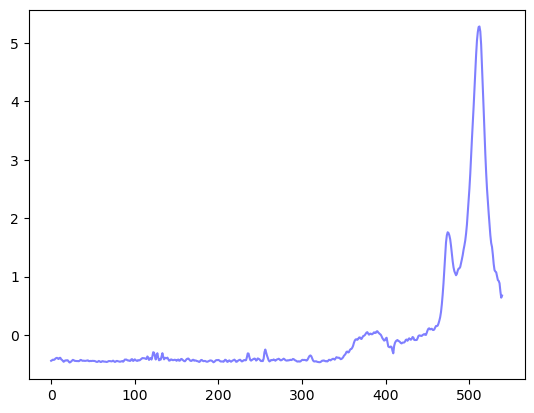

0.03606390314210457


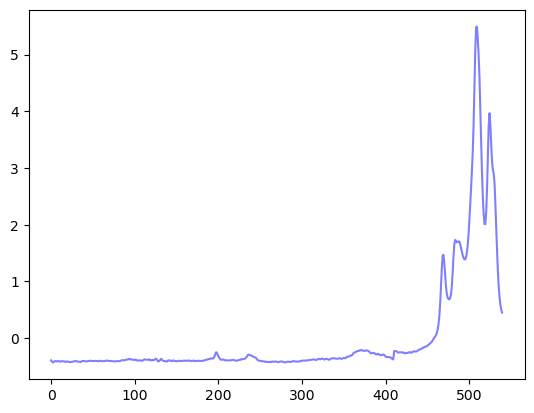

0.03682849092902388


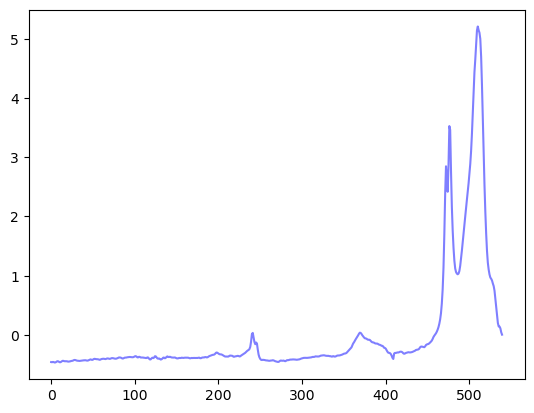

0.03765868140425067


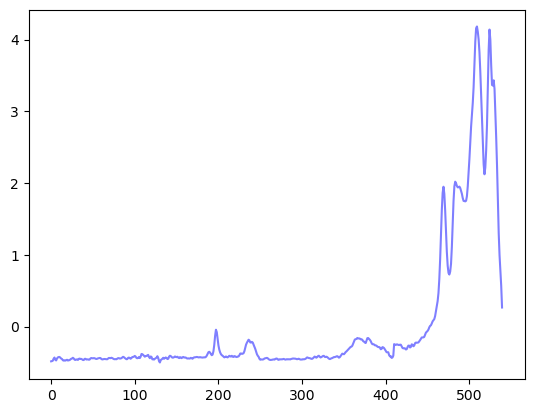

0.03886113365141998


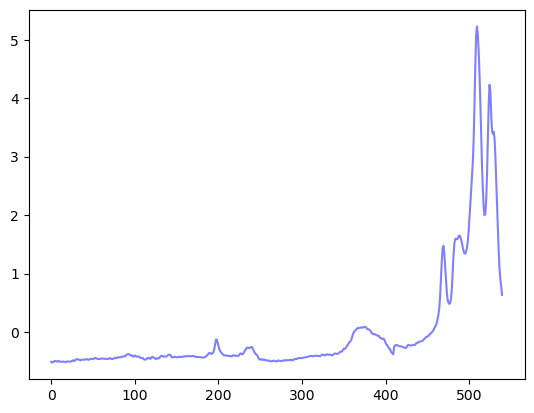

0.040197922695030606


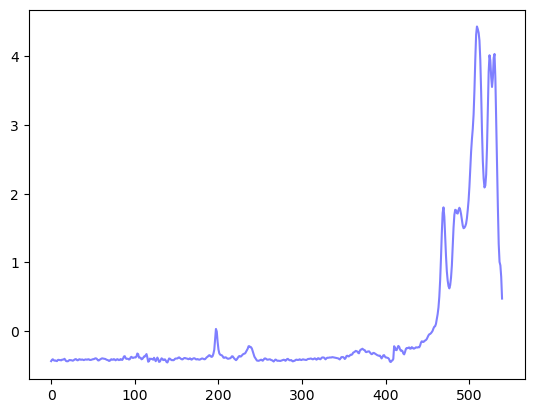

0.0409450621907571


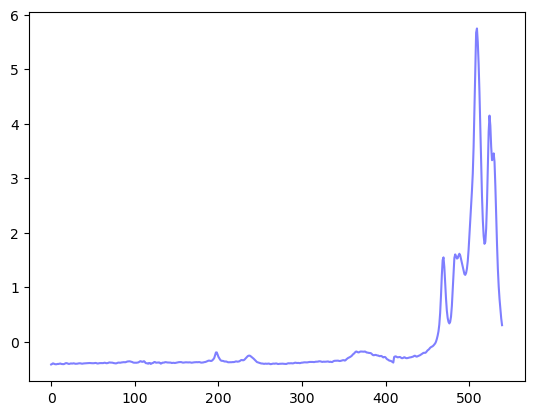

0.04155316654517145


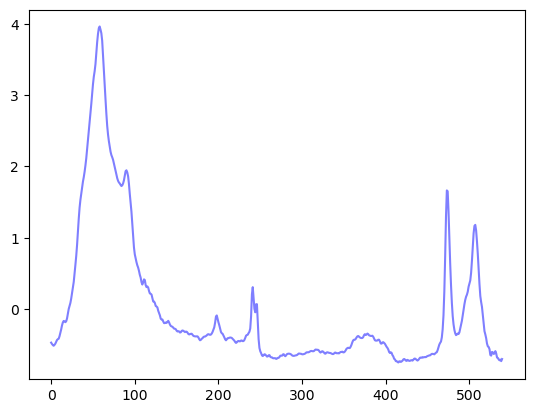

0.044287951531924864


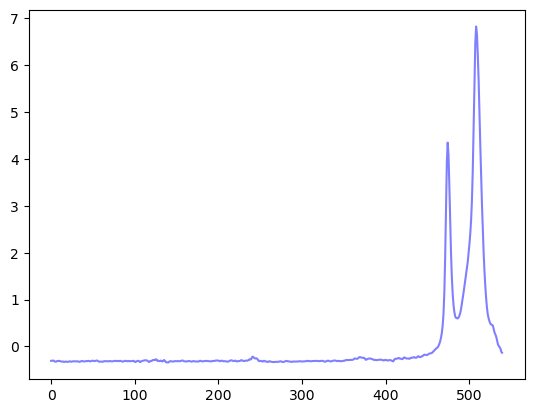

0.044819776436315115


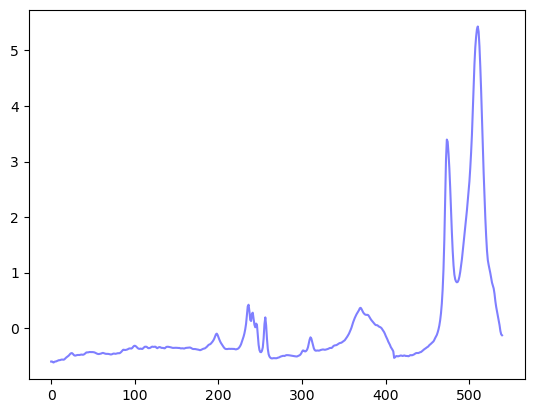

0.04586044326159849


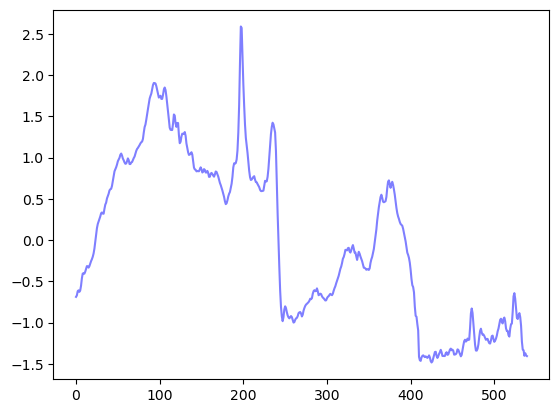

0.0458796871321604


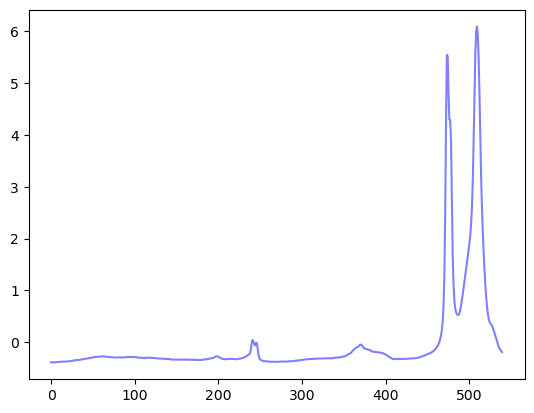

0.0459834642113768


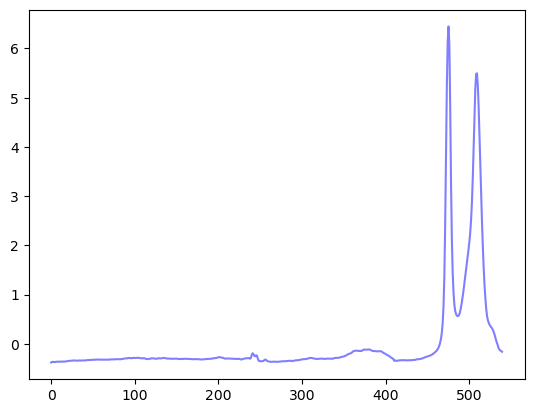

0.0464330263428744


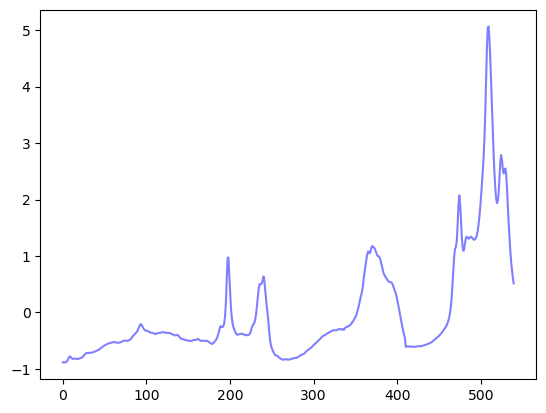

0.04649639975279918


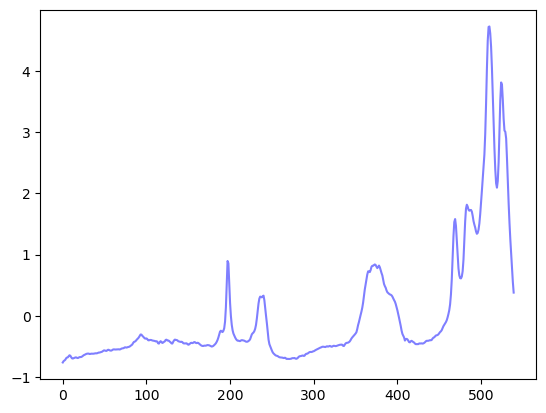

0.04669496438112194


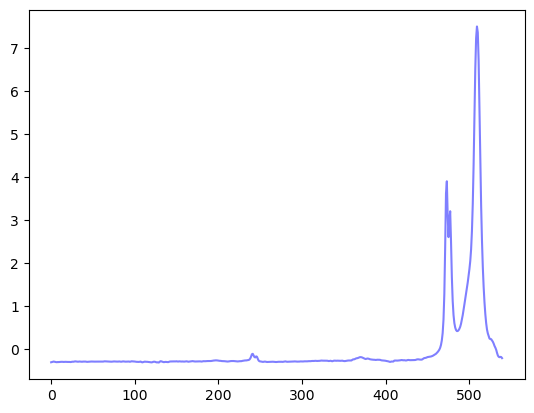

0.04681753466263351


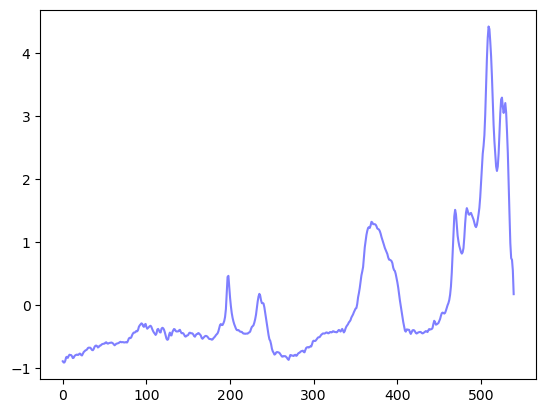

0.04747458175136978


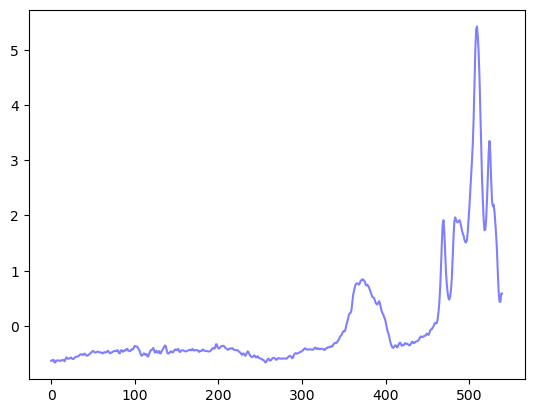

0.04761355917163967


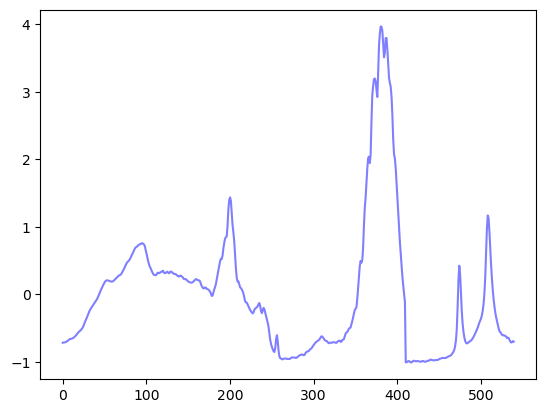

0.04851568765034552


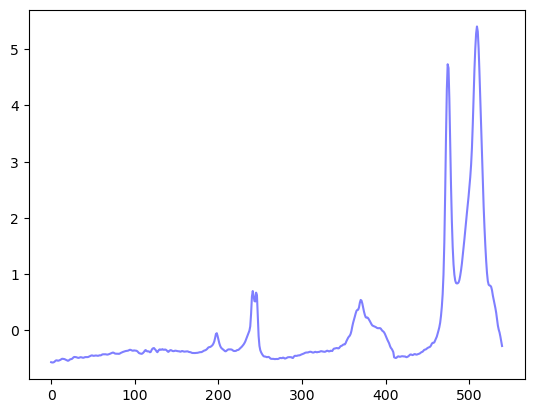

0.04862505702983145


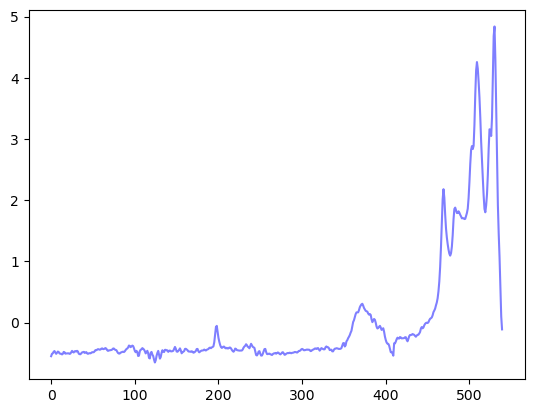

0.04879782680577387


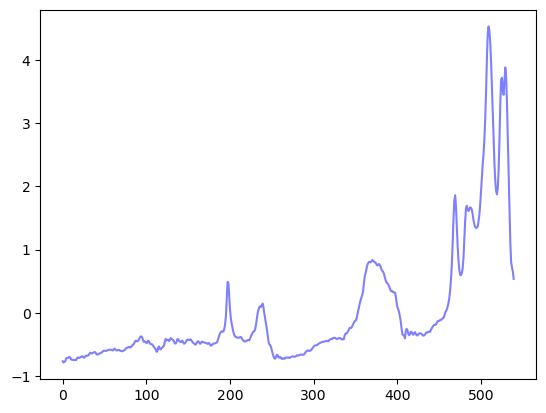

0.0488041492065707


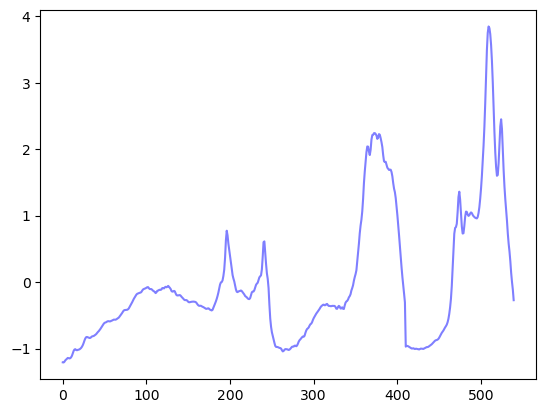

0.049299778251592936


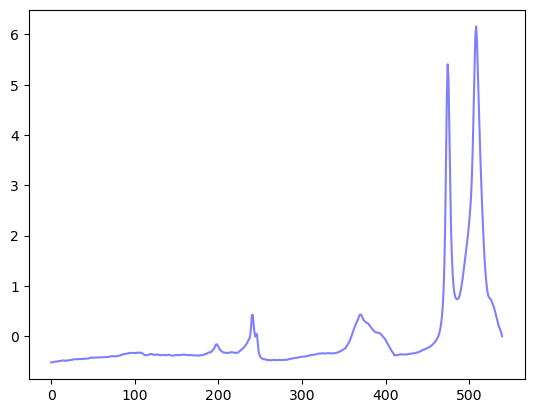

0.0493522496101385


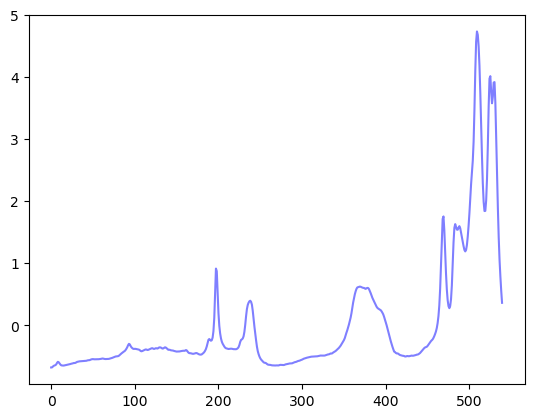

0.050895162775293705


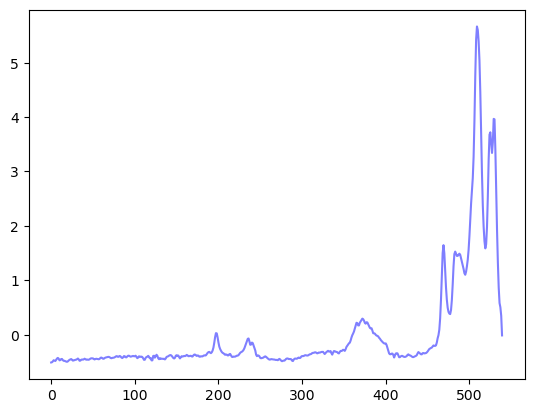

0.050961024652877


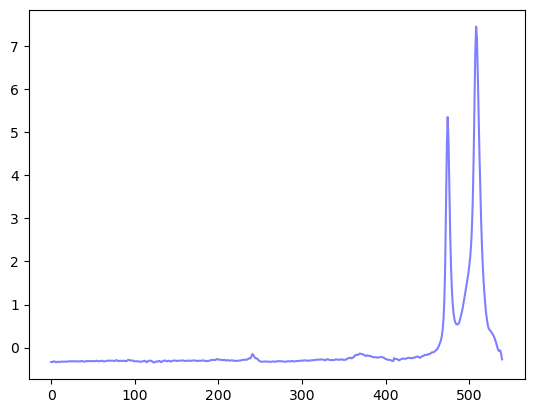

0.05137402317924233


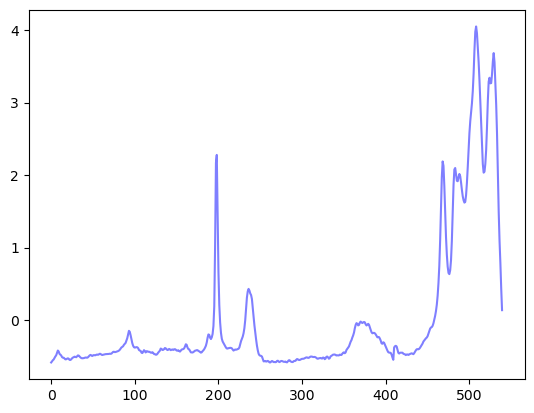

0.05141150852947093


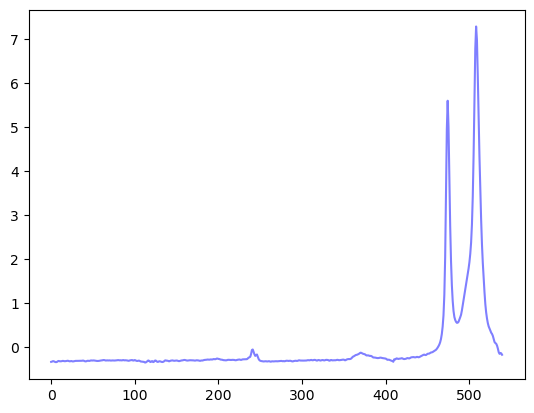

0.05162430933801501


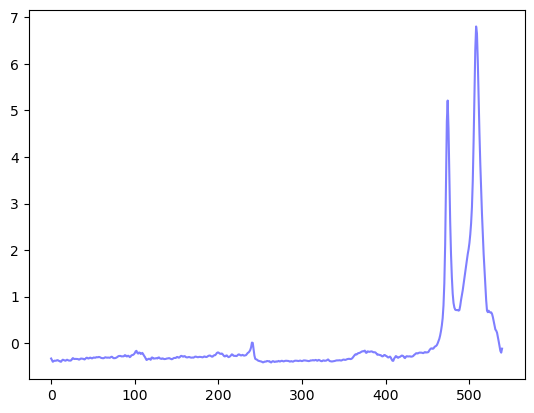

0.051793847303776404


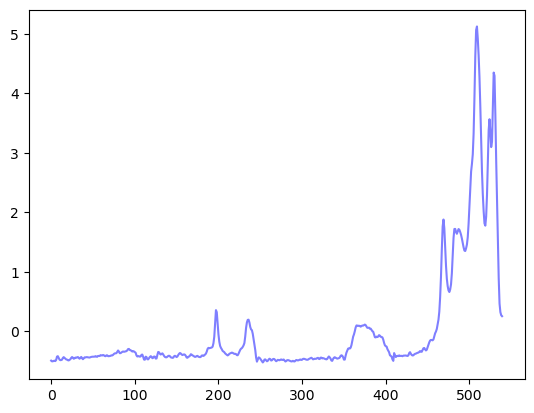

0.051864974619036726


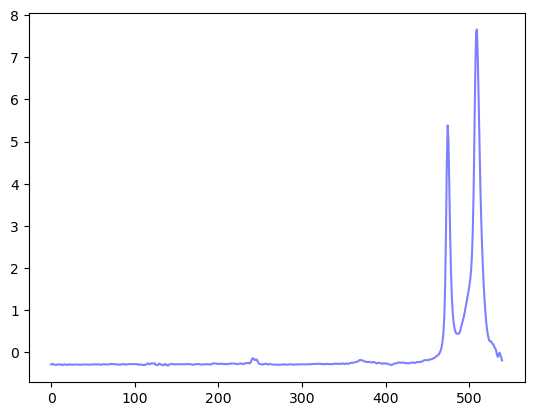

0.05195169339033366


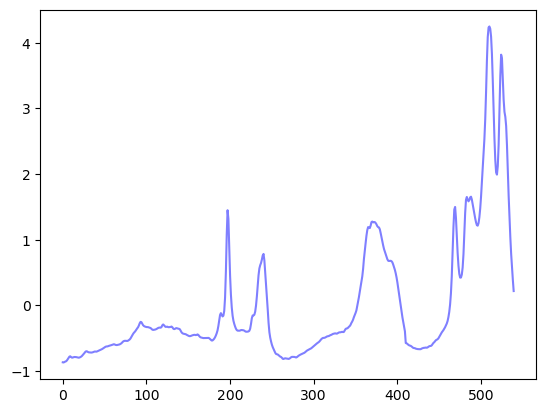

0.05272454628128787


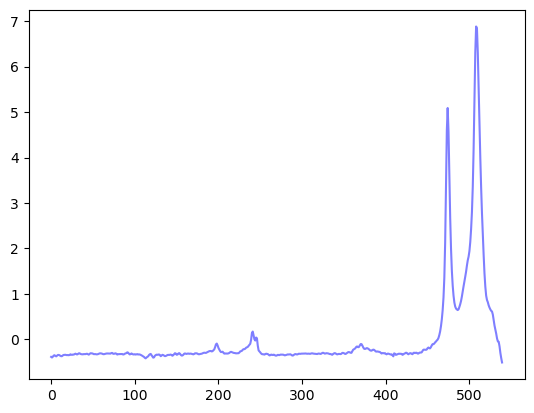

0.0528132300314637


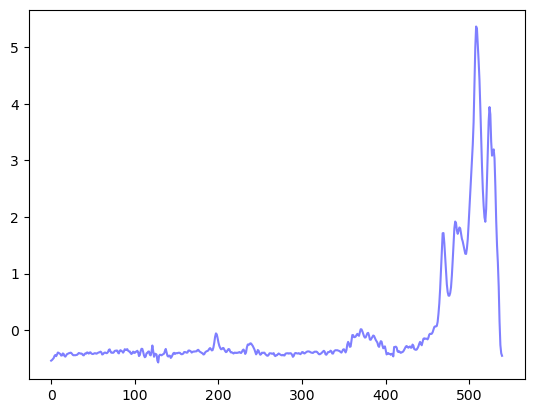

0.05299765200912958


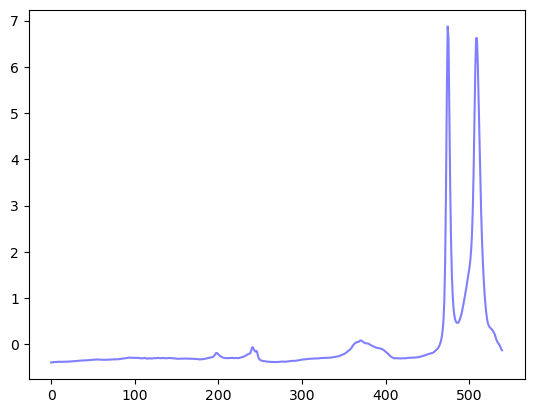

0.05303980625008866


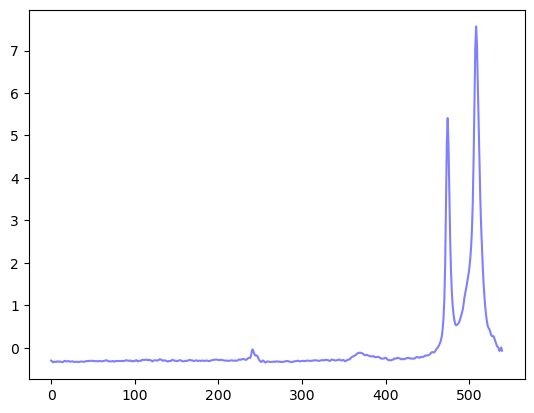

0.05319171402031474


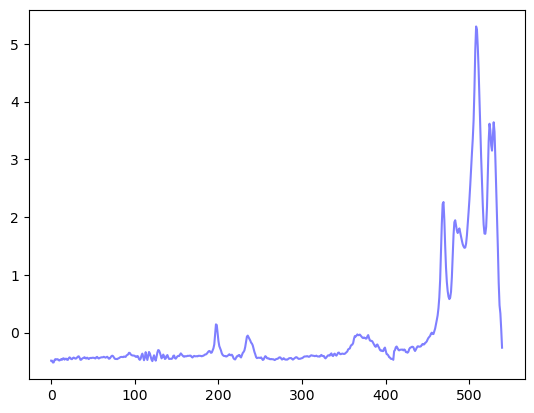

0.05348015572632642


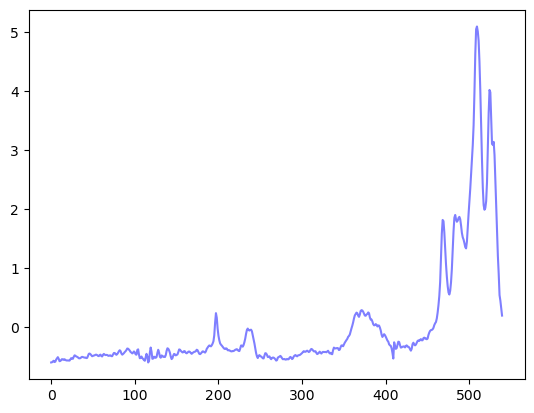

0.05348049674891446


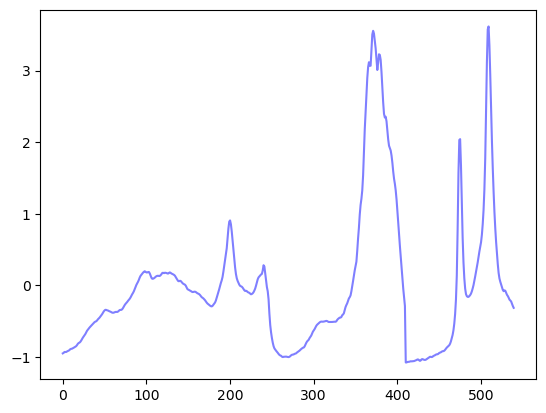

0.05348726486002636


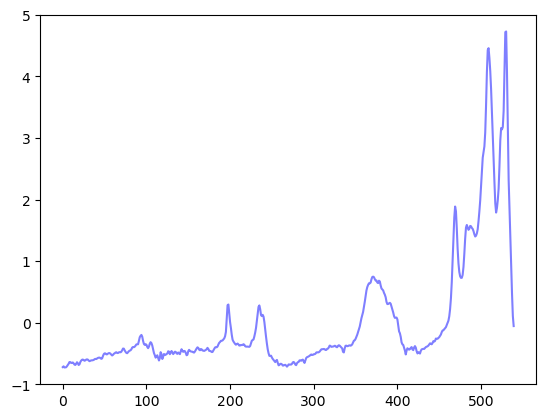

0.053682064822848485


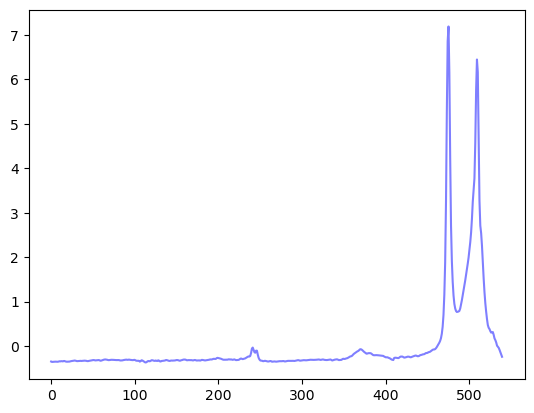

0.05417252339010114


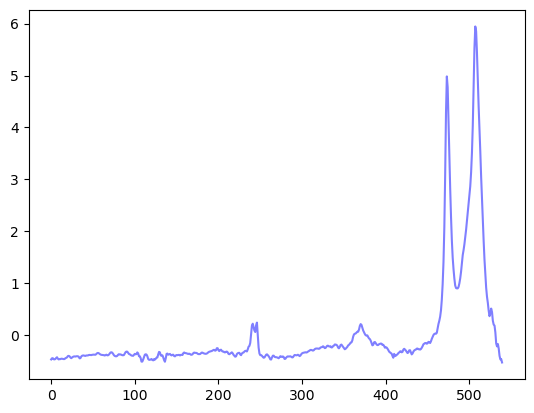

0.054229887311703626


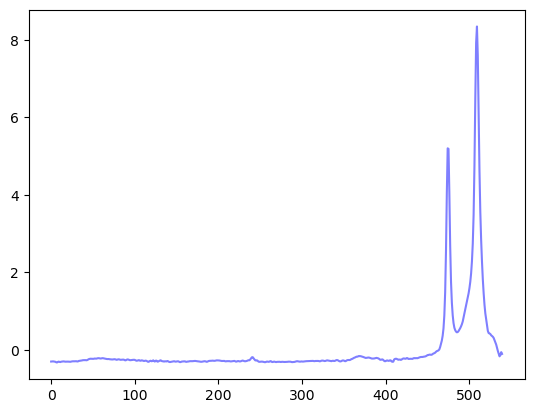

0.054474507451257946


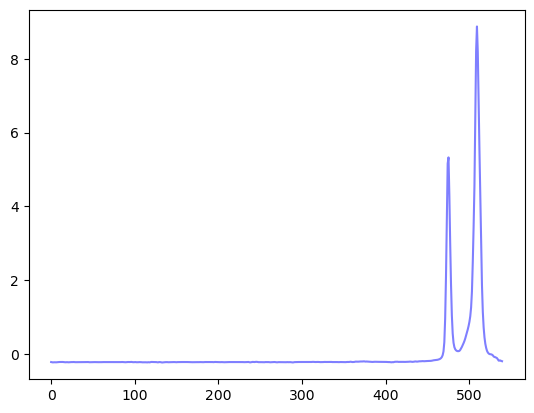

0.05501845408071824


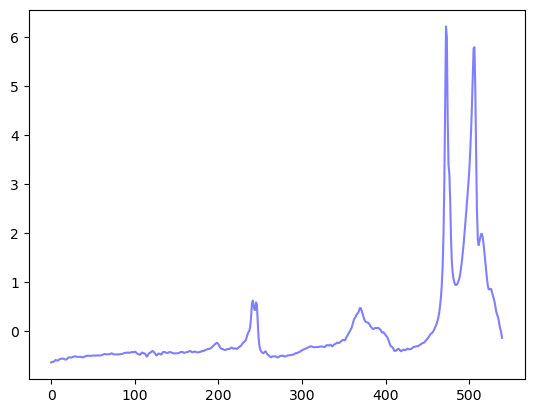

0.05518663615629646


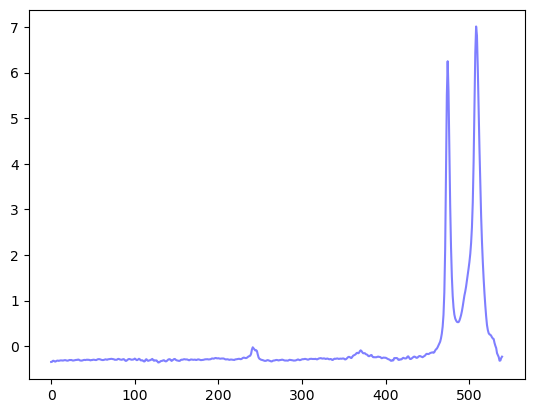

0.05541731131681005


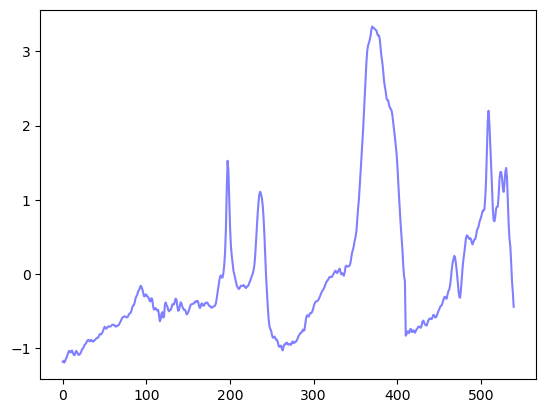

0.055771371136159056


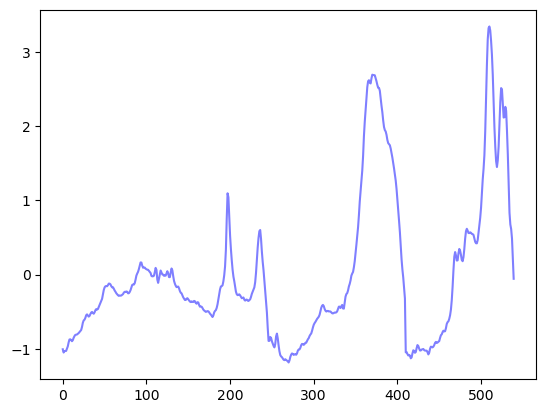

0.05614316298137732


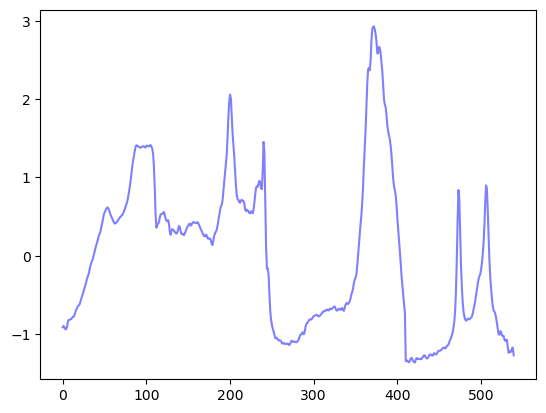

0.056229582624837855


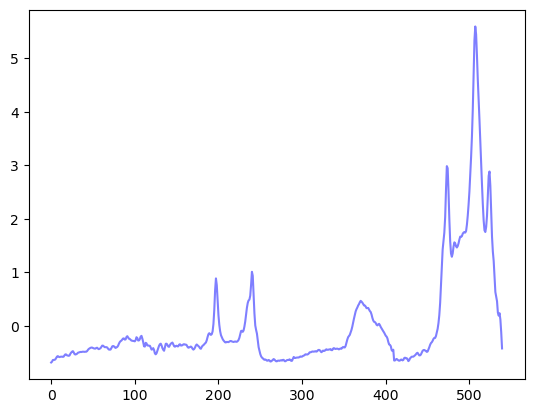

0.05656747566535201


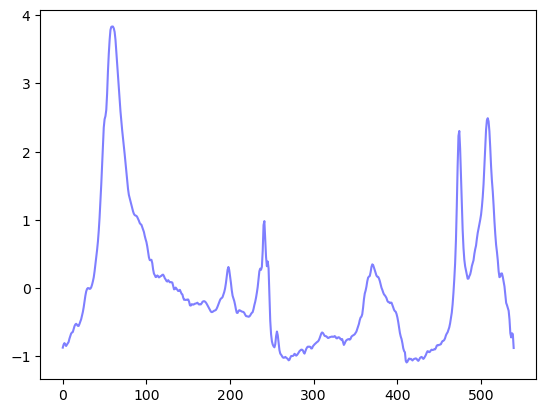

0.05665460943237964


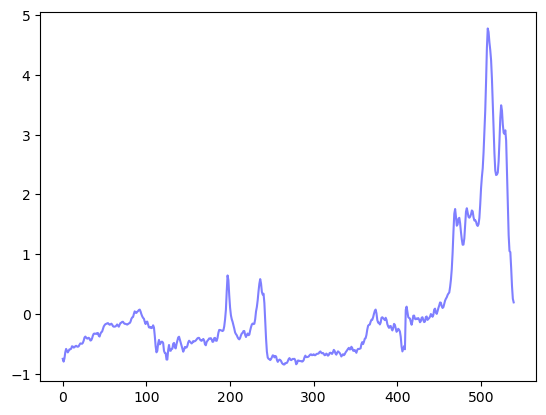

0.05667537017524355


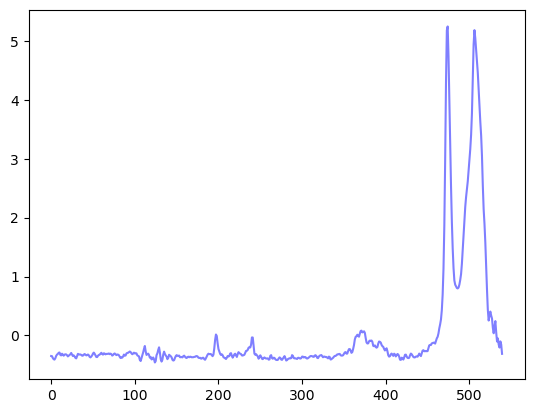

0.05792388449406538


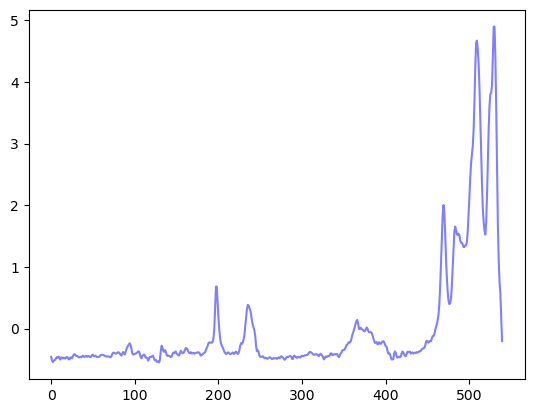

0.05820835566531776


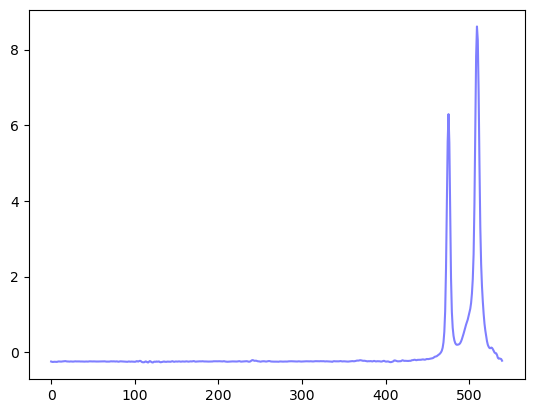

0.05822609229544133


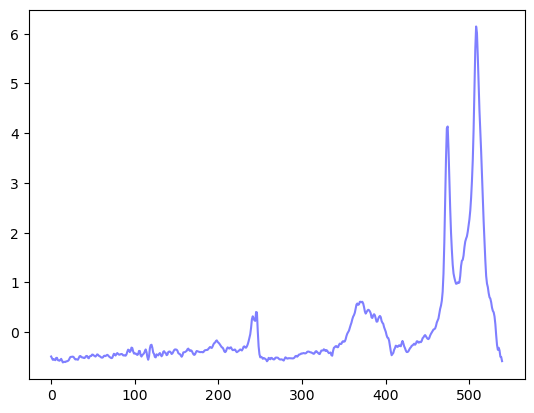

0.05827977117573442


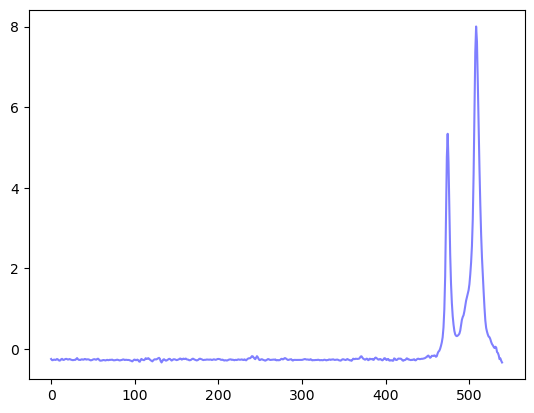

0.058941818038182325


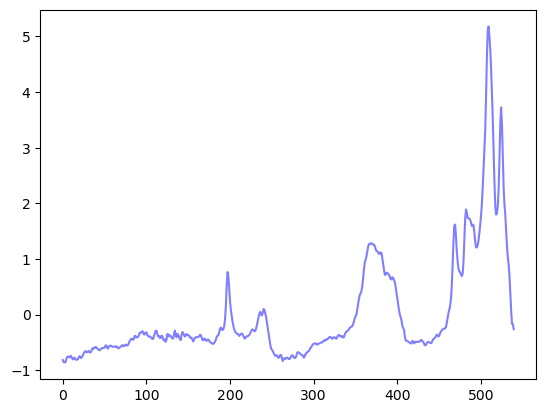

0.05915812238636987


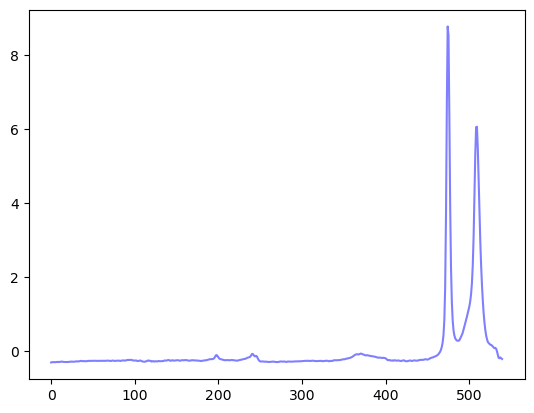

0.05924079000042602


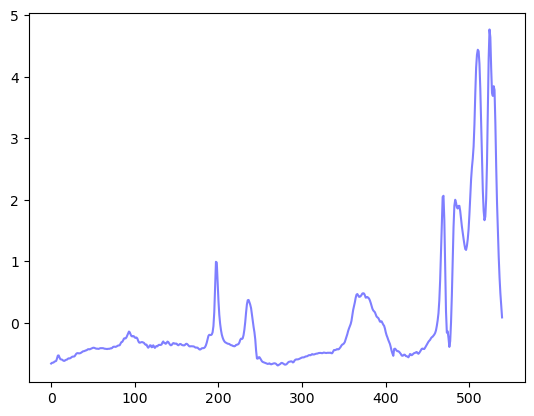

0.05955999516542889


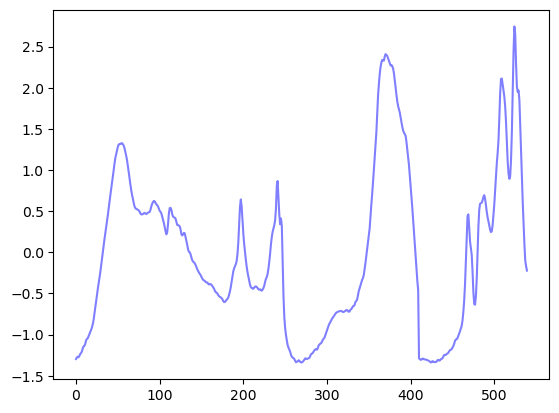

0.06161431955058893


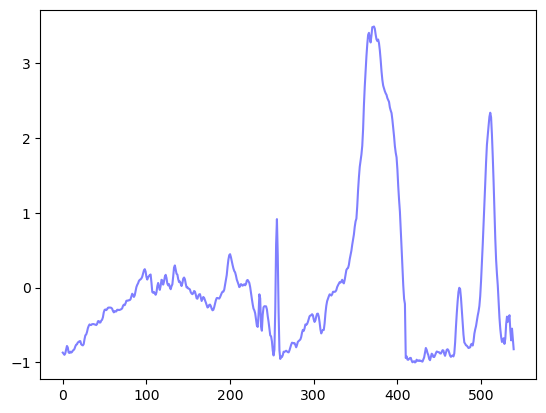

0.061980894194265015


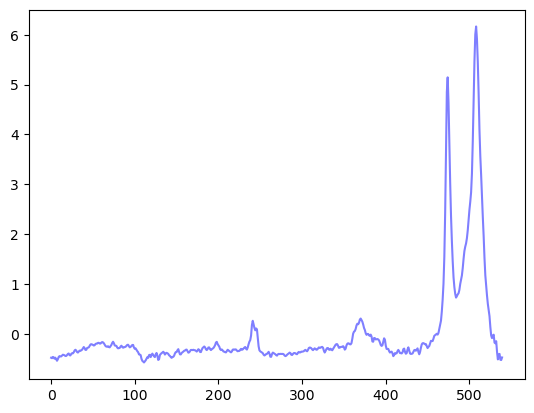

0.061999376545525384


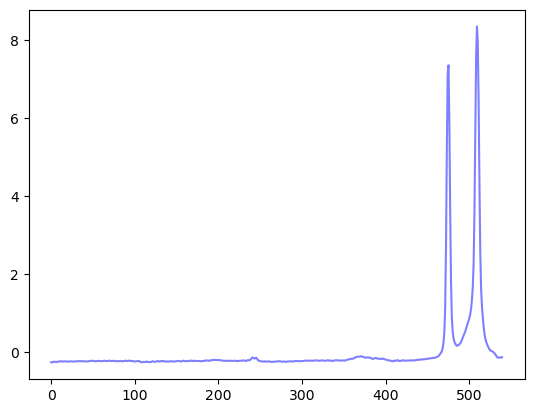

0.06221005650552695


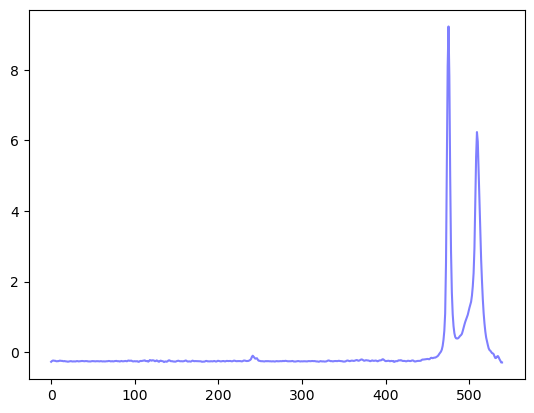

0.062282482118642395


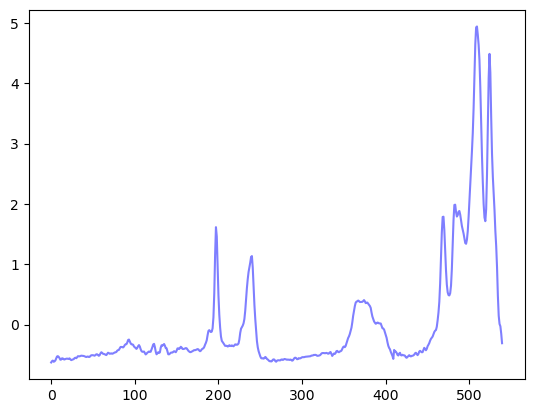

0.06233308646564432


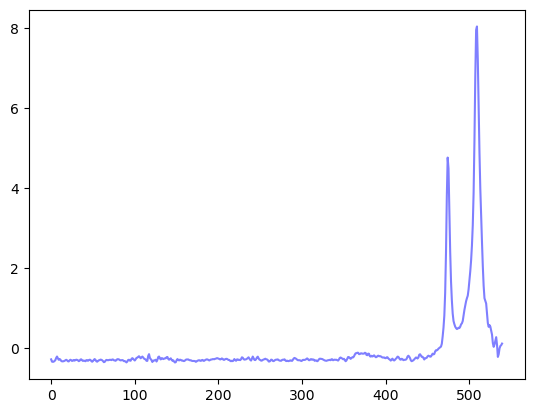

0.0624391311436532


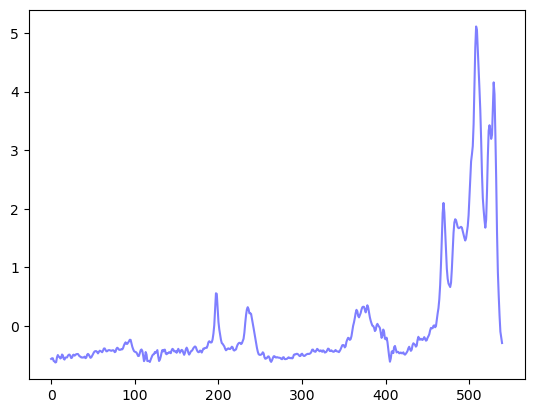

0.06403031951592474


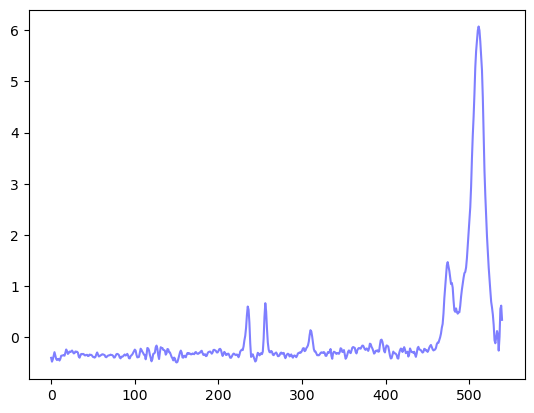

0.06425591370883095


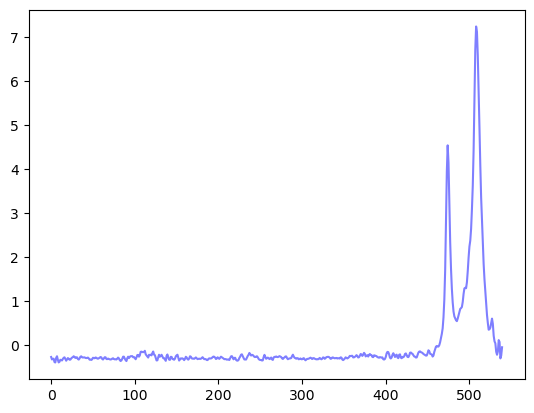

0.06501186259429695


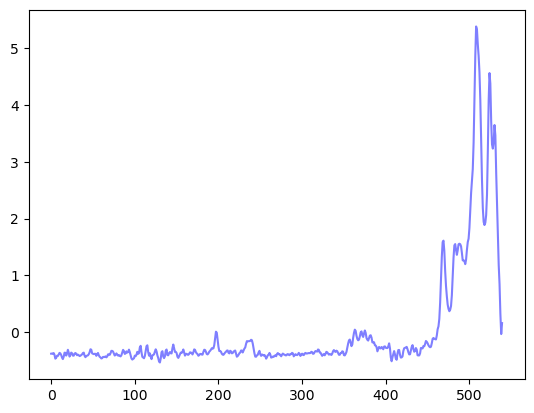

0.06528848087157477


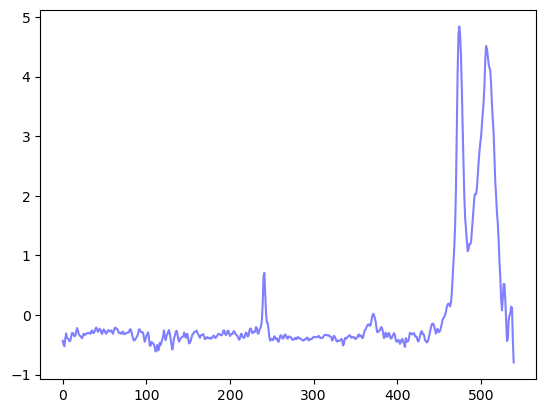

0.06537791206344049


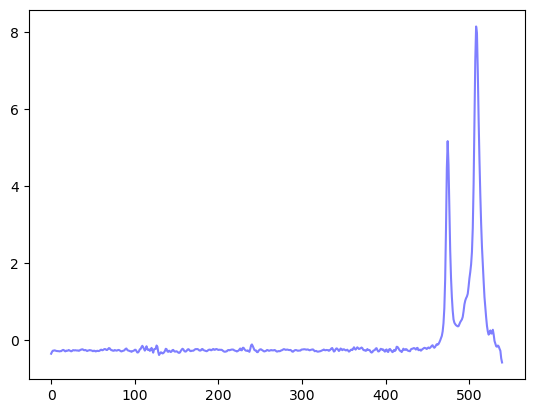

0.06539390523337975


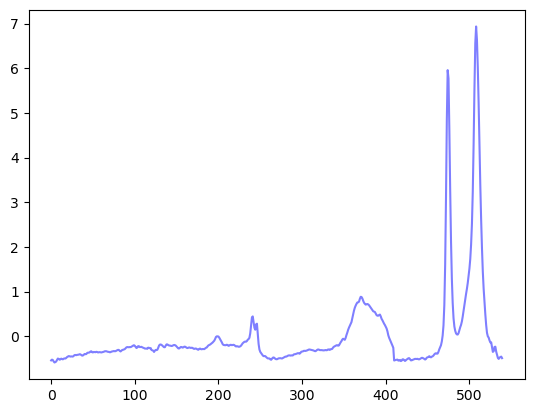

0.06598092377214428


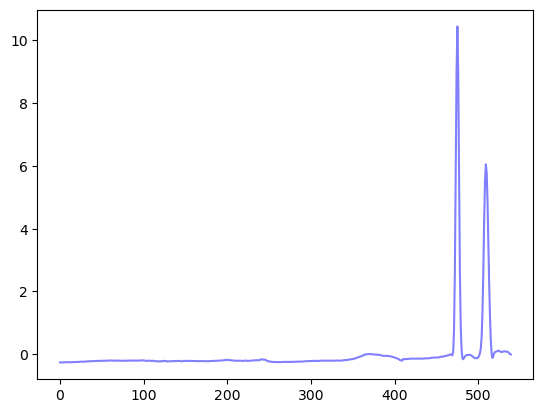

0.06630959466887401


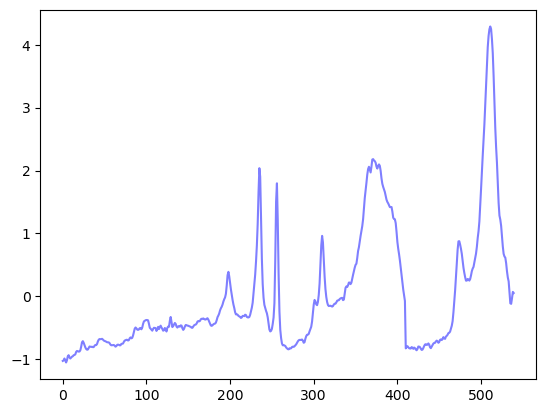

0.0667158560876008


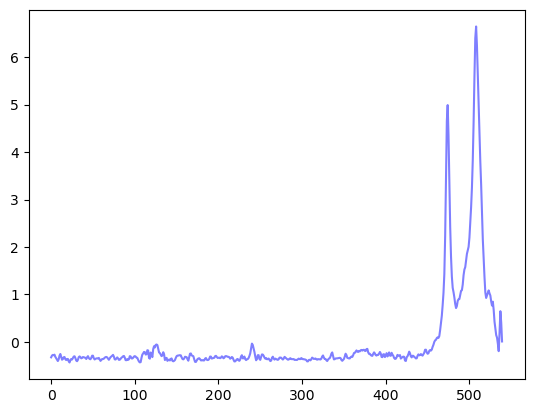

0.06734590890237155


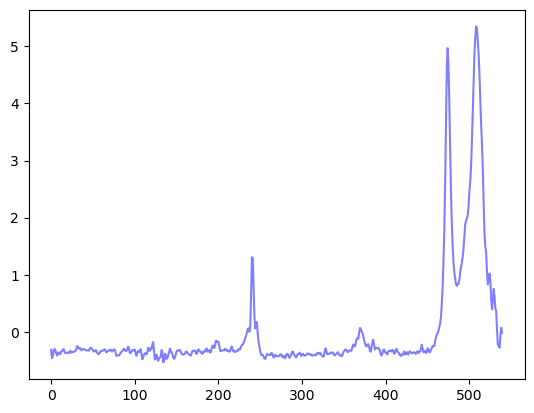

0.06773163969198129


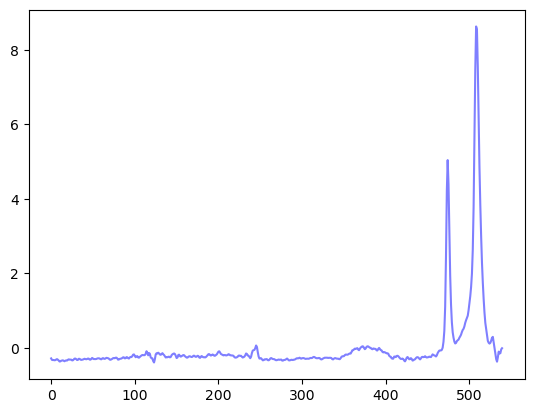

0.06795116132950842


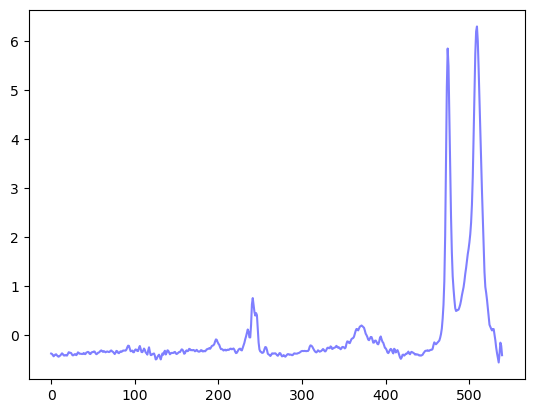

0.06852175883816675


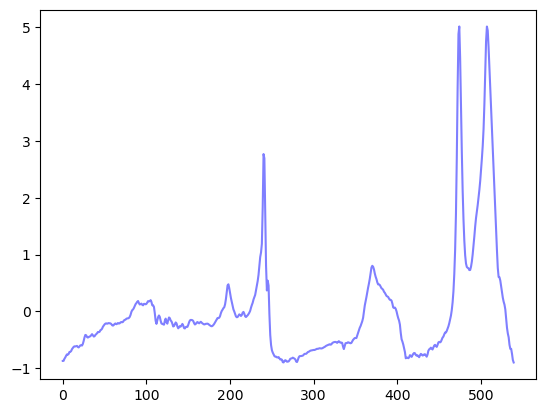

0.06867741007505146


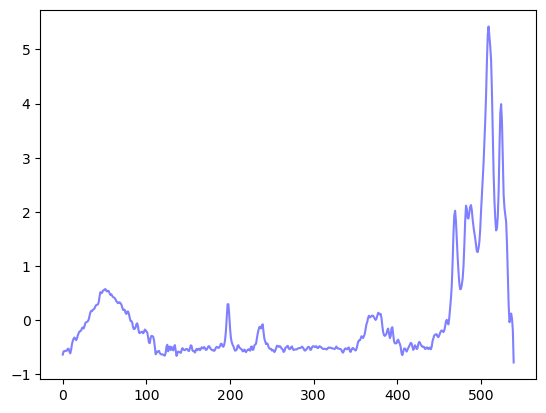

0.06911305500711272


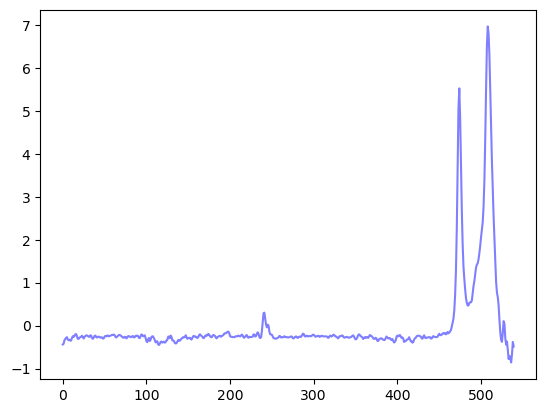

0.06973426709820023


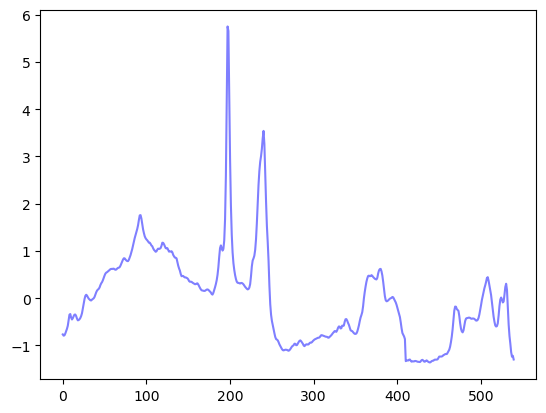

0.07019749084909516


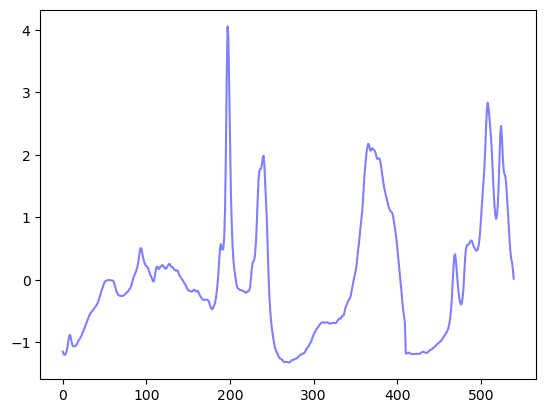

0.07092725073616557


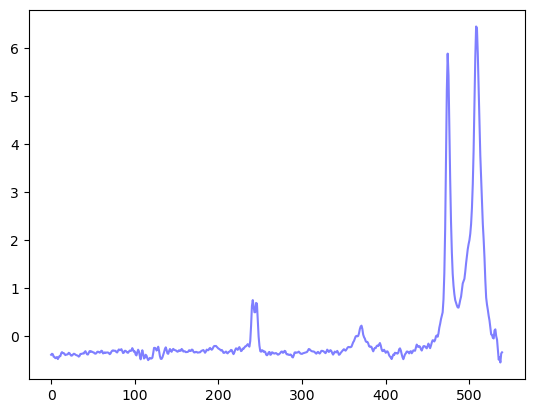

0.0709378884332151


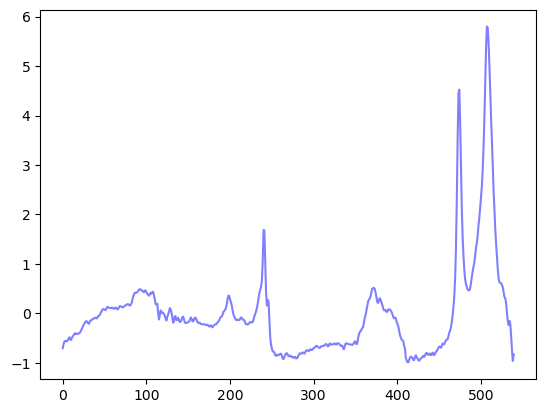

0.07123178071078133


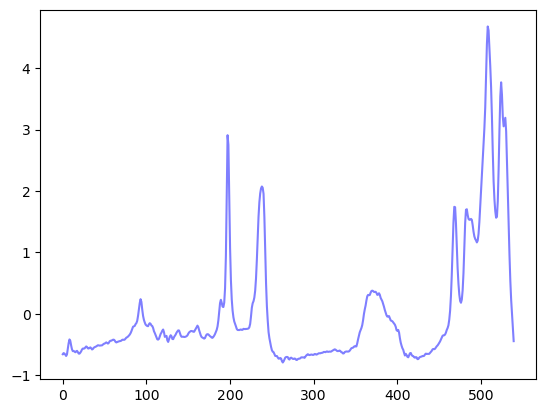

0.07286245763813369


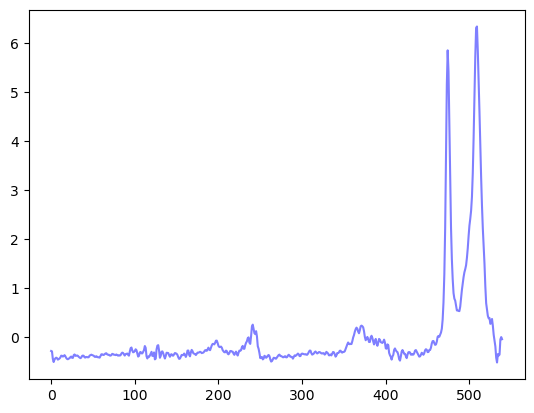

0.07386090062556809


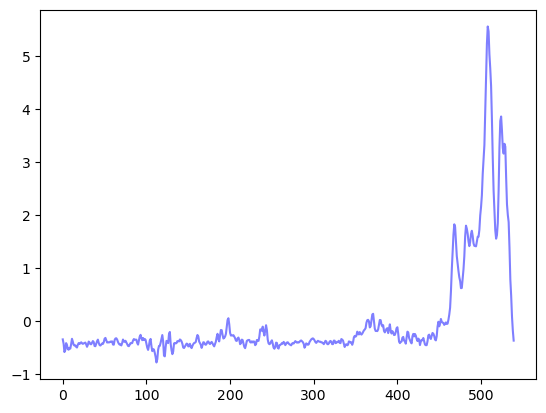

0.0738834845310024


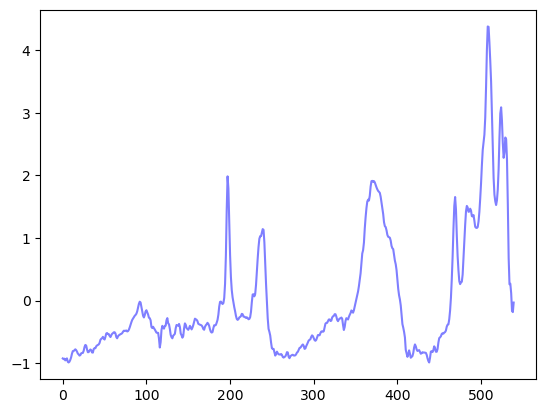

0.07401089328855989


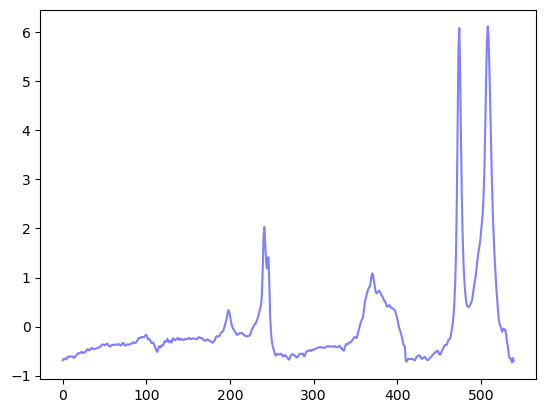

0.0747271781308054


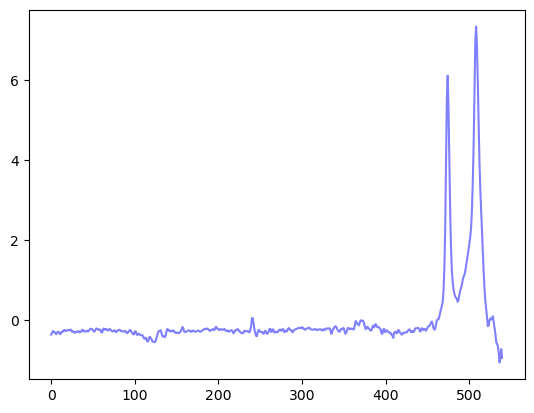

0.07485855819350326


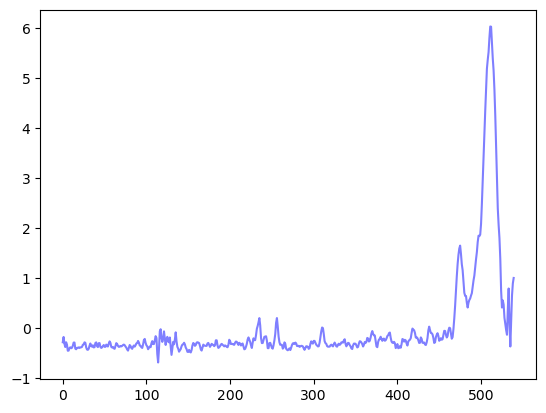

0.07580578221559786


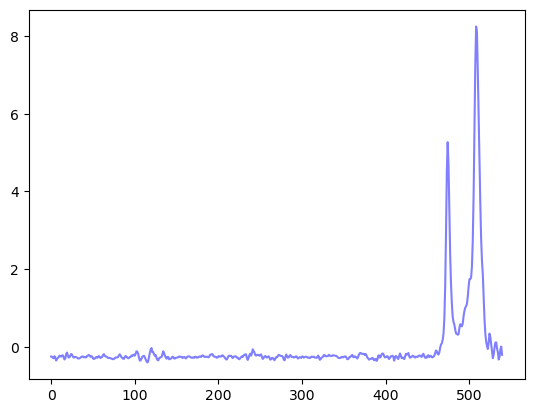

0.07696709962352472


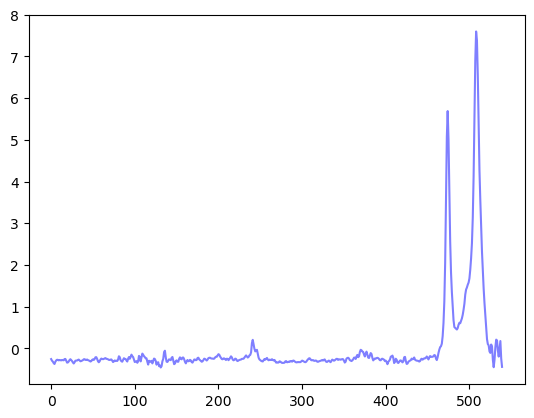

0.07733530761929769


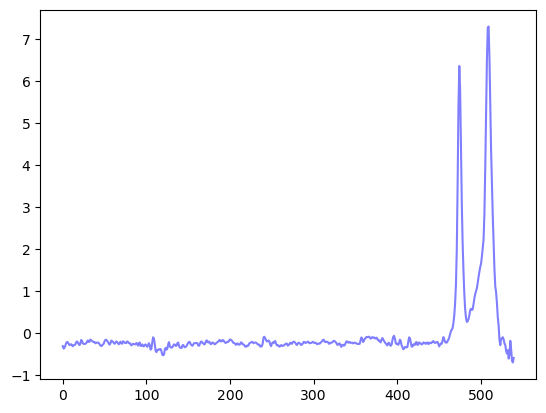

0.07778896995379202


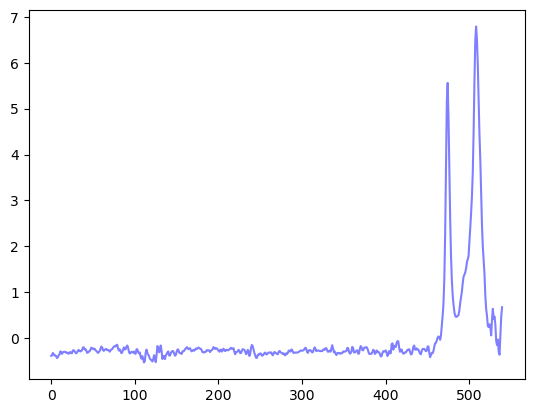

0.07866234633336726


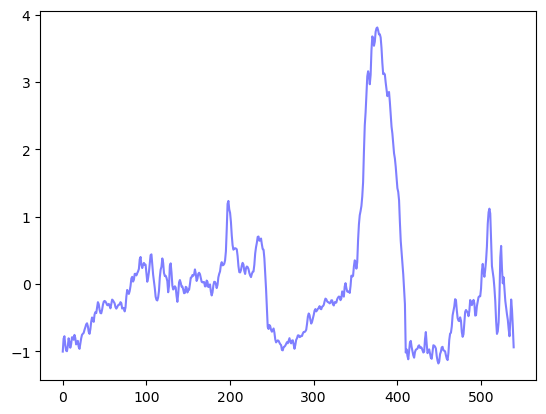

0.07944472694669368


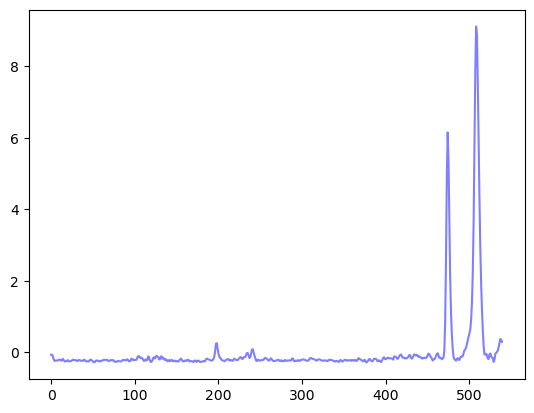

0.07998168487667535


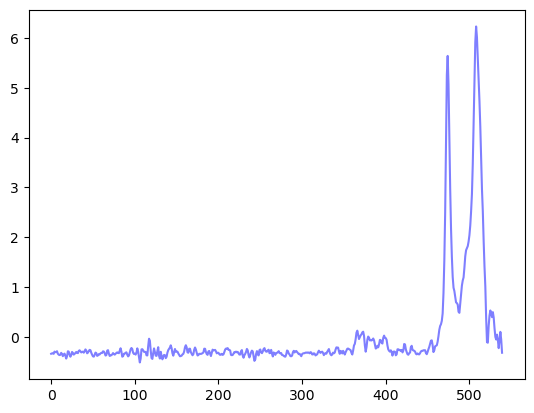

0.08054685257382735


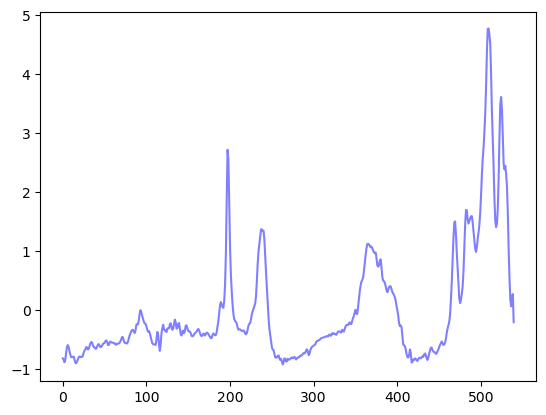

0.08160958482729679


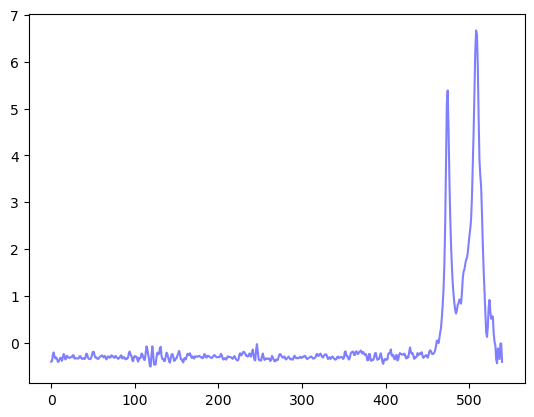

0.08189662021582762


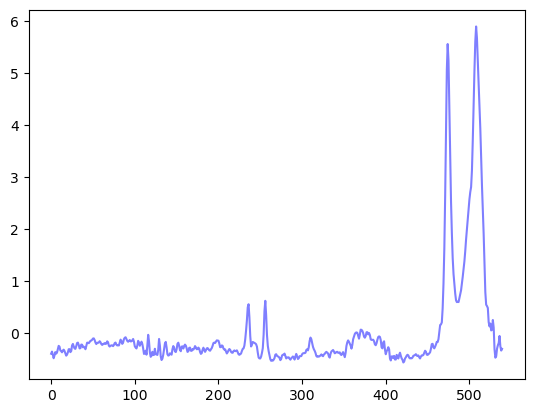

0.08226273077847517


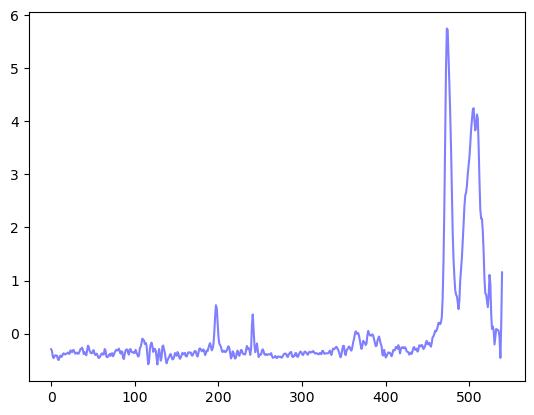

0.08337867243771249


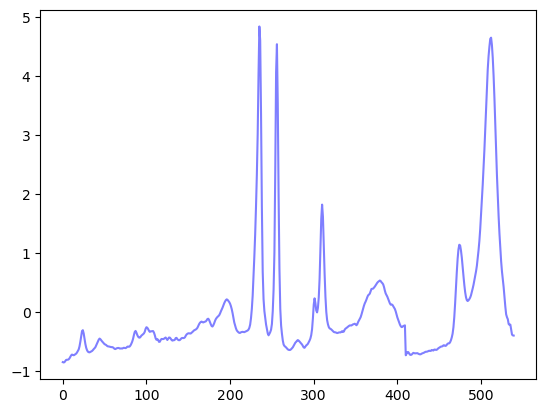

0.08379755139599886


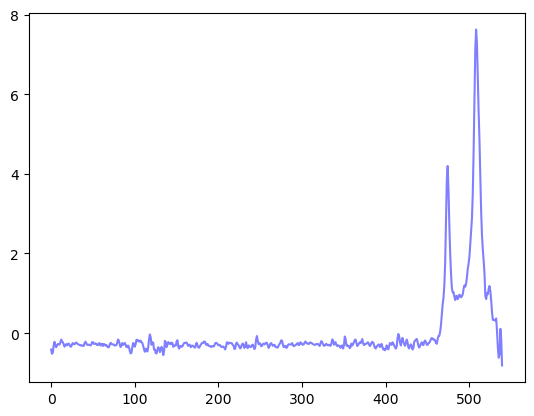

0.08438341801063569


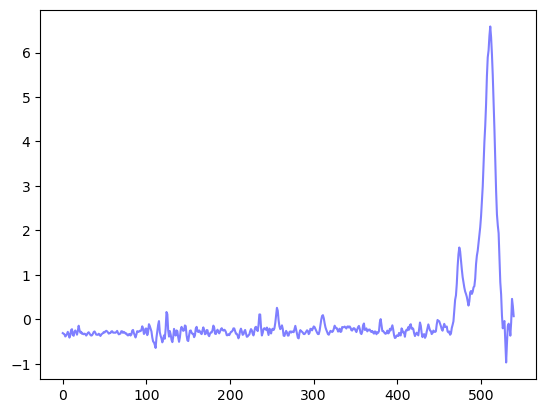

0.0852035455247809


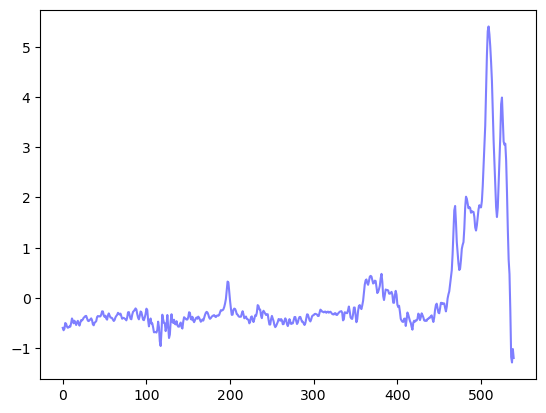

0.08529859673390038


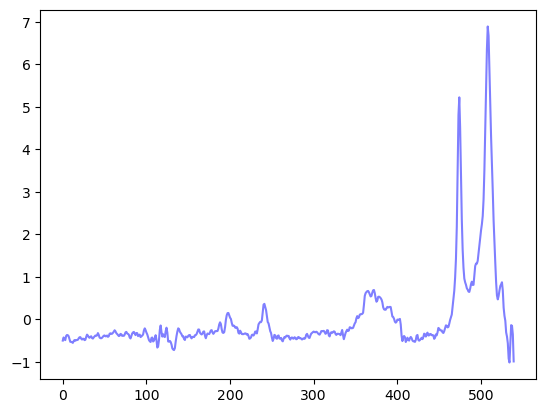

0.08548991340292403


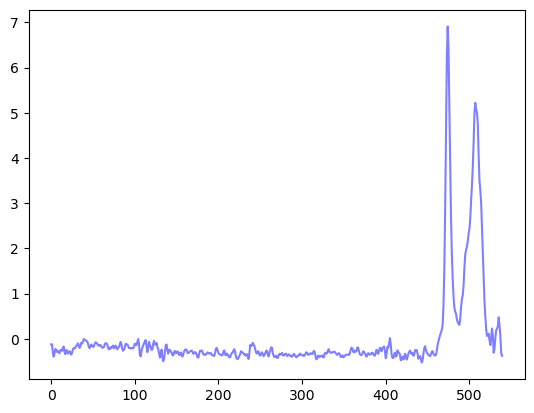

0.0862367964438723


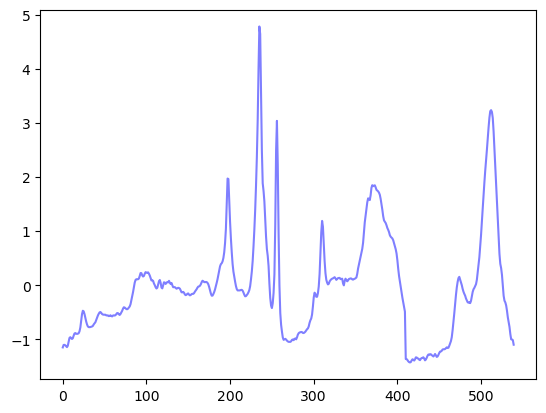

0.08886178512809491


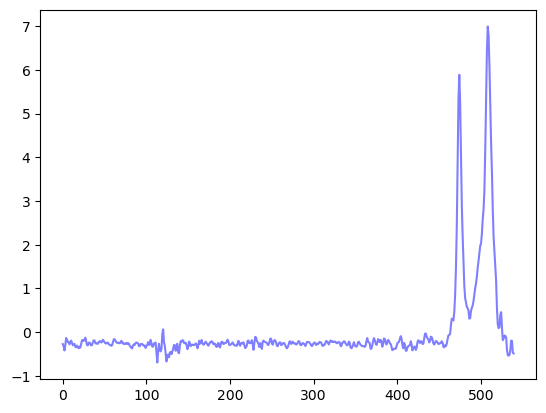

0.08902408297857105


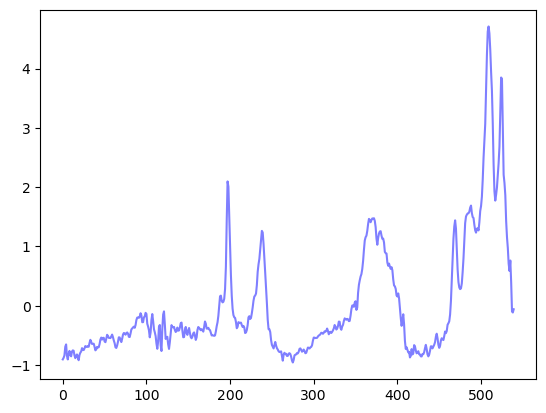

0.09174083246034165


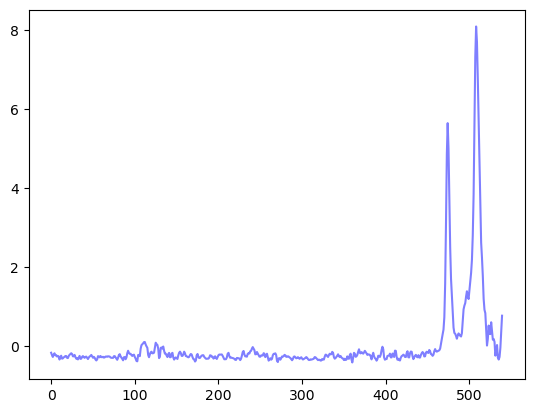

0.09251963638619702


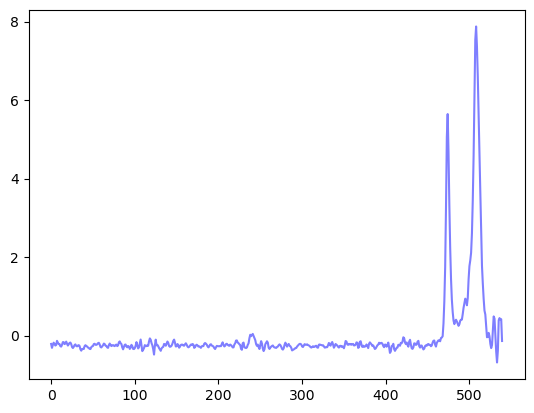

0.0933842989457511


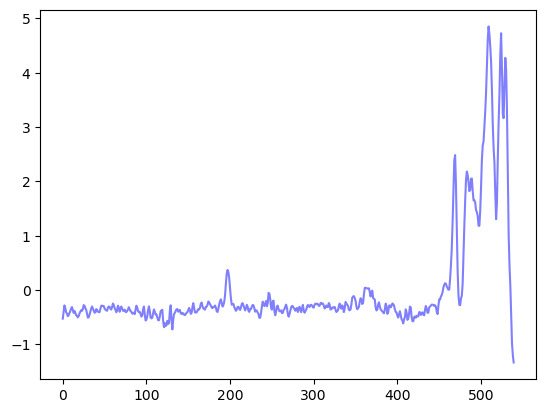

0.0942018612387089


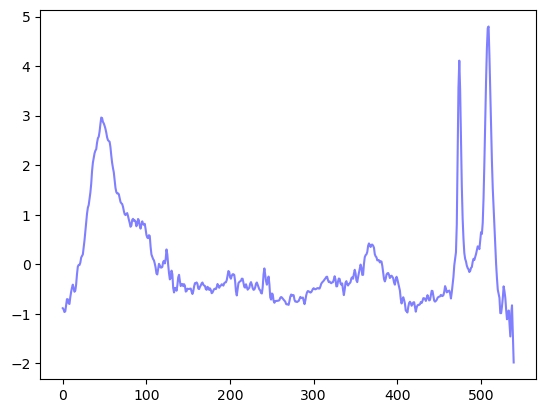

0.09424415451357979


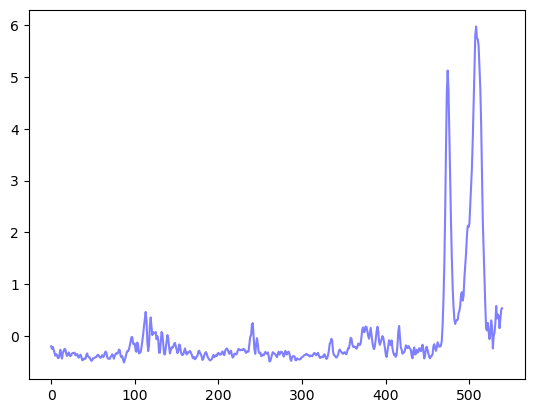

0.09531939523954834


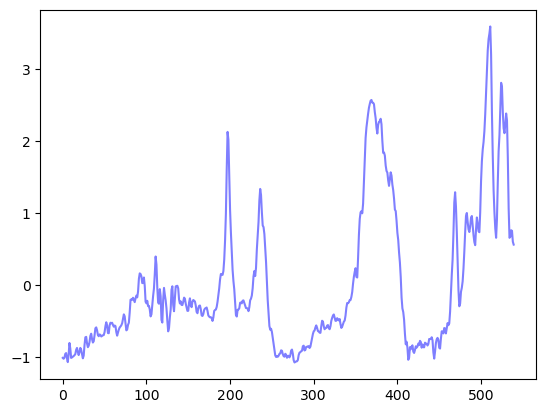

0.0964195909351421


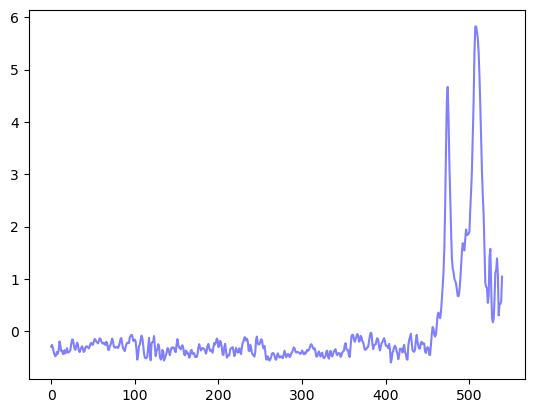

0.09770406393654411


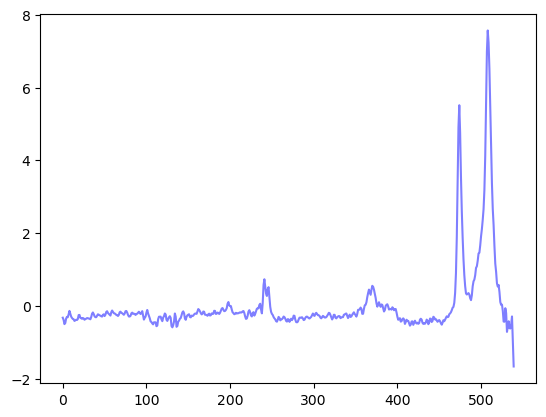

0.09783149051982544


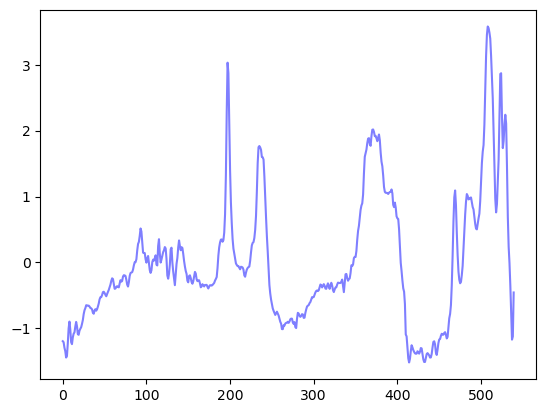

0.09896791692186739


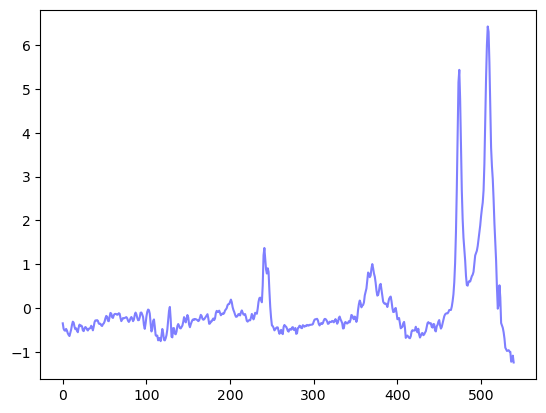

0.09936144470115654


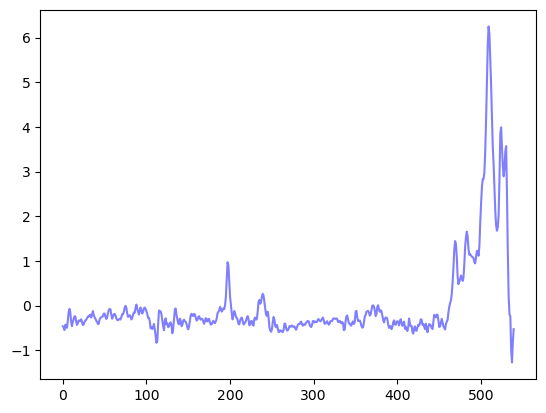

0.09994971564326609


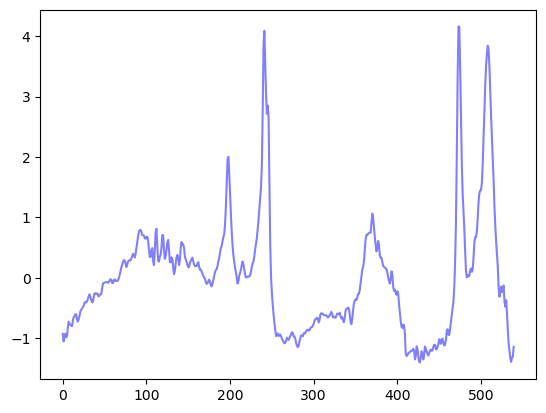

0.10096105597851775


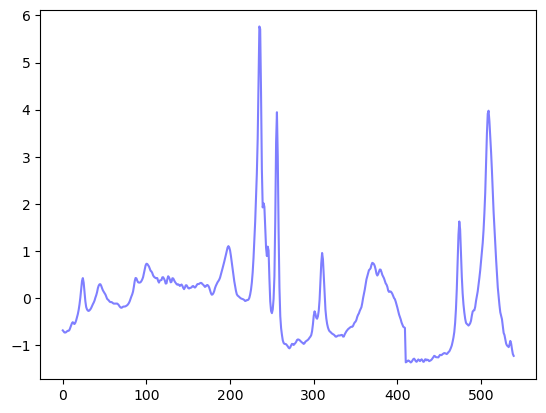

0.10112496109293903


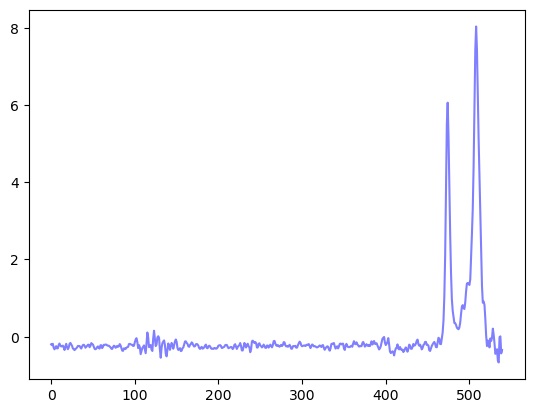

0.10386057553010072


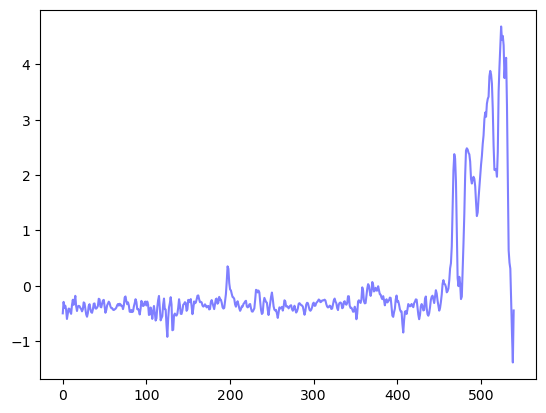

0.1053679771948147


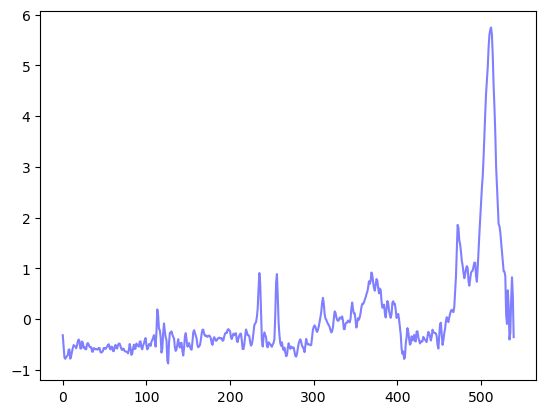

0.10625993360175684


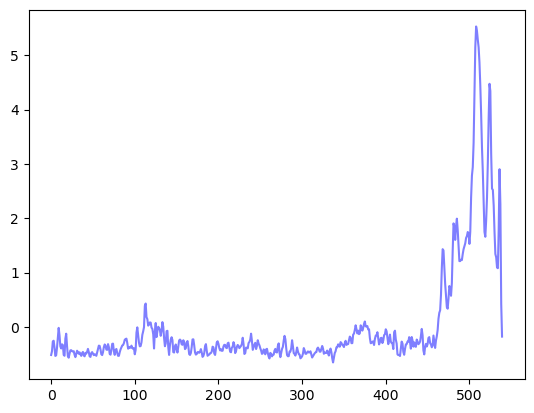

0.10670667853218756


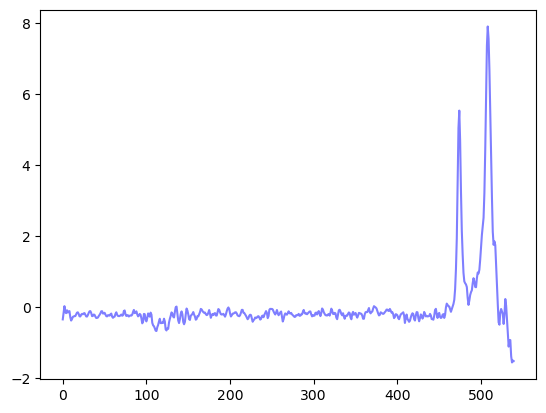

0.10701566797306362


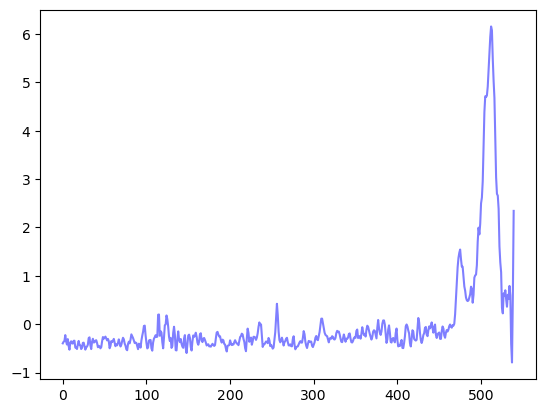

0.10755447754762175


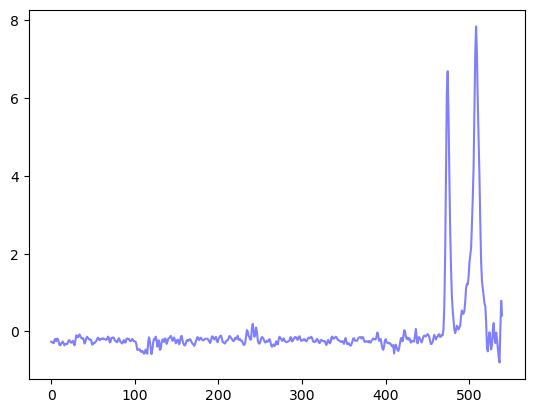

0.10764971693691996


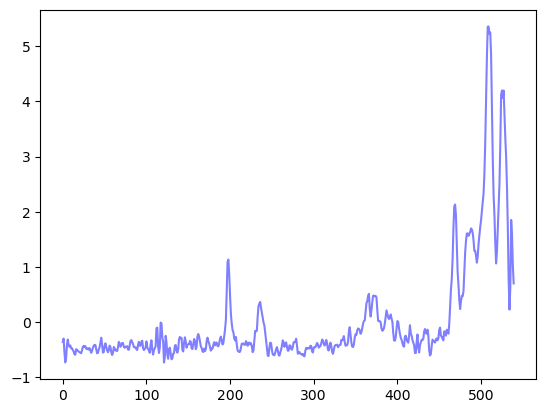

0.109568849161912


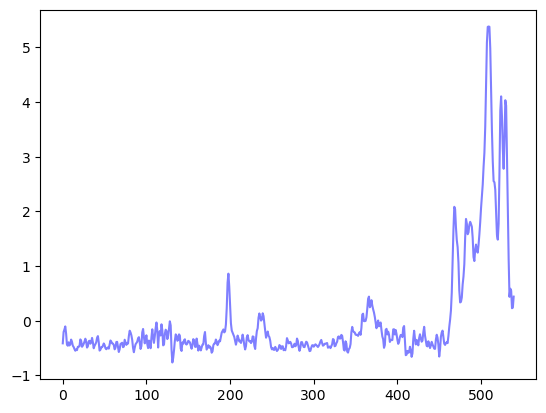

0.10999625392535343


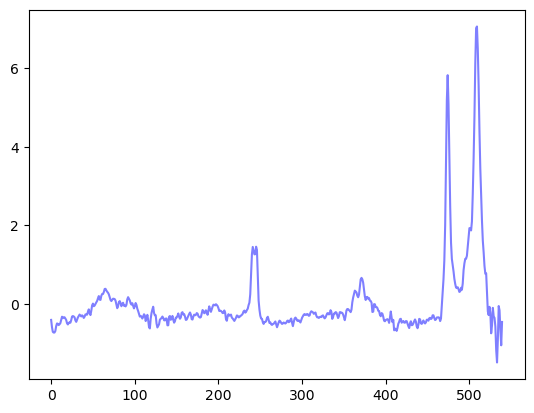

0.11040591356213453


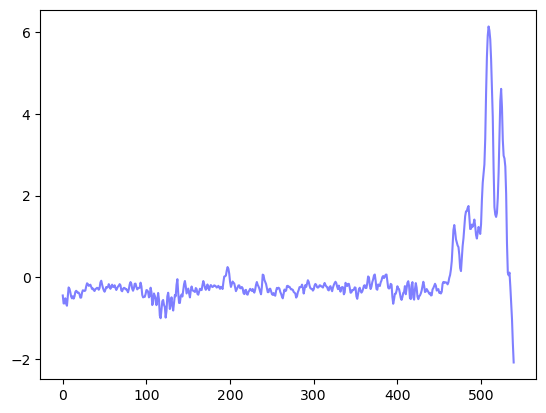

0.11184029923038669


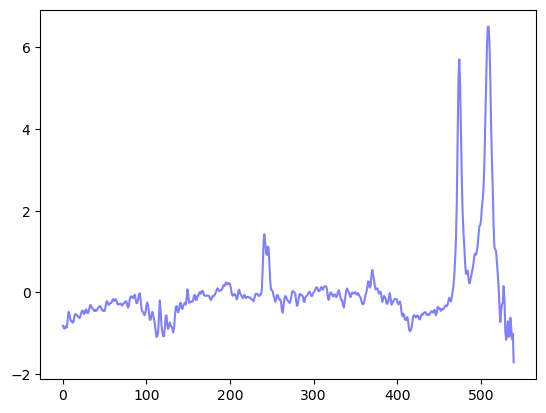

0.11345404847415352


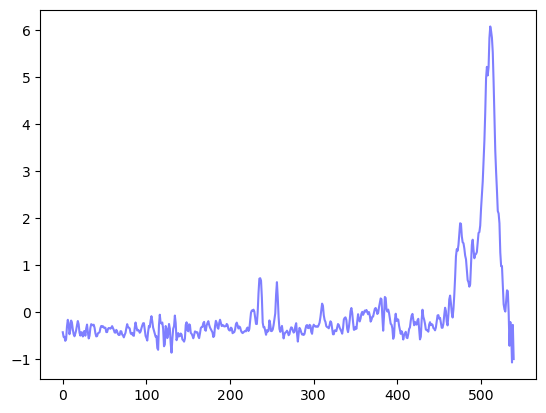

0.11490680638028138


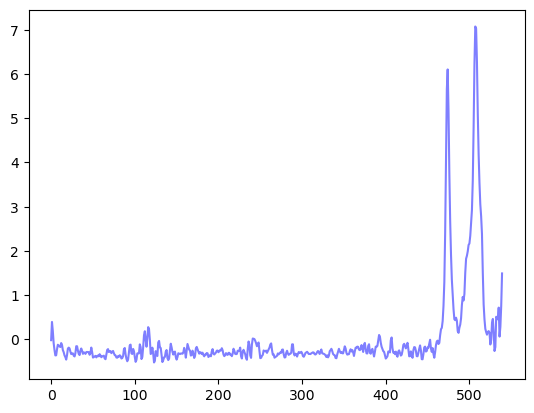

0.11626615225684903


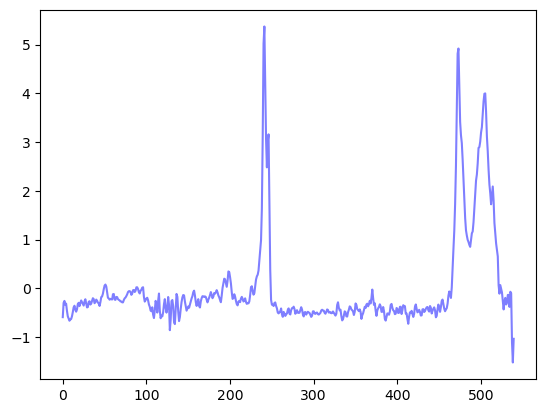

0.11775214582610835


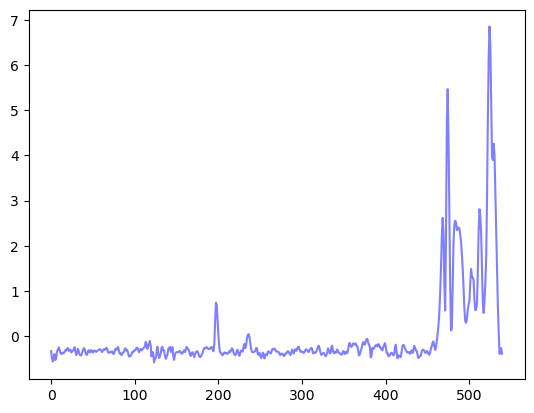

0.11789023296238439


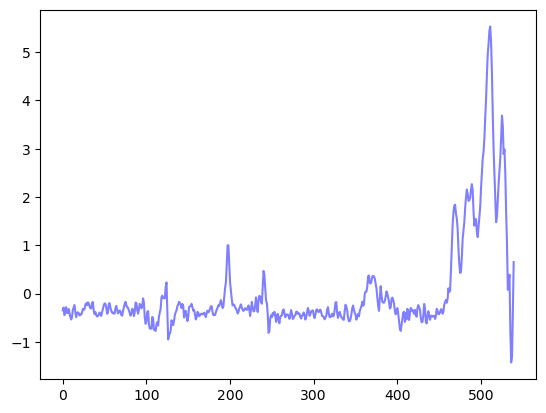

0.1187266324149621


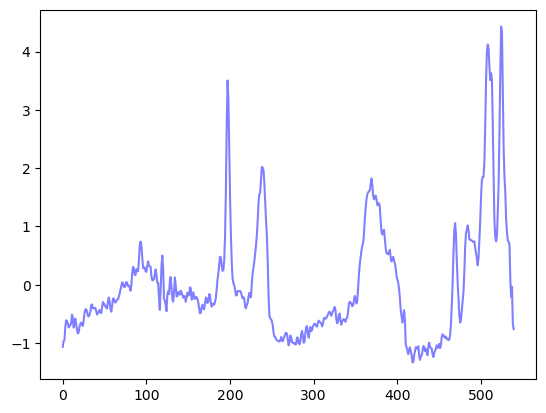

0.1201552519234637


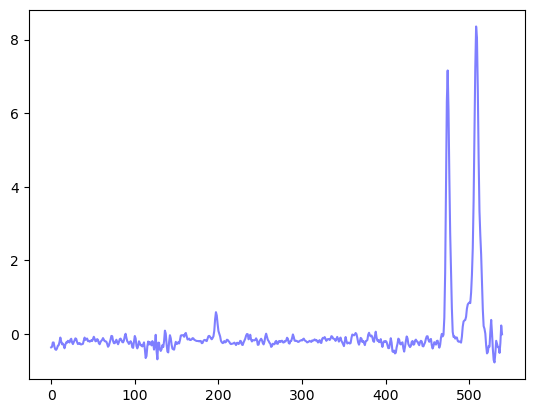

0.1220785329803653


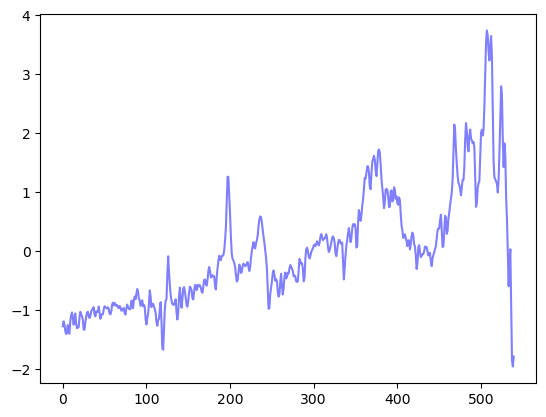

0.12557597437391865


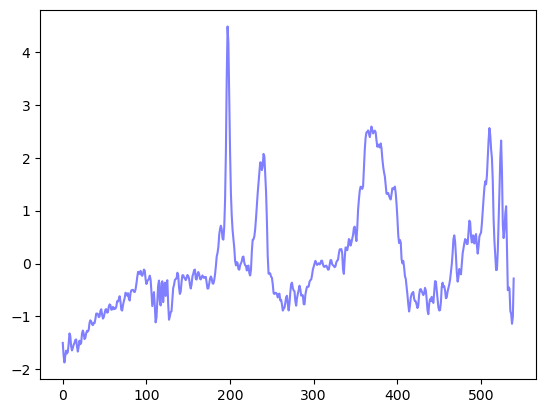

0.12620395483292973


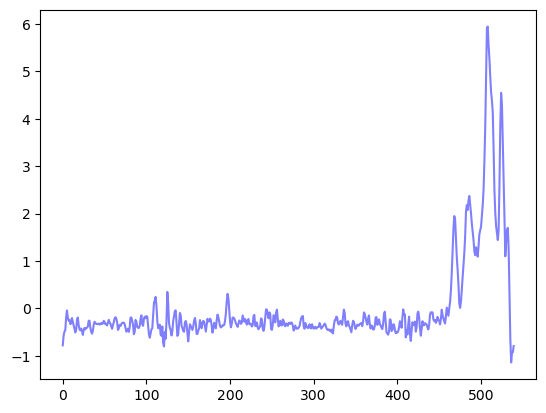

0.12731793322688334


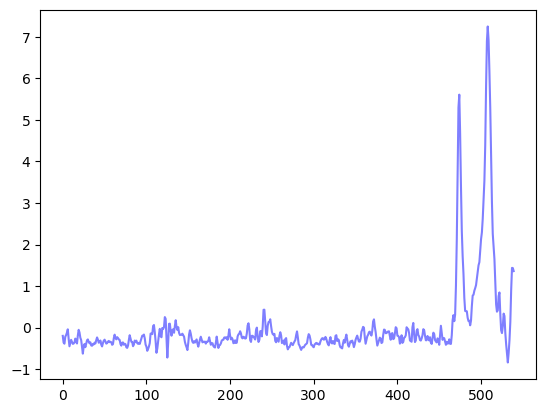

0.12783162865387904


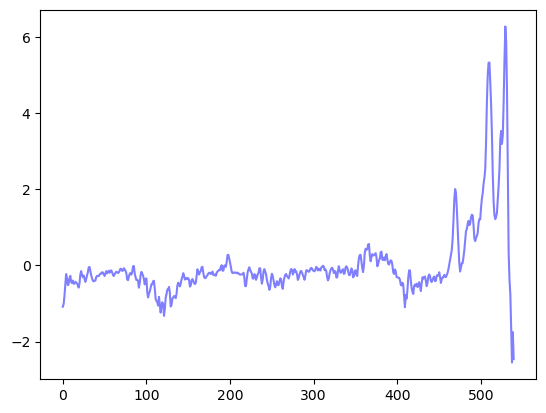

0.12818415326549776


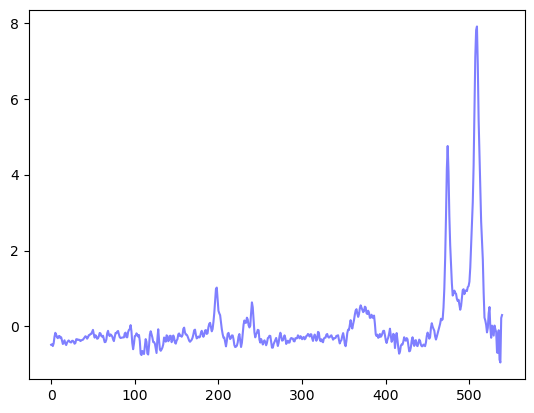

0.12829581300319148


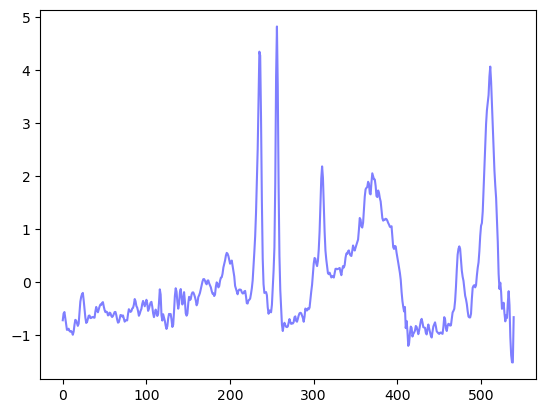

0.12851207718005592


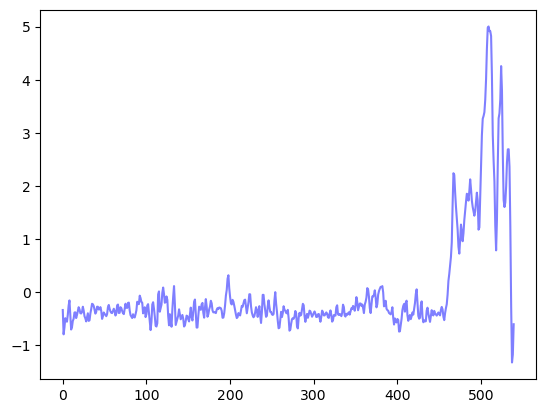

0.12869149786673928


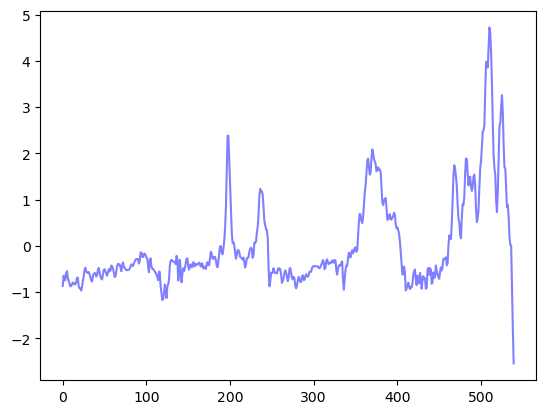

0.12870675279453417


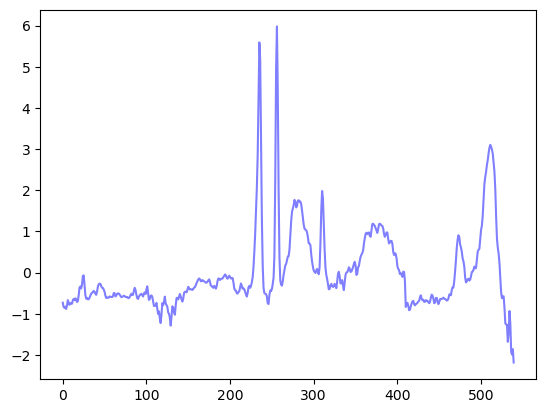

0.12922881242540354


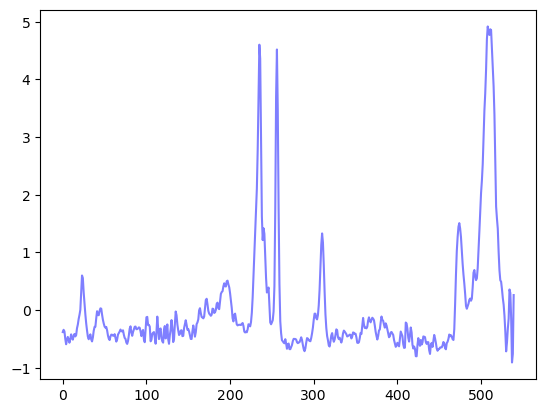

0.13027125783252852


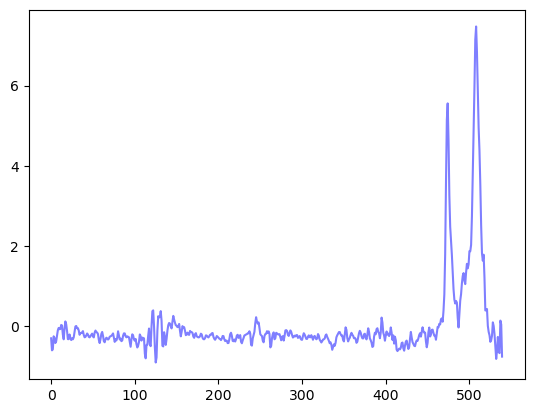

0.13147631139784627


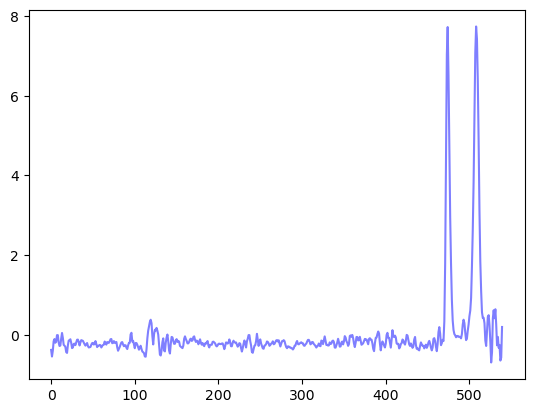

0.13242239961716323


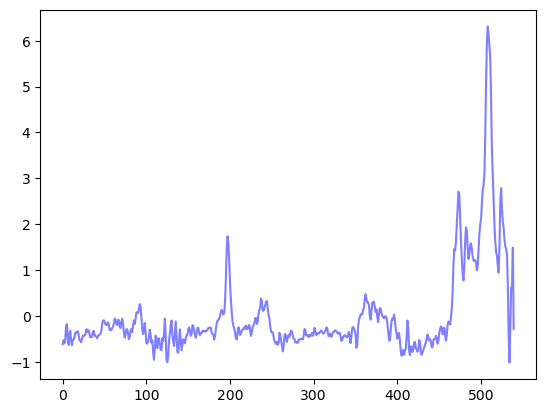

0.13441058192822214


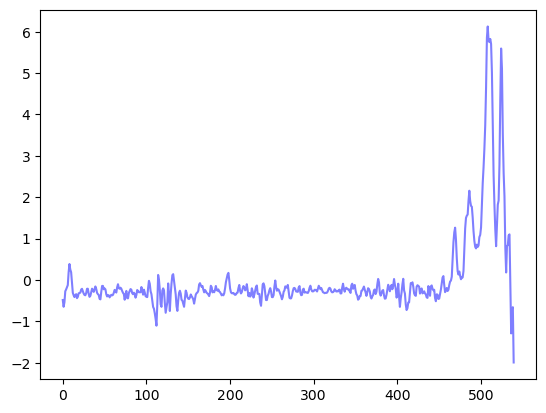

0.13541158579186313


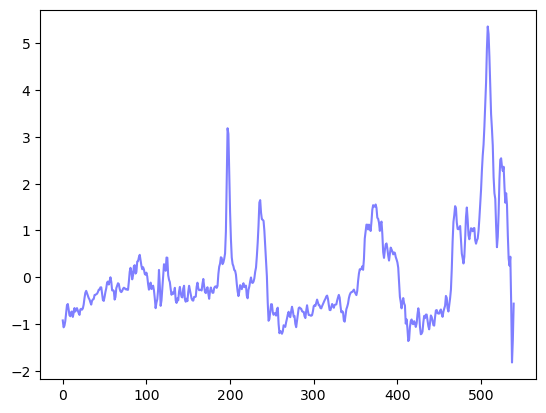

0.1379724542041647


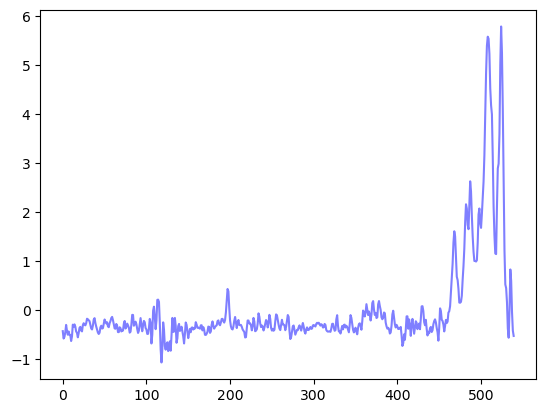

0.1388545710362323


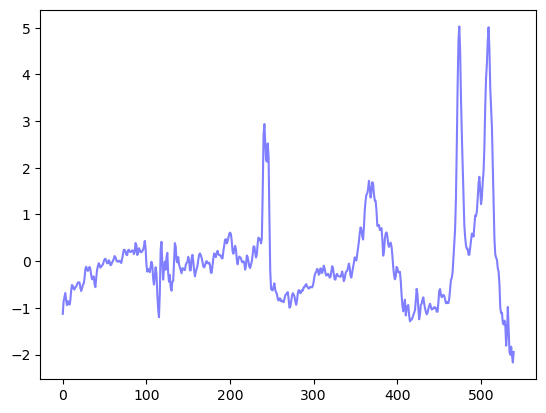

0.13974151639442195


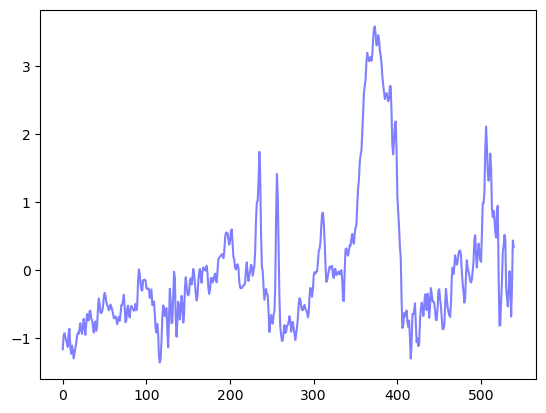

0.14077654945139204


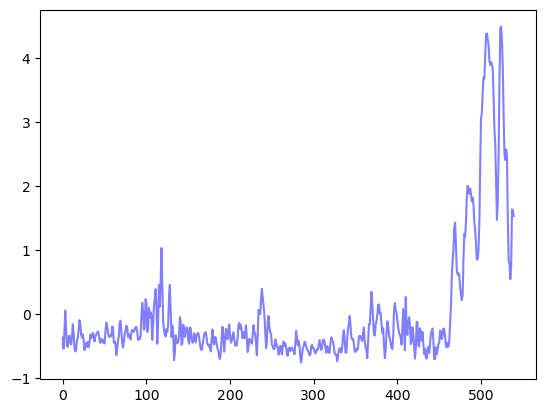

0.1409771658790109


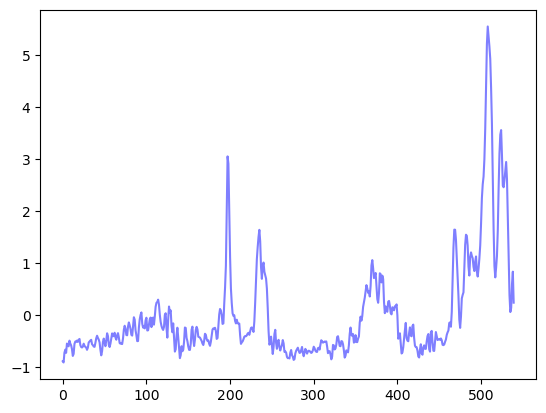

0.14130650165468792


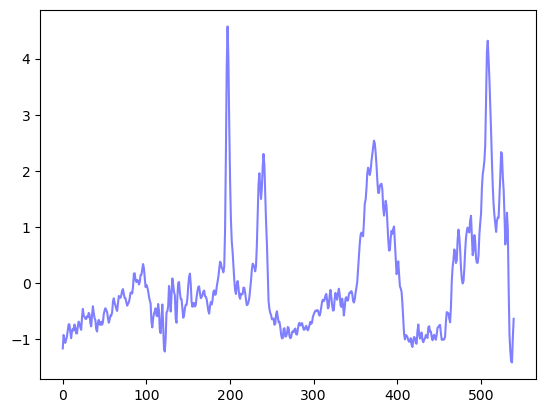

0.14847569890936527


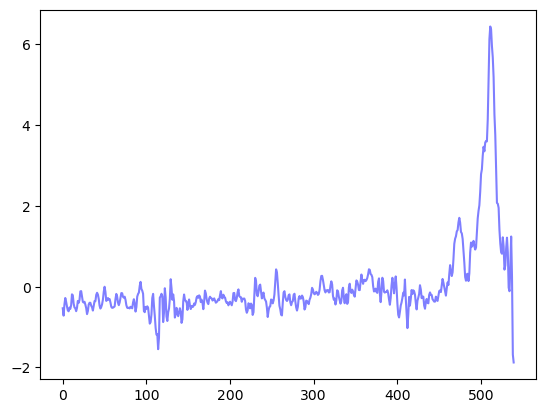

0.14938896395836446


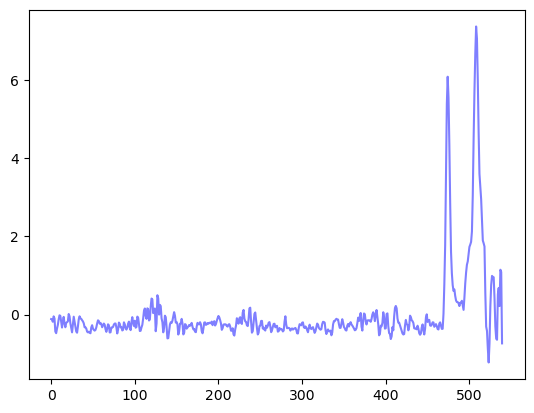

0.1516365315985508


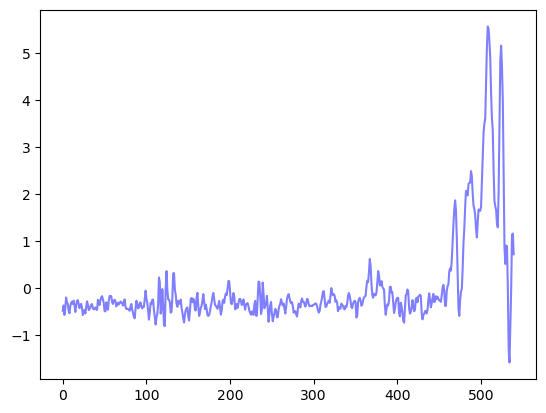

0.154645048045409


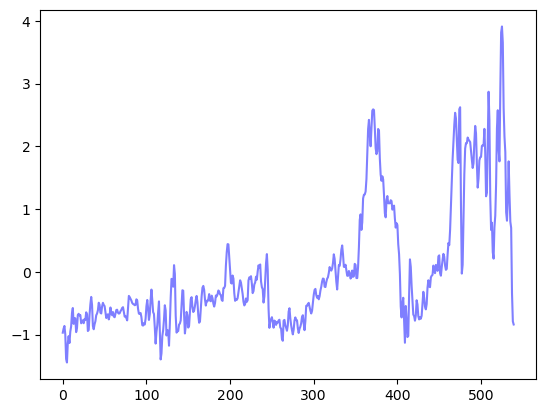

0.1557416196367551


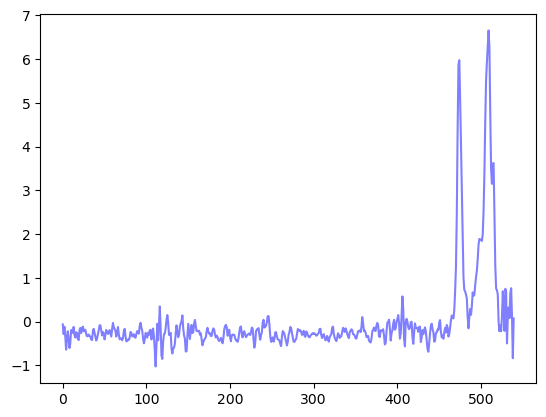

0.15787297130357877


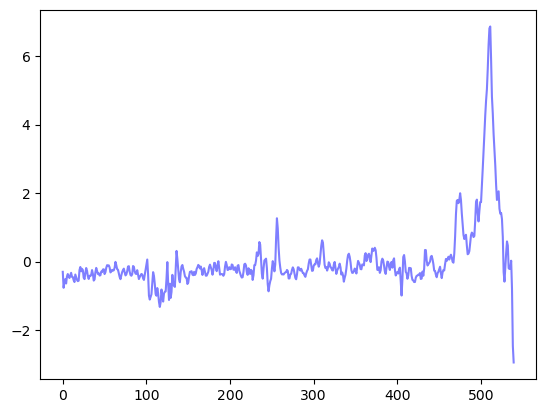

0.16020813959575625


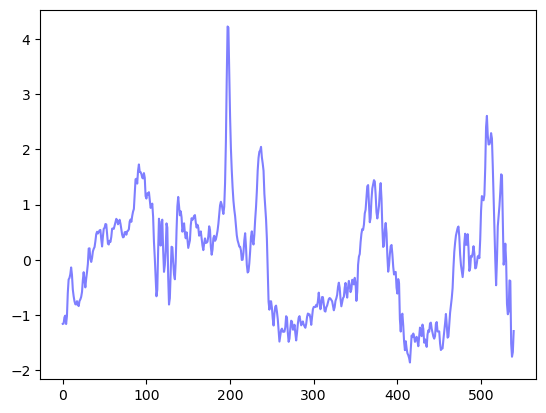

0.16351769943714753


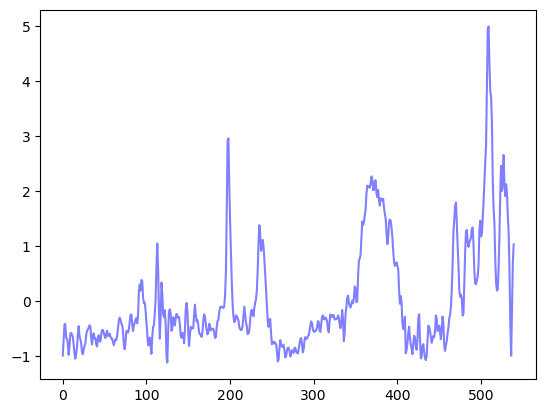

0.16546329560759457


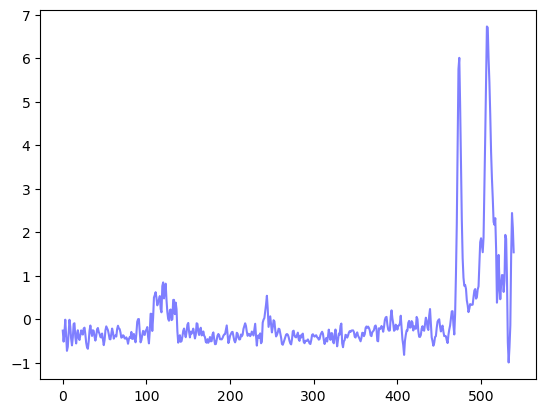

0.17024784289707717


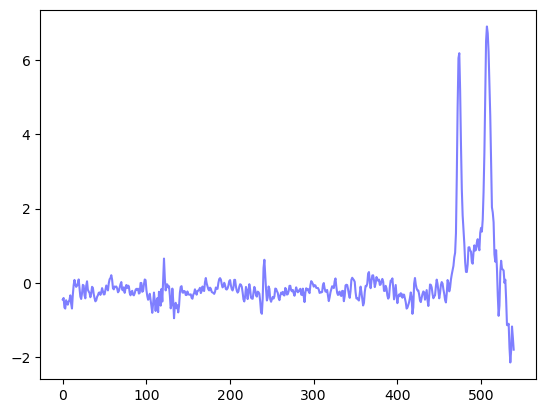

0.1704067524388204


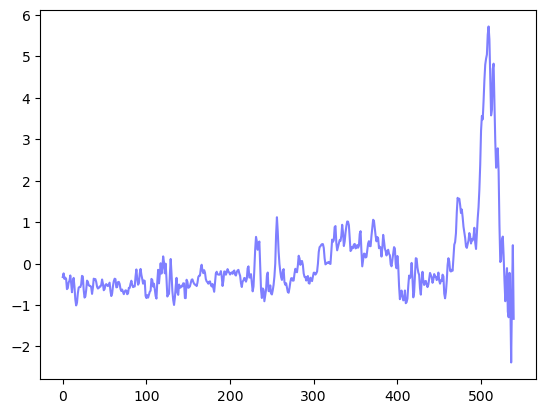

0.17183628690136388


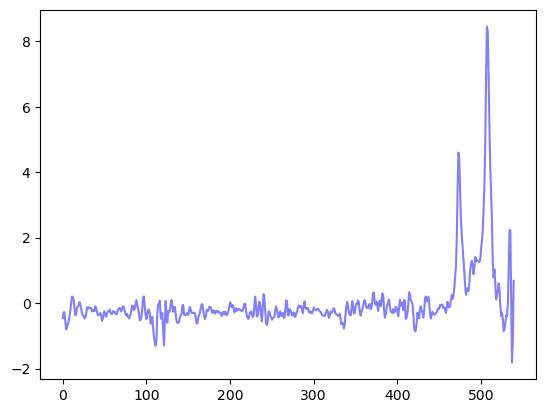

0.17276628470942781


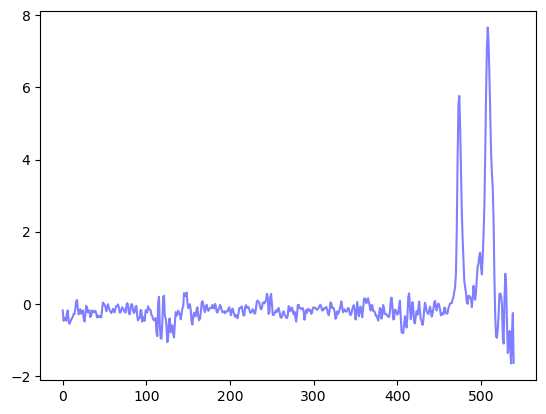

0.17485094880575097


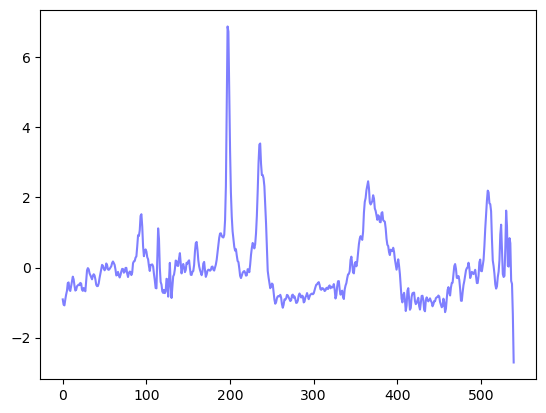

0.17567769769117528


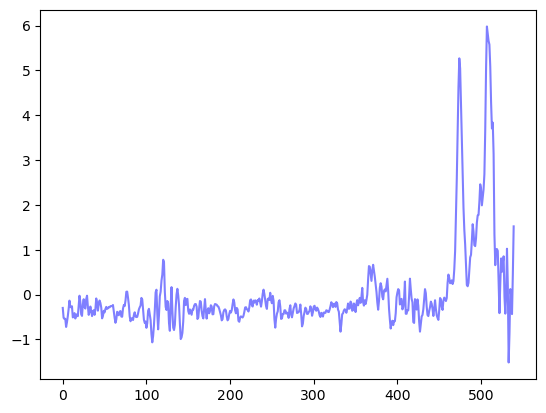

0.1772433891882604


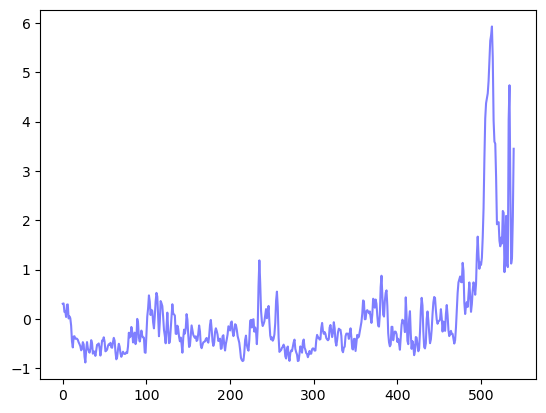

0.1777424173417141


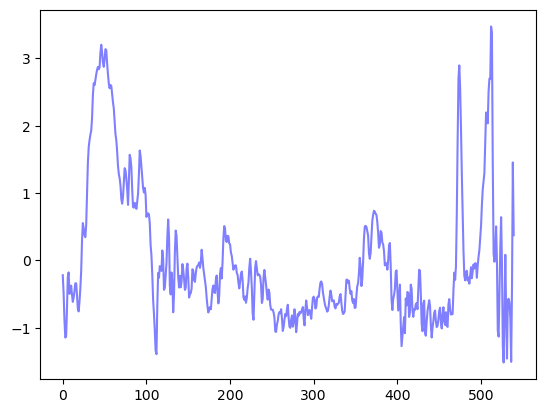

0.18826349142933424


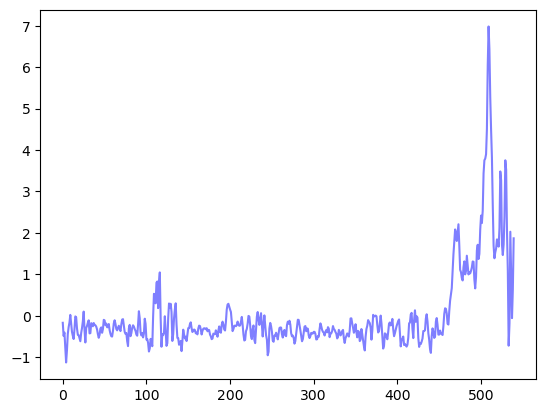

0.18841697546694824


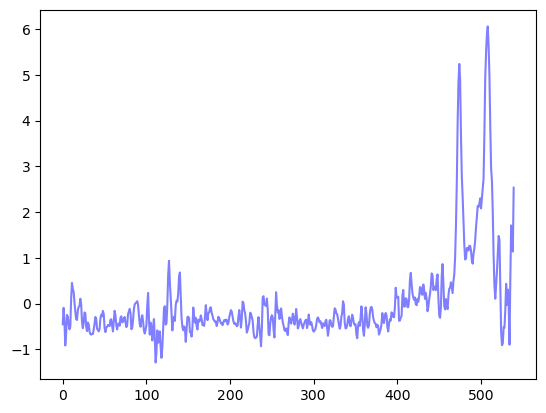

0.19363318966818951


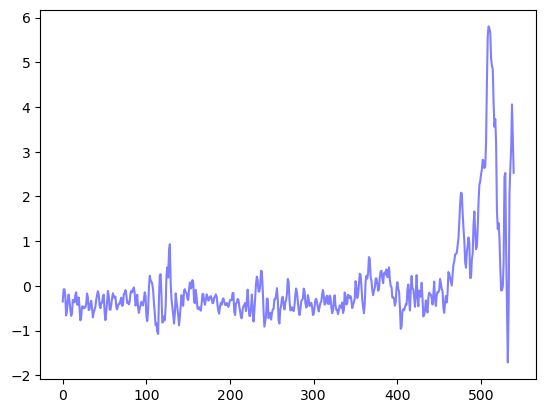

0.19425384168943488


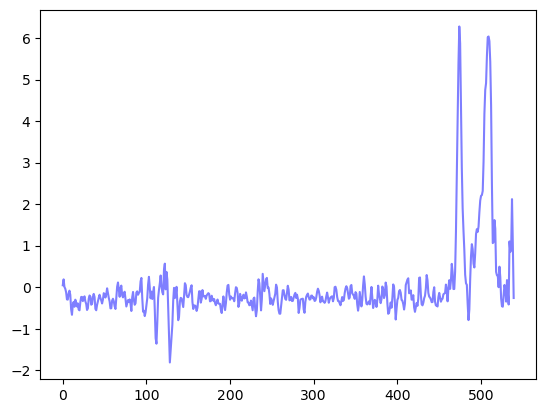

0.19530412228483615


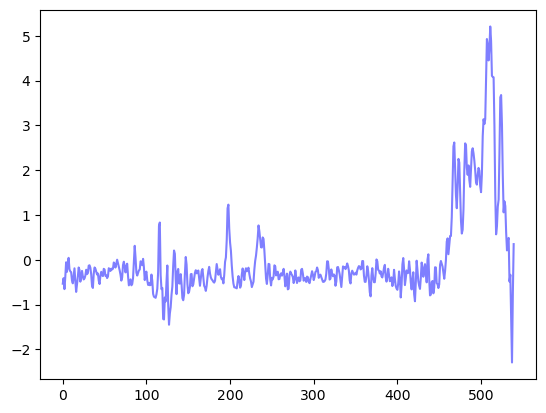

0.20297270395961314


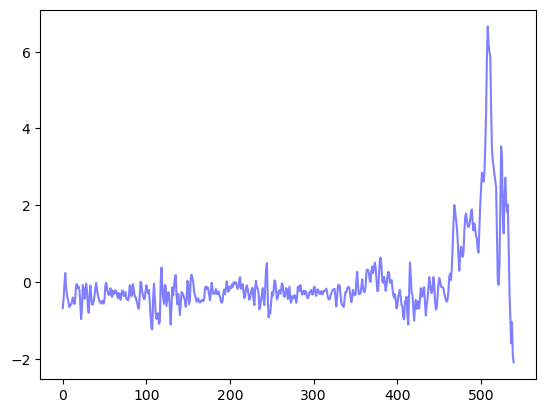

0.20570886056547383


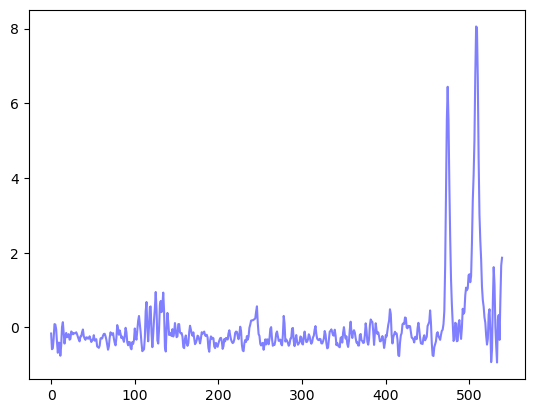

0.20619533400252749


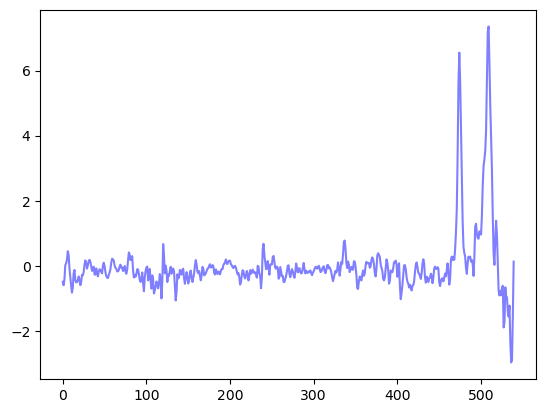

0.20802777254640814


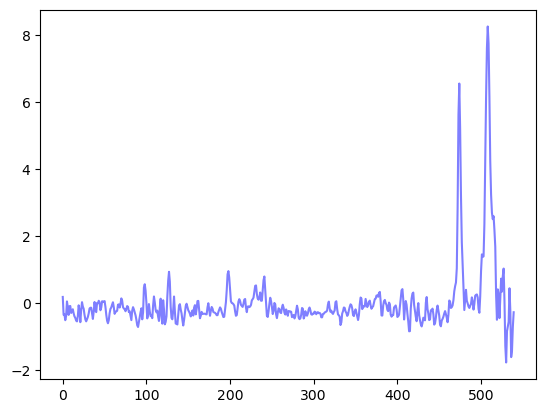

0.21374801937600907


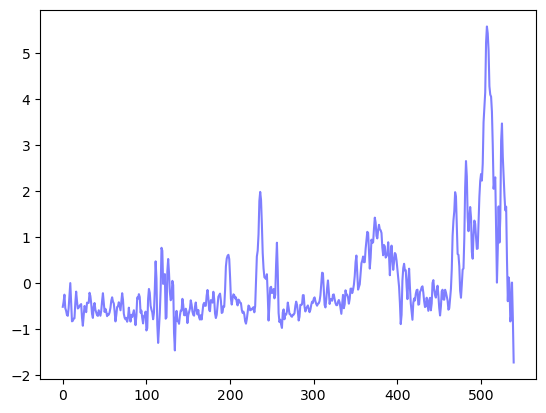

0.21773879800841997


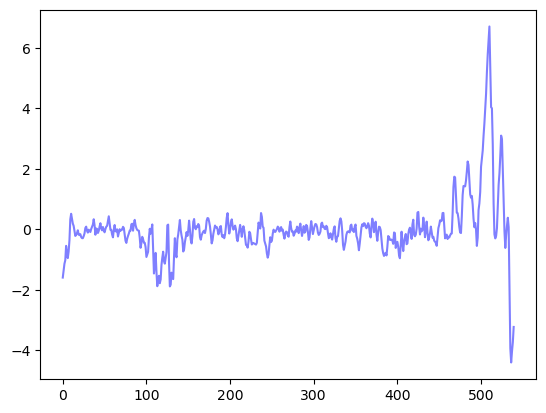

0.21820733927147096


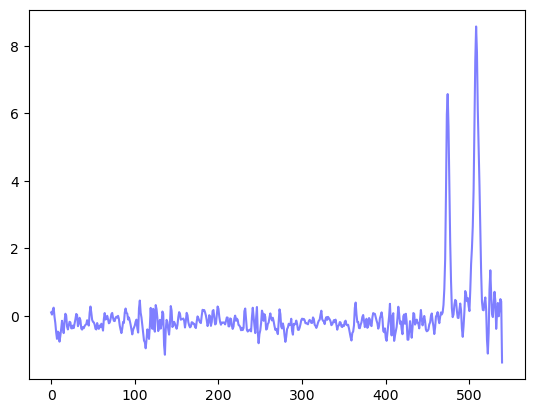

0.22034688760329474


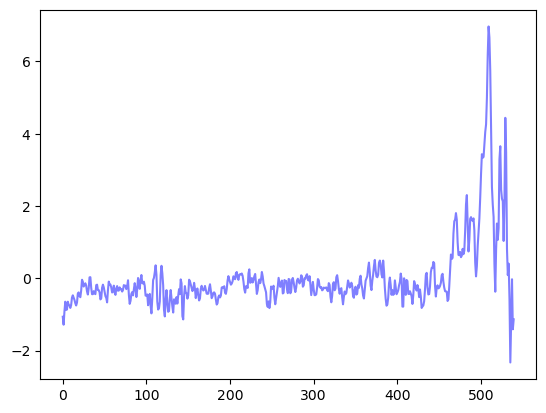

0.22138850319824524


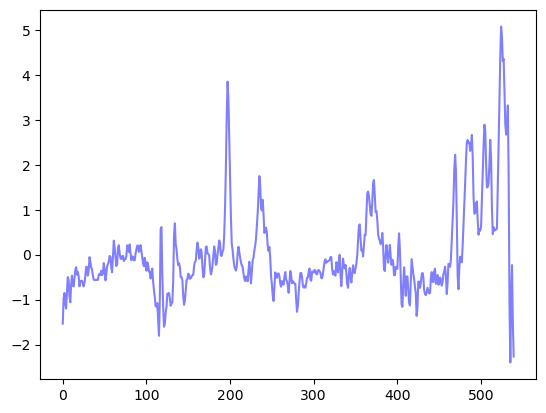

0.22148828706803908


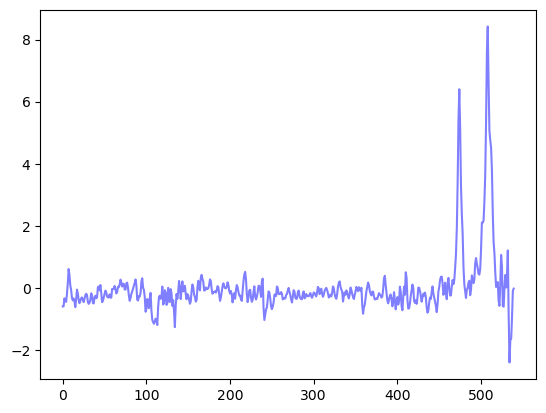

0.2229657654475002


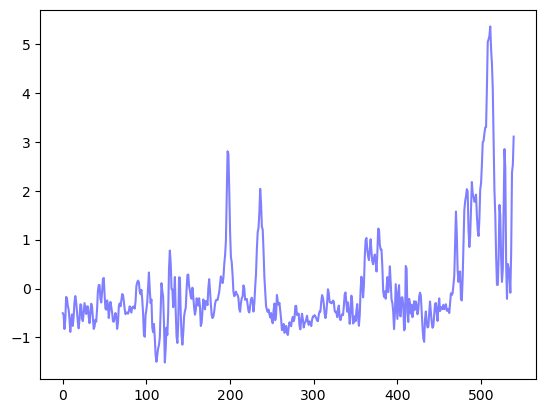

0.22511854885177443


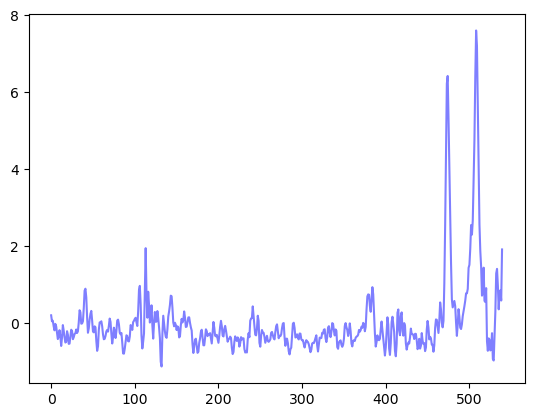

0.22728481361538078


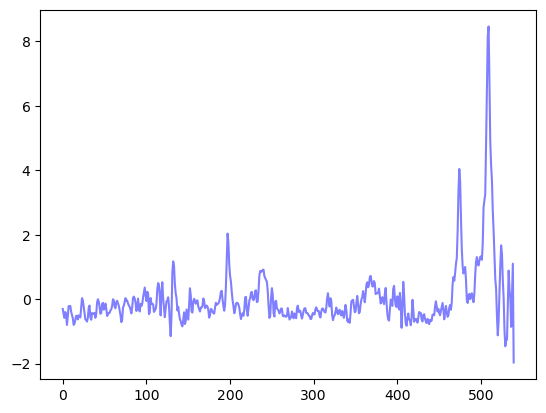

0.23505040913097122


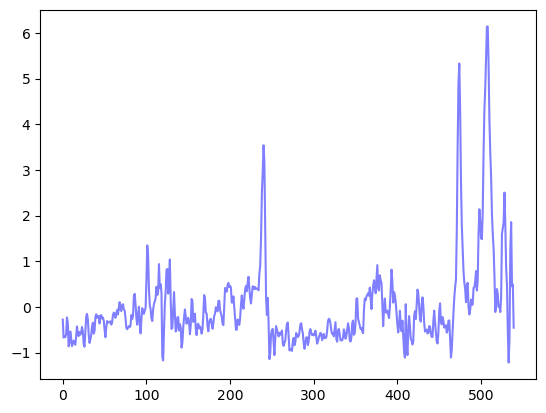

0.23628963574607942


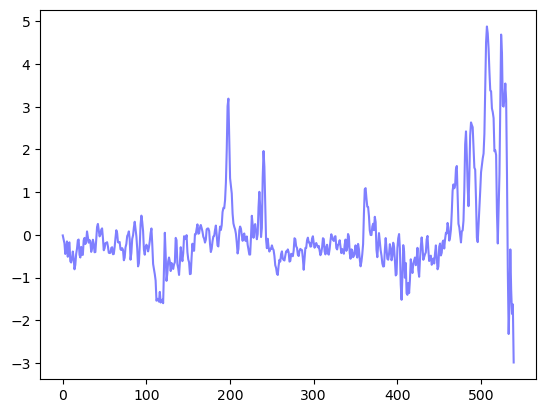

0.2379362334042532


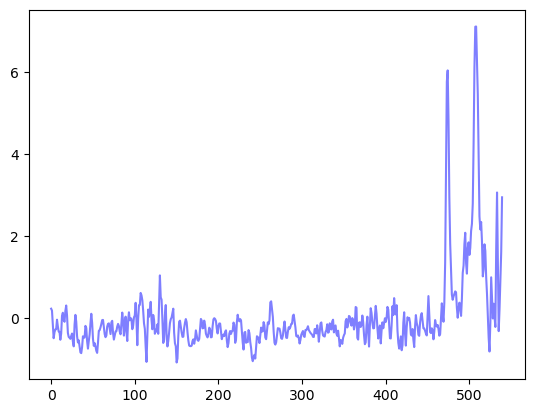

0.2390396354128386


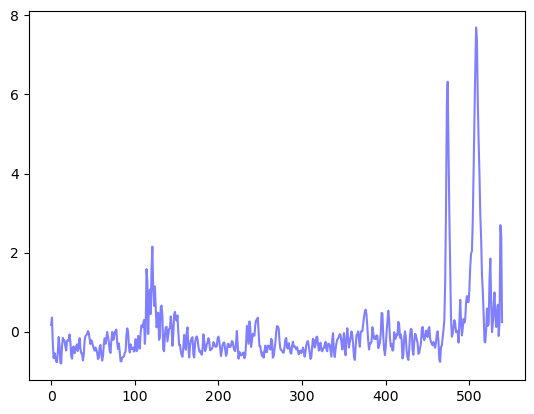

0.24298318763128732


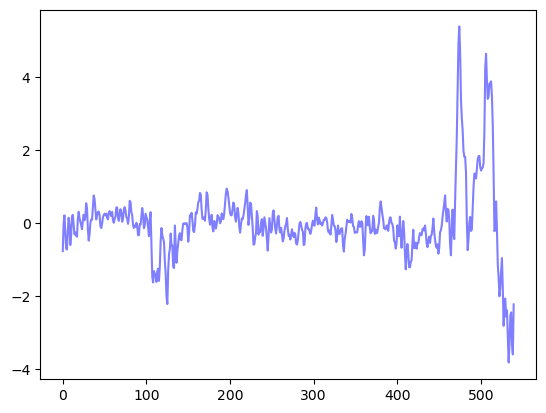

0.24603620757020545


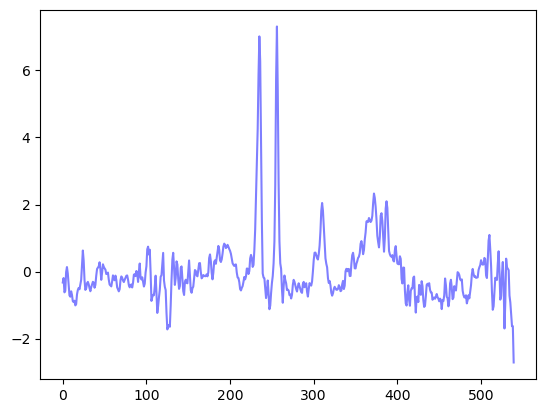

0.24795656121824625


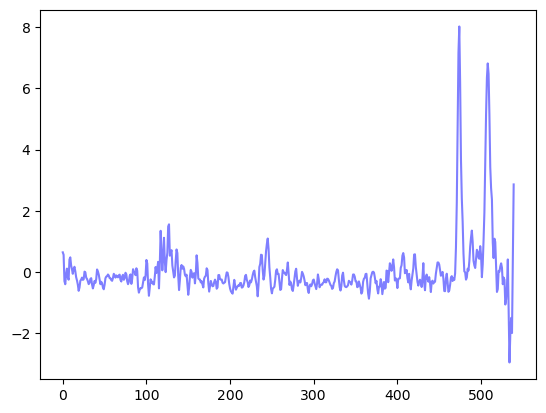

0.2745967390572814


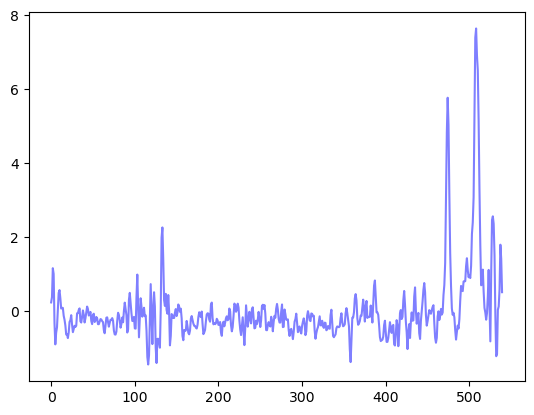

0.27850879290644837


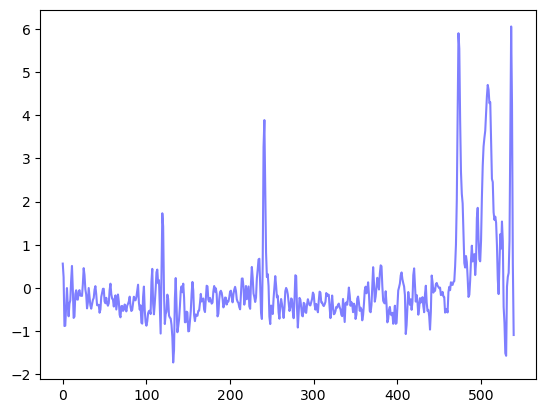

0.28766494658361197


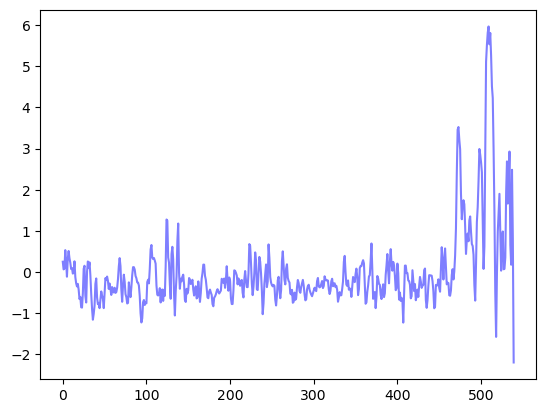

0.2889487282269786


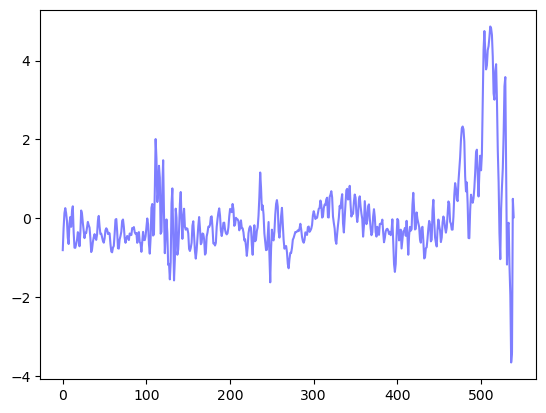

0.29073294332333355


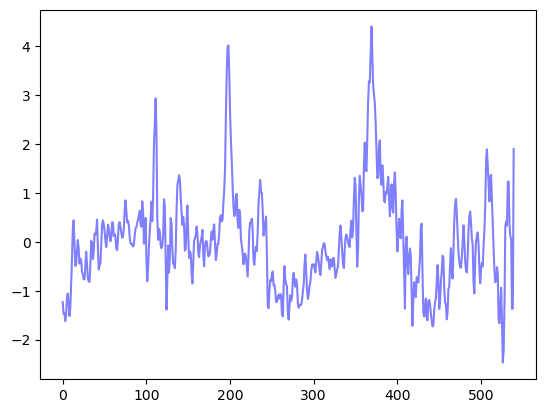

0.2961705683757572


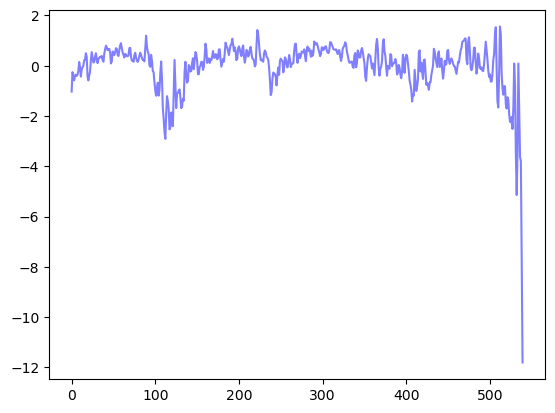

0.2983125367752696


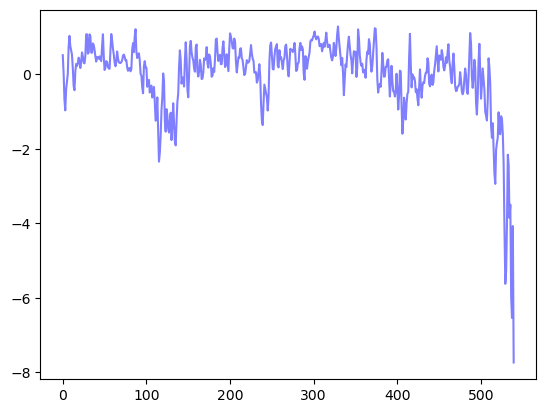

0.3030924678592442


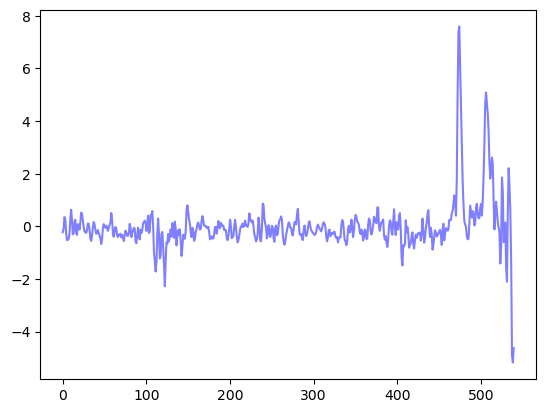

0.30469508910205745


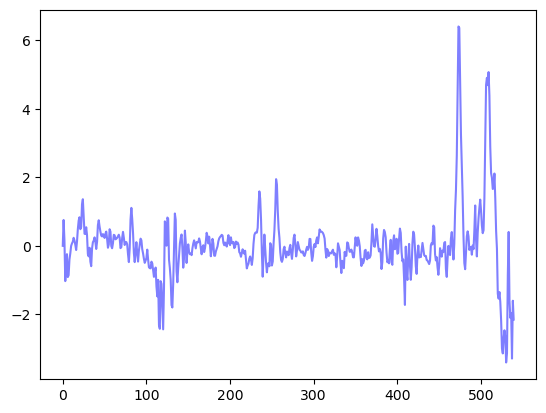

0.30586775421288864


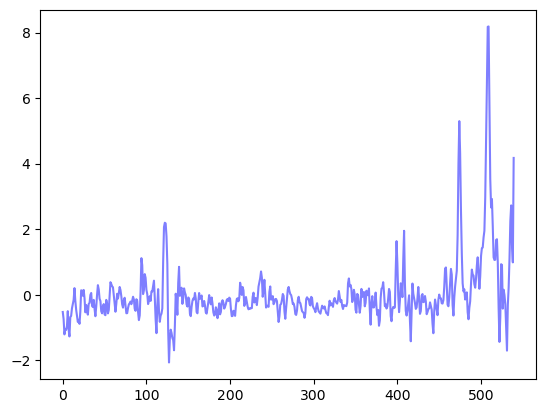

0.31073778075136355


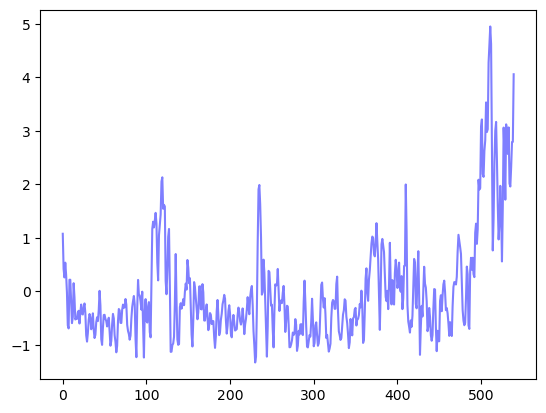

0.31445584436502566


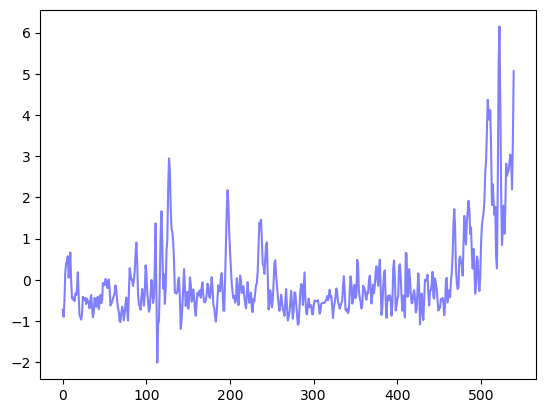

0.32245320724523635


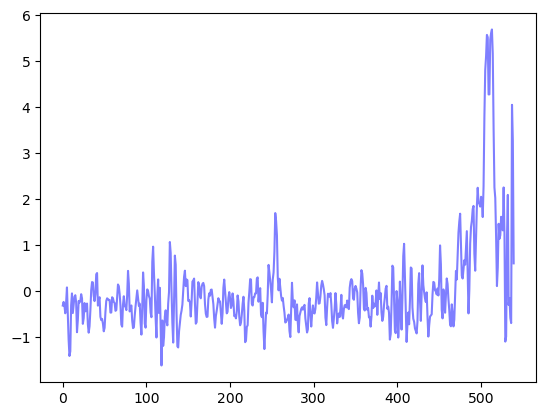

0.32440037984278497


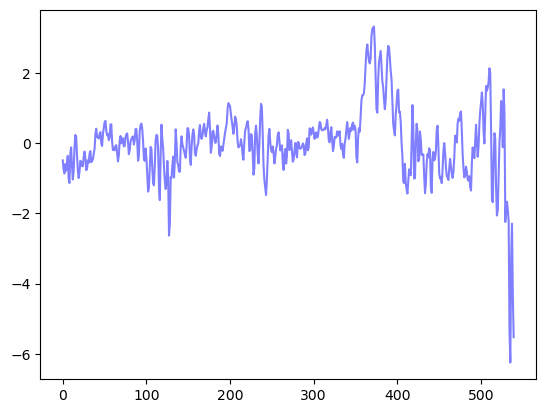

0.325578534360201


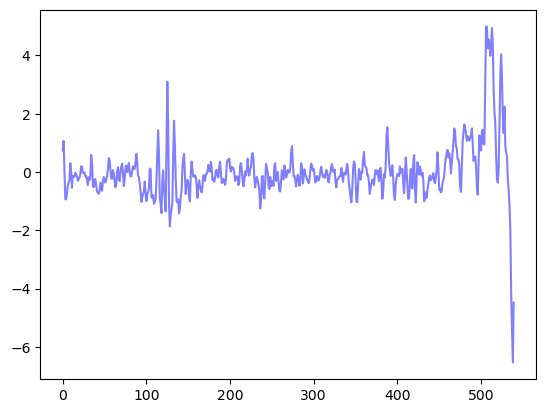

0.32644985689872663


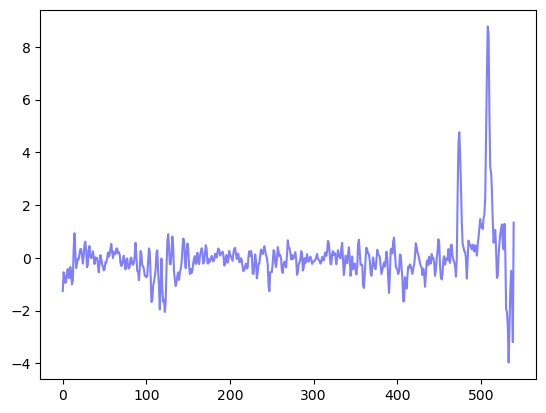

0.33105570592088235


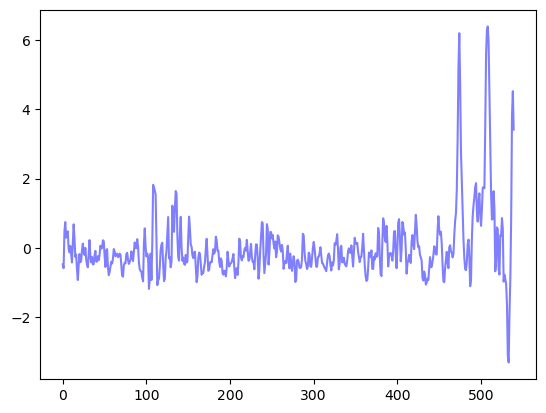

0.3315673898050686


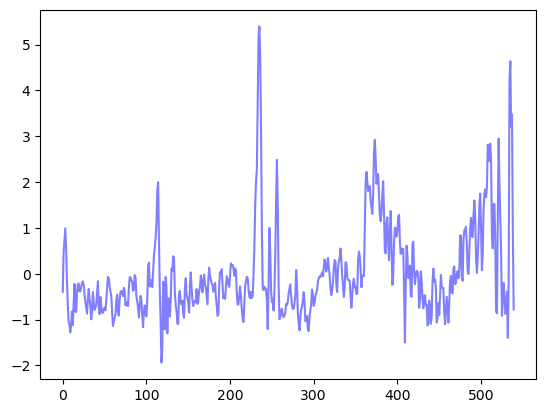

0.33549868264584093


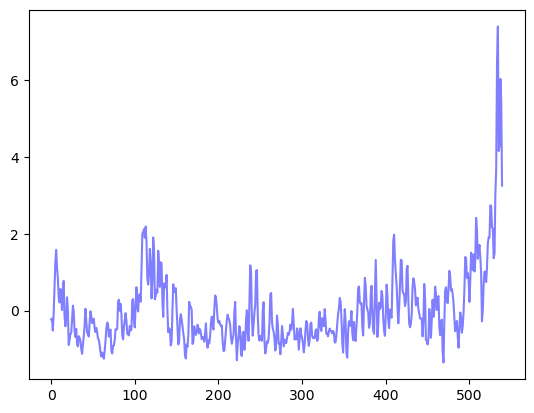

0.33990346254970133


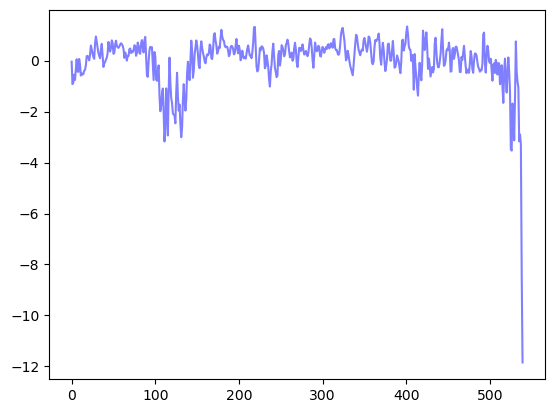

0.3435122383150385


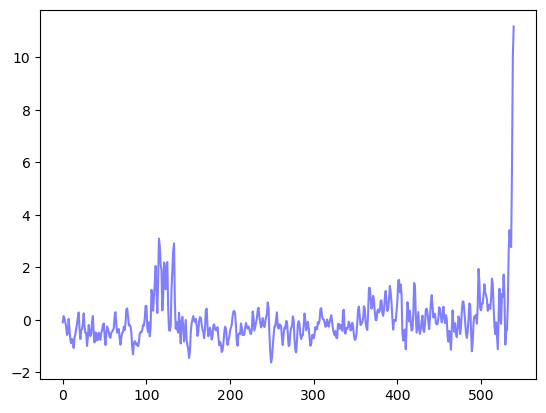

0.3443104905789733


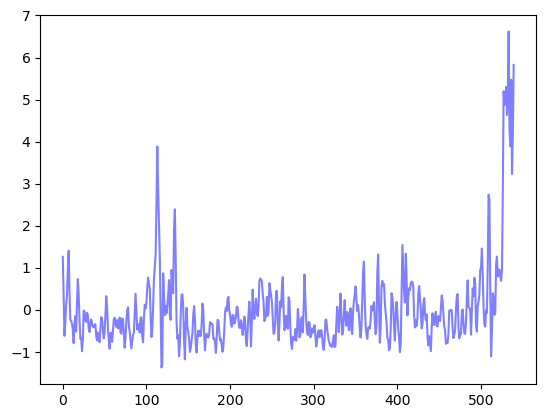

0.34606926227054025


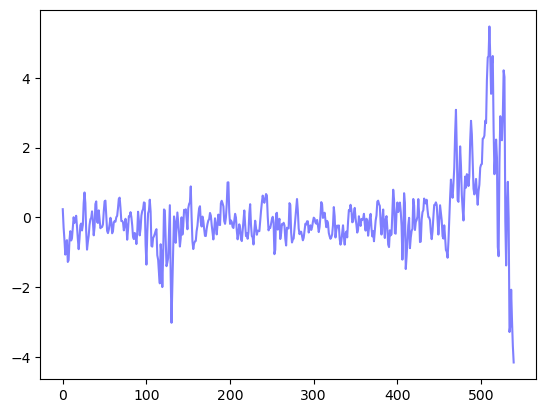

0.34646728968655915


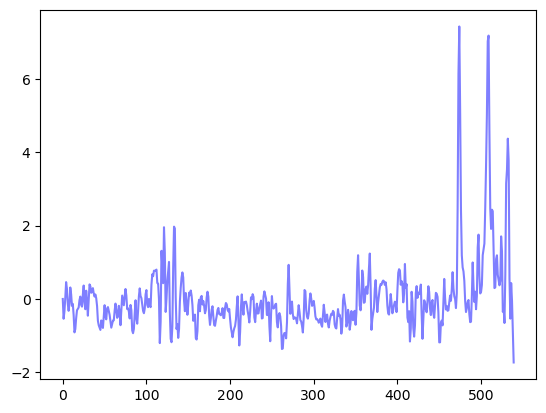

0.3520829168964279


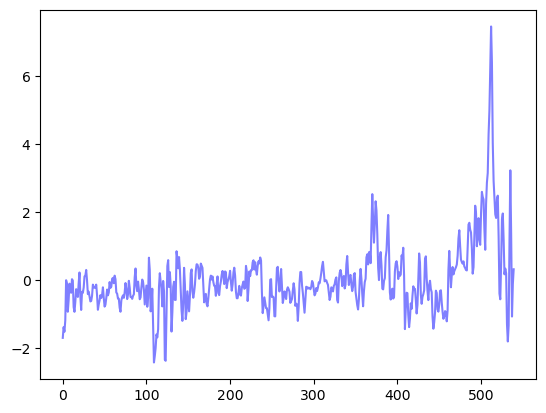

0.35479081810722185


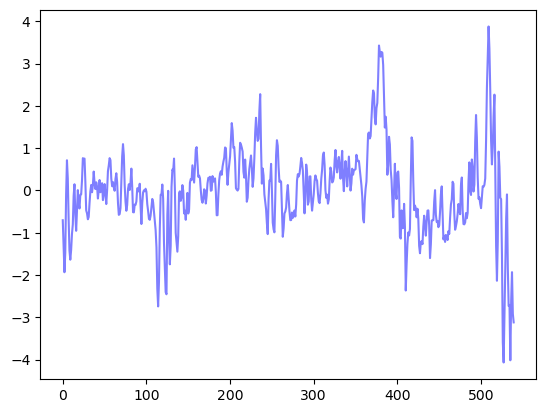

0.3613229725742366


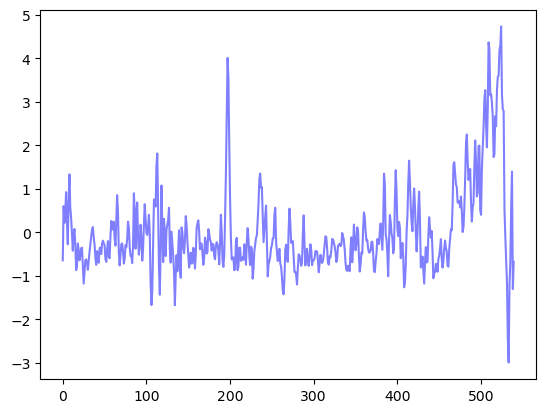

0.36202878467739746


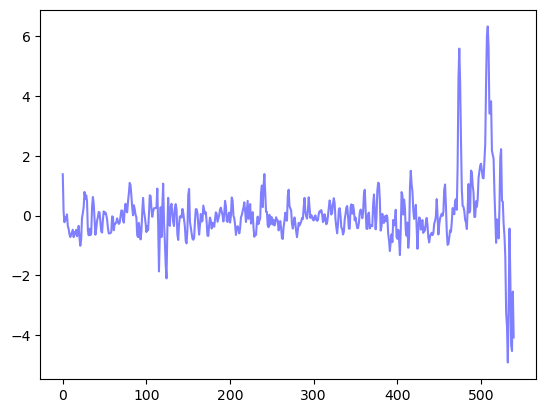

0.36387182682073493


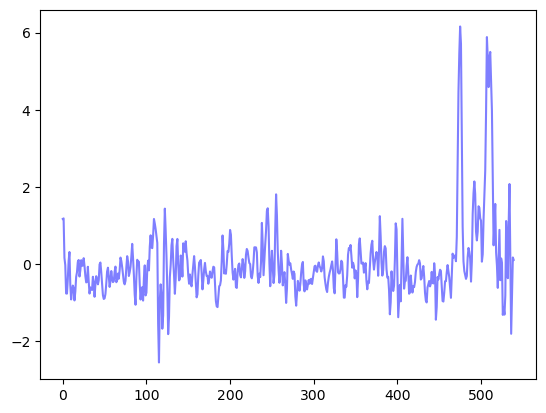

0.36635155005761605


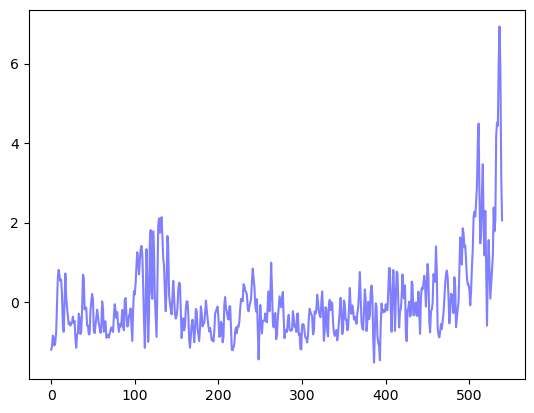

0.3706263313175866


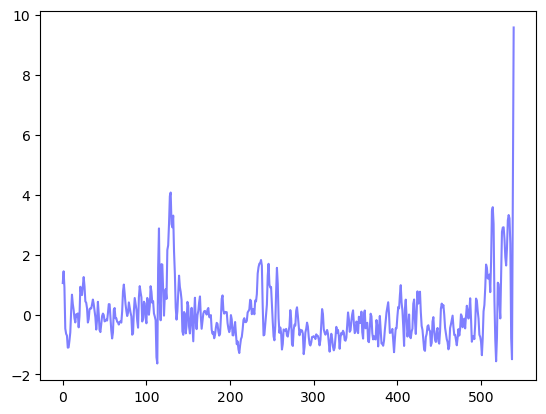

0.3730568300053835


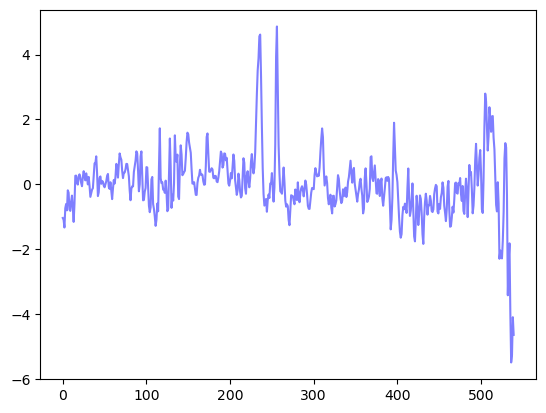

0.375127175499478


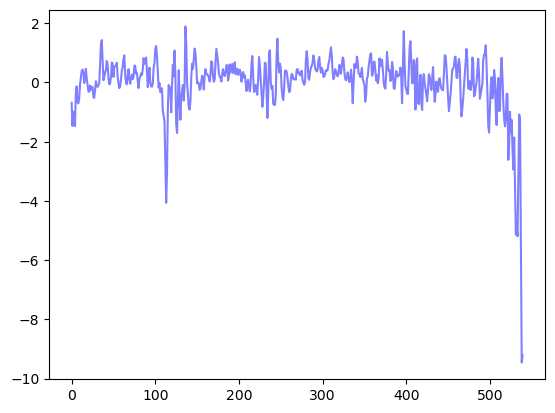

0.3770896057120863


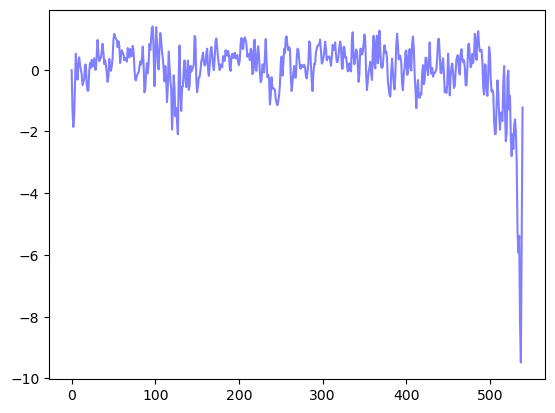

0.3778904267969168


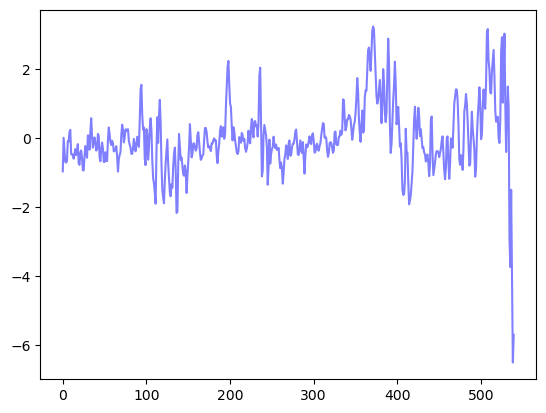

0.37941957605090987


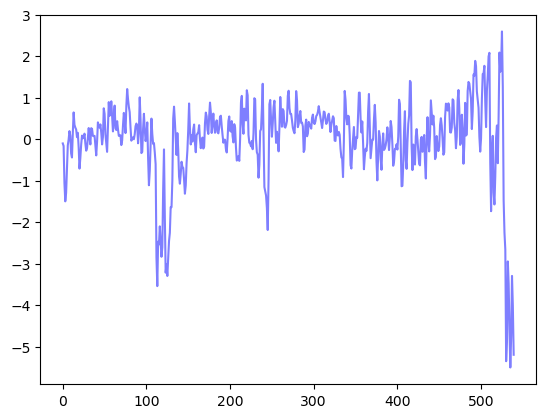

0.3845243886190495


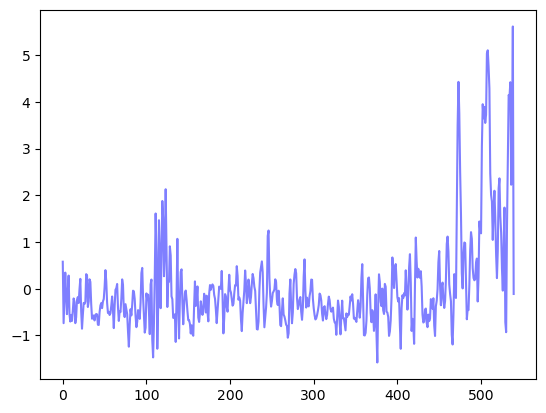

0.39126646235621615


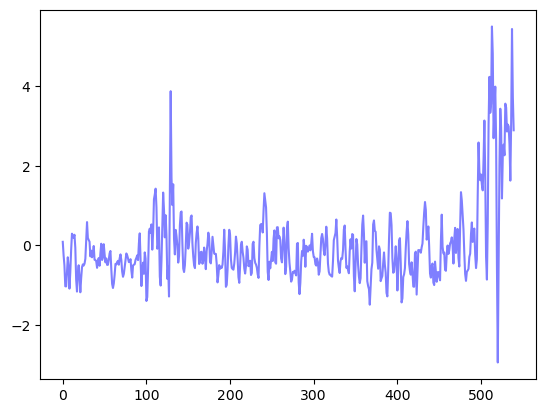

0.3954544110234778


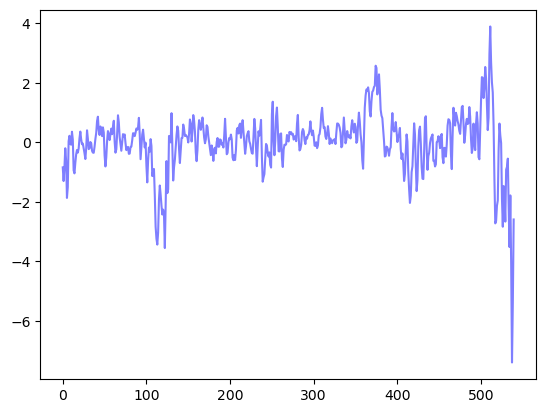

0.3996880494229013


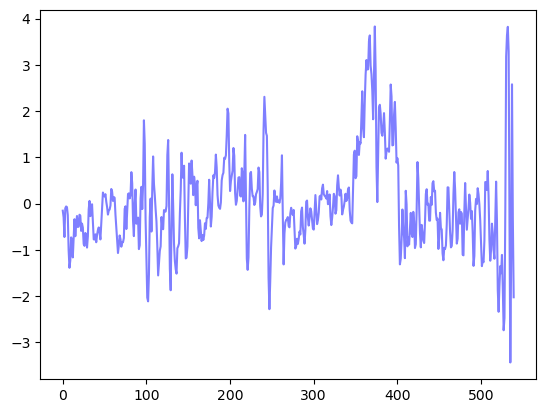

0.39990738720514857


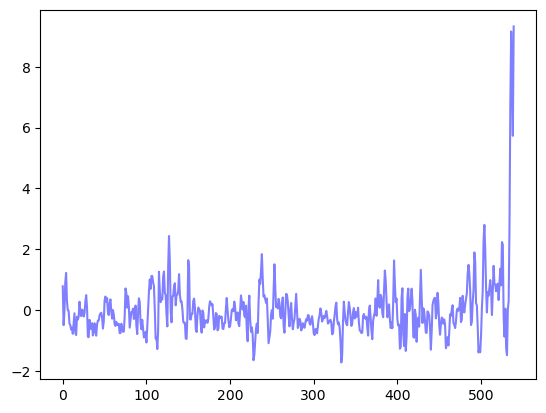

0.40140785589646744


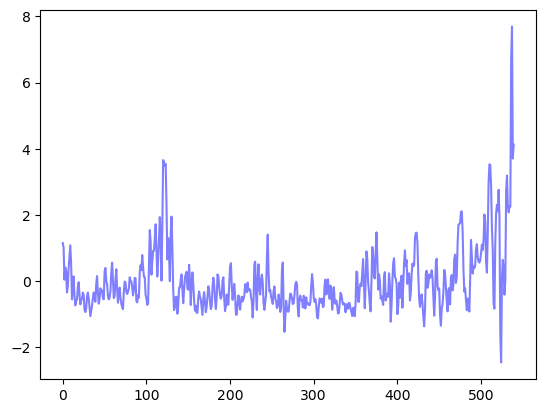

0.40195001739692465


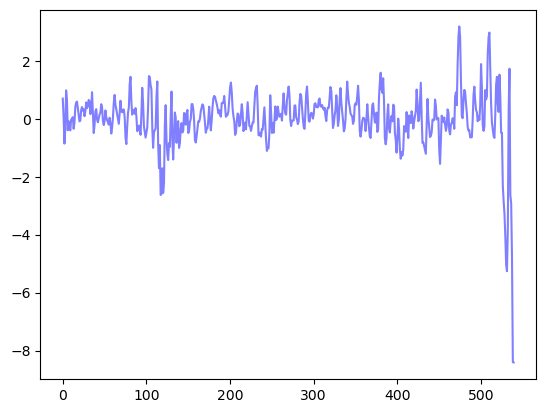

0.4091081849119385


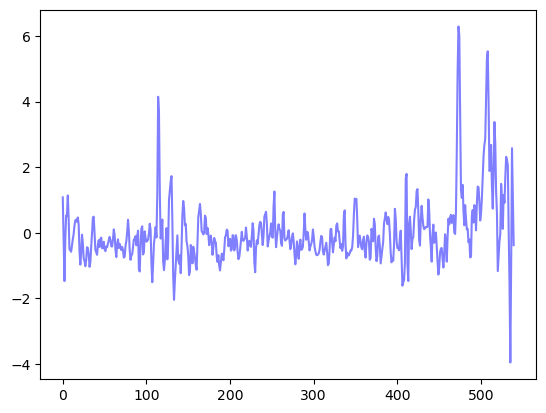

0.4095260373426492


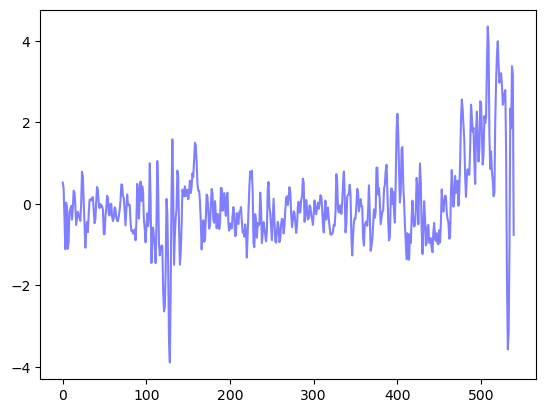

0.41344850764733754


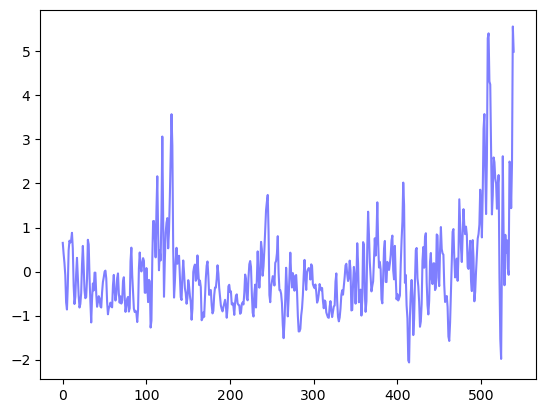

0.41558014241084457


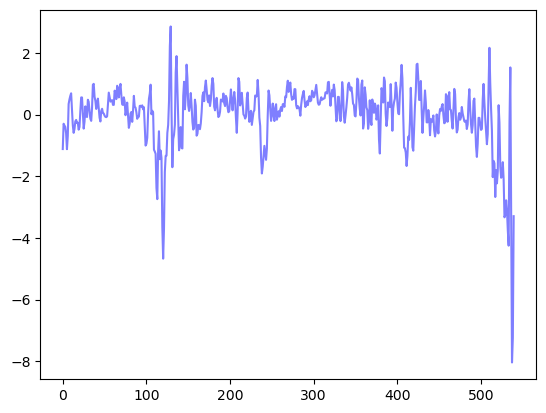

0.4170881268370671


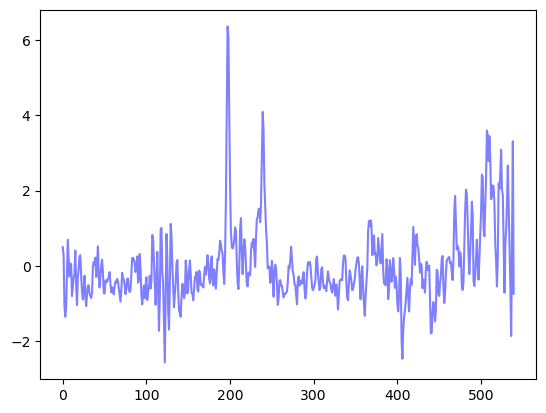

0.4180164528517482


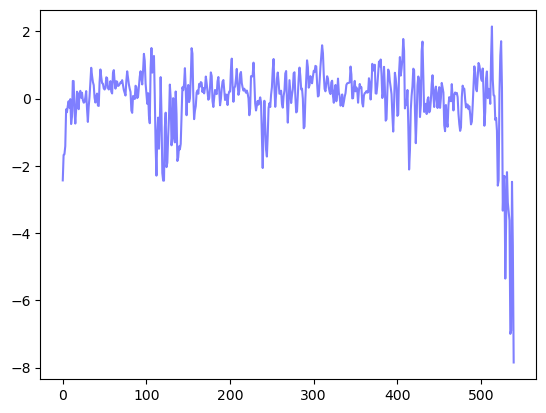

0.4207221212773375


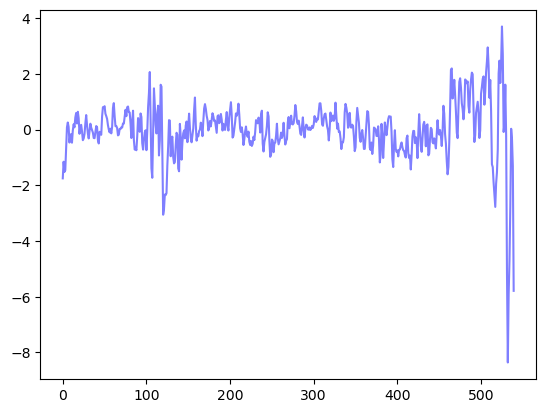

0.42125318160615405


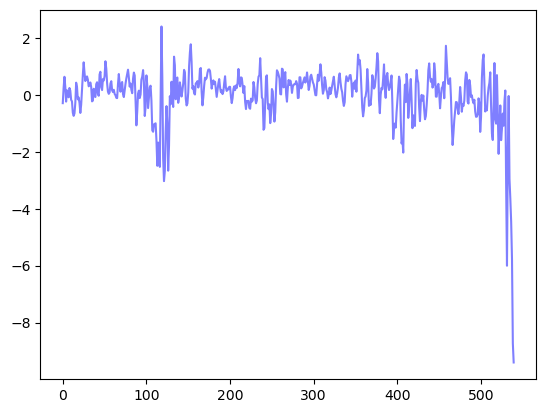

0.42731611732155367


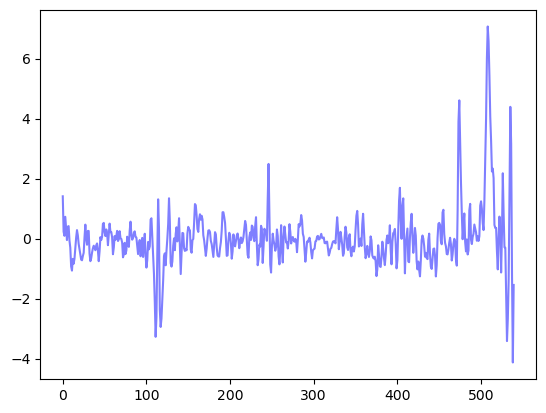

0.4306211091255154


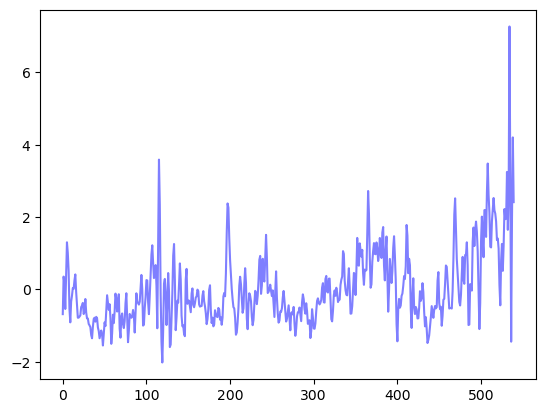

0.4338775841796885


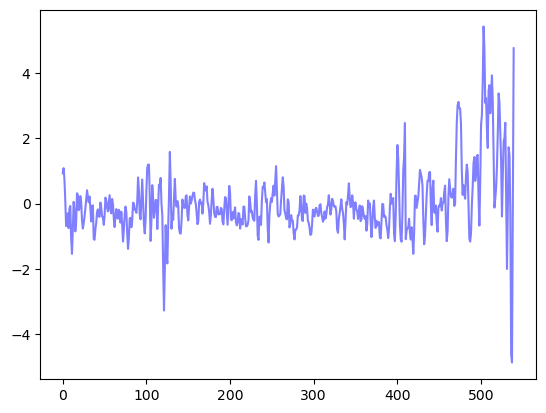

0.44147911572247867


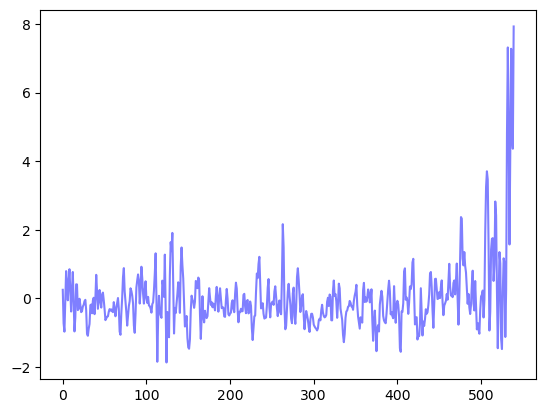

0.44388937510072873


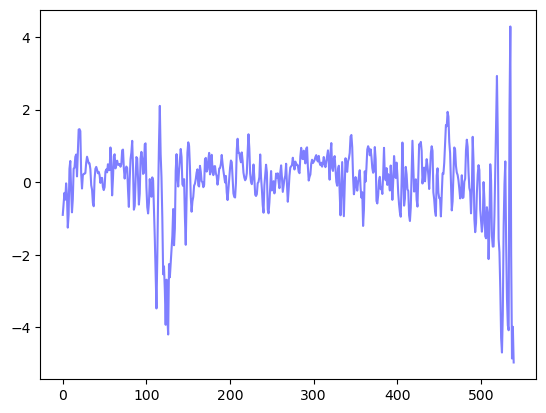

0.4510205398920841


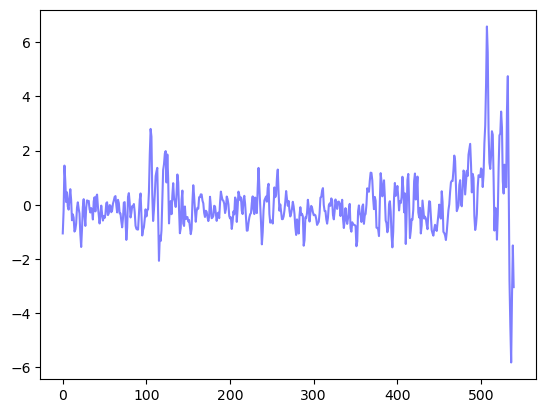

0.4533639992284593


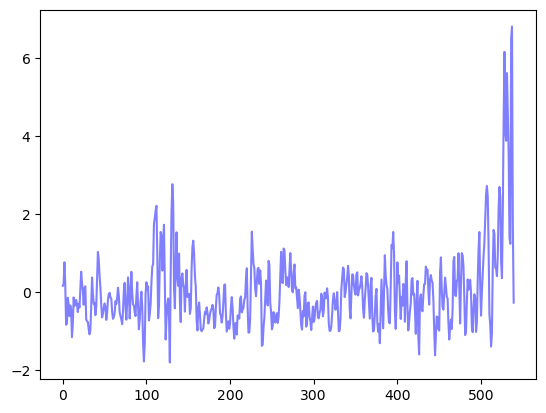

0.4615247980627892


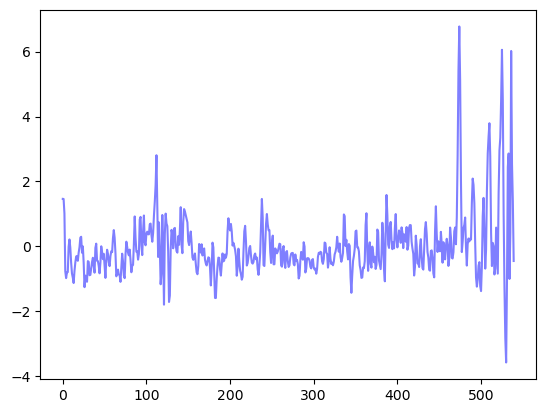

0.4631403554824183


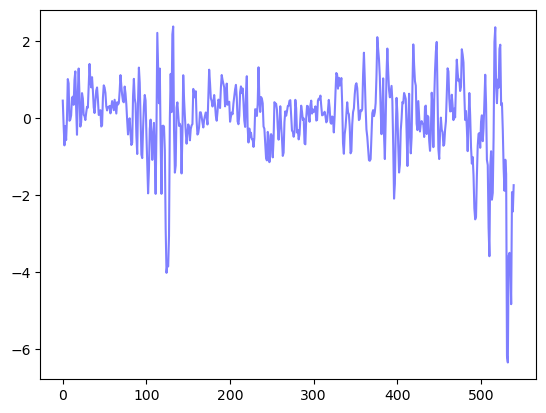

0.46772466905119


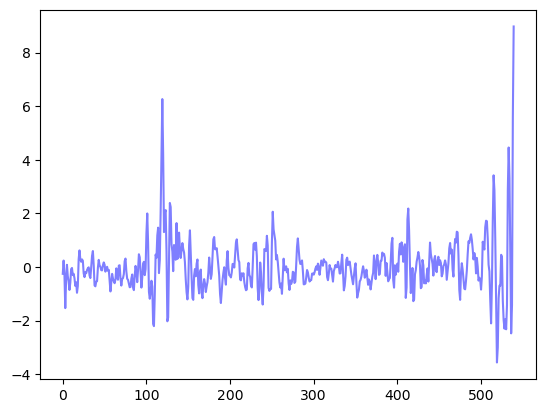

0.4701655376327158


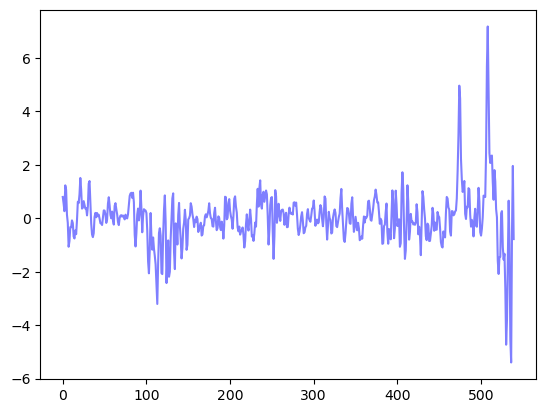

0.4711634443576509


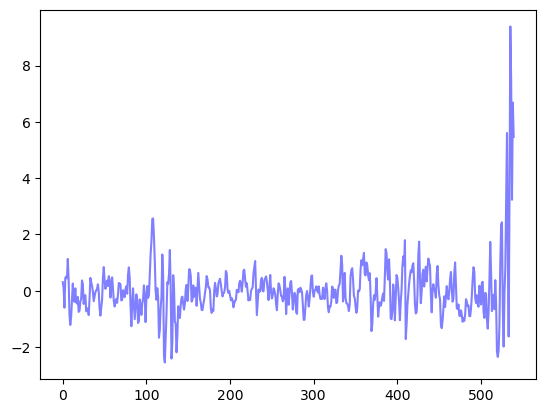

0.4721025471161422


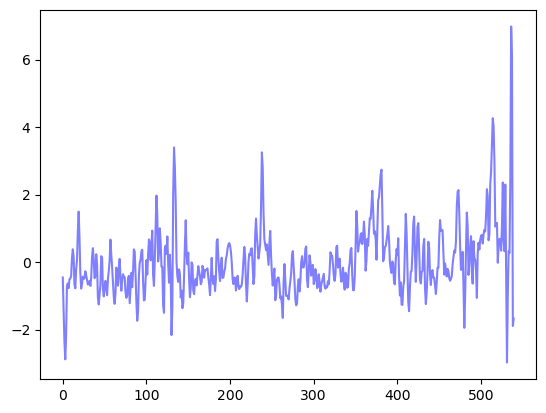

0.4724247101395481


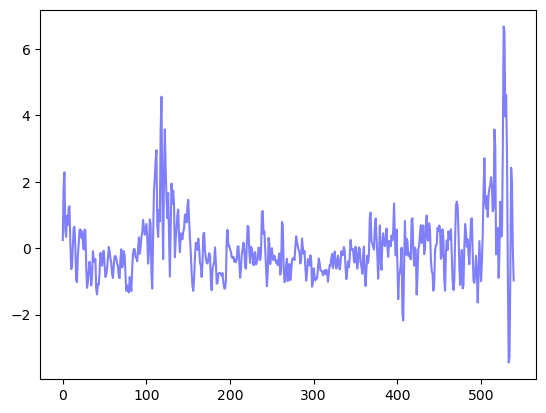

0.4733253756923119


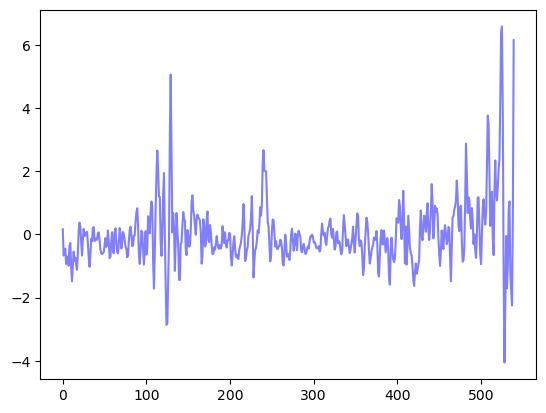

0.47909771042318955


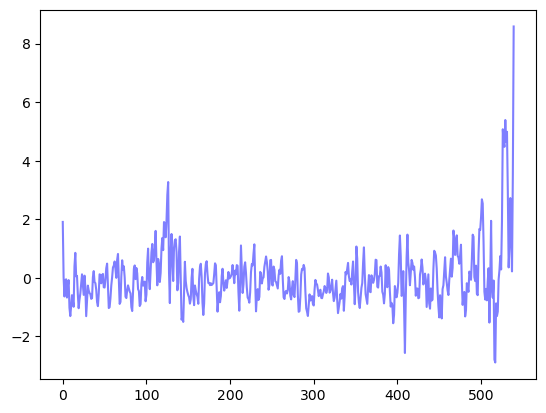

0.48222690203581864


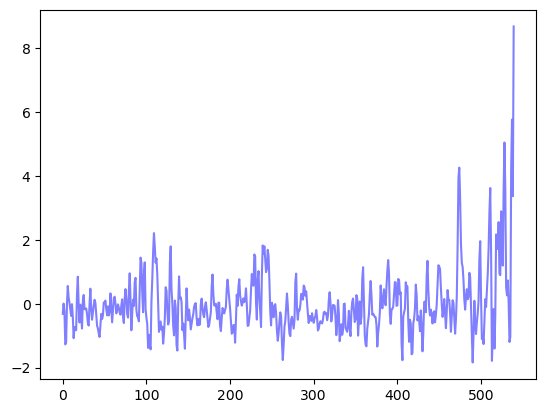

0.48816381409624393


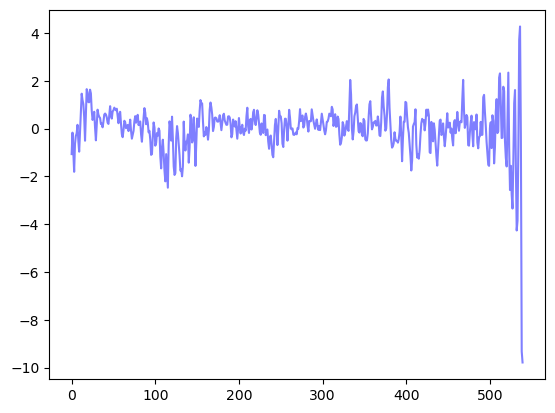

0.49415909232977484


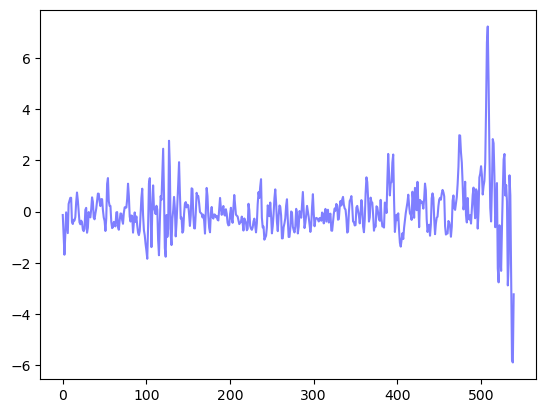

0.49572166458046313


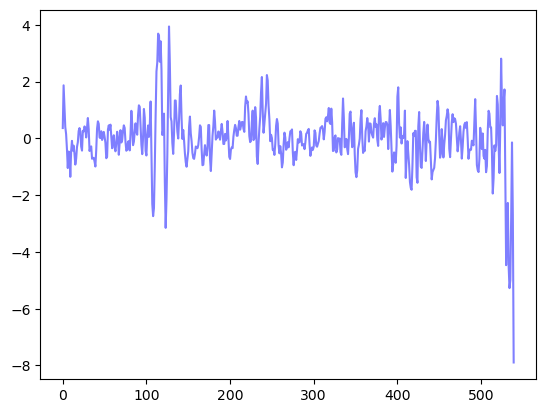

0.4964922178717186


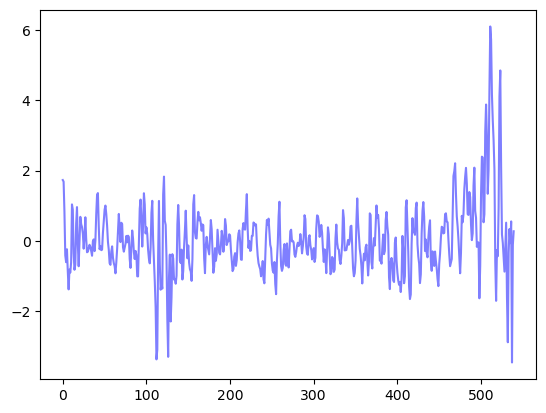

0.49827526702058395


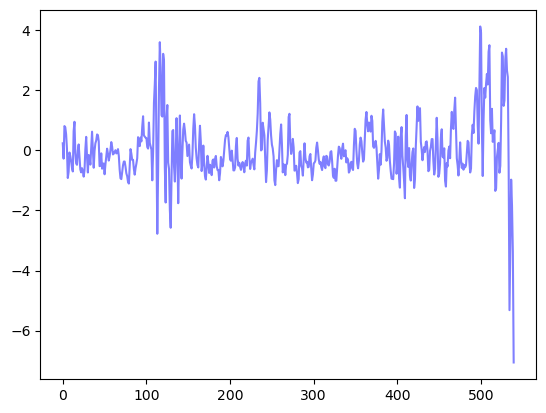

0.4992942354951505


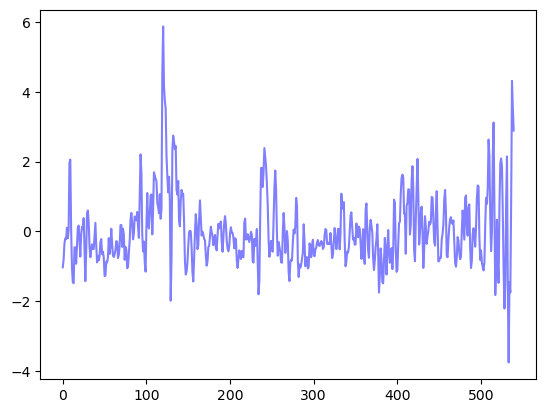

0.503738844180871


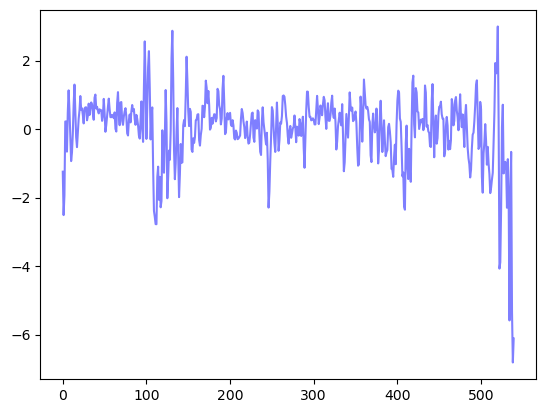

0.5105531462845802


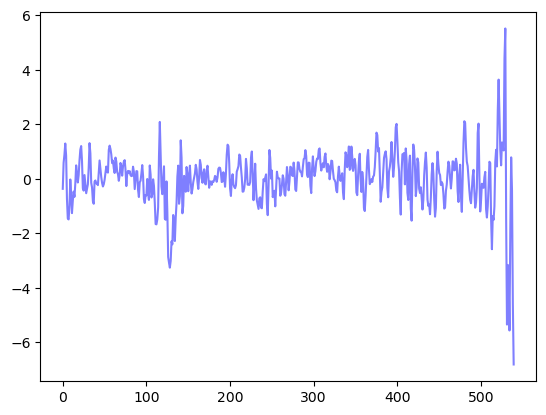

0.51475663090966


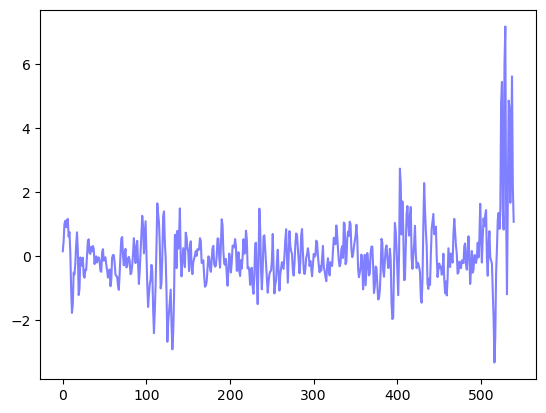

0.5150612076589075


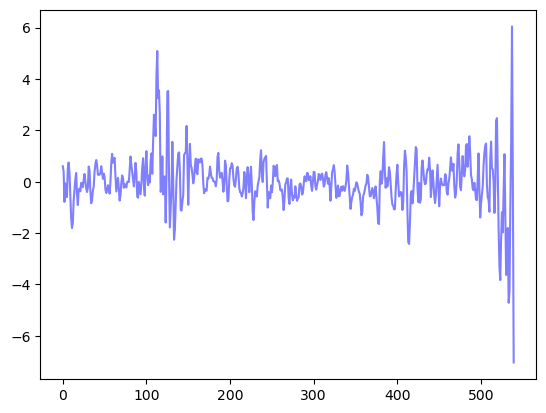

0.5212682055145983


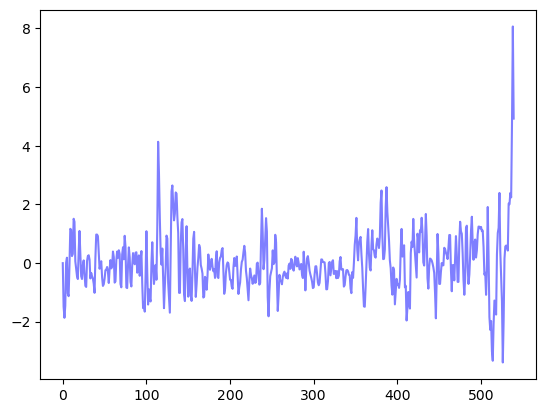

0.5224927837823478


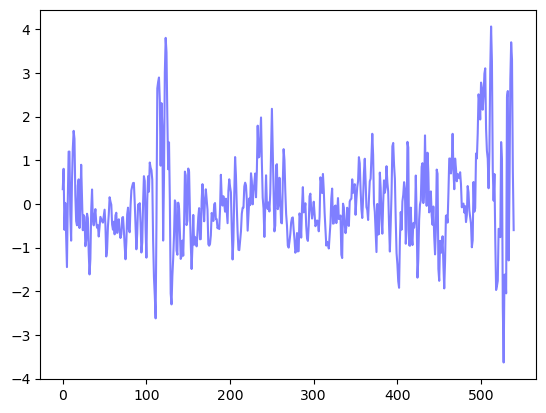

0.5232986451814636


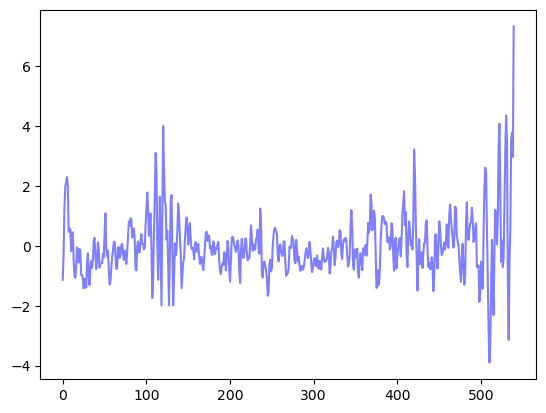

0.5257253732488131


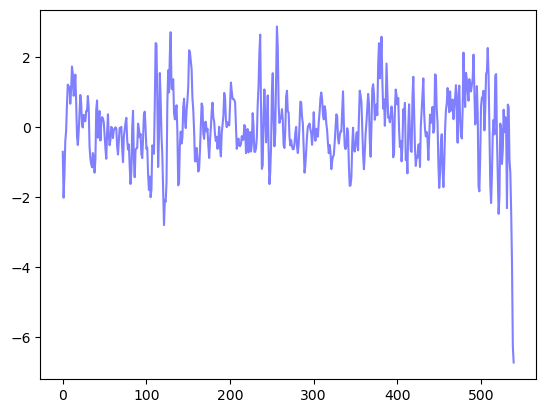

0.529179469872999


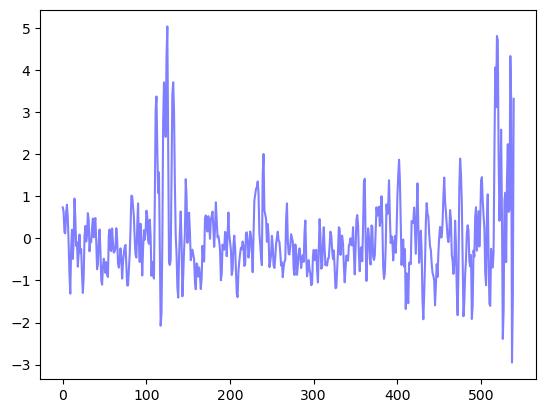

0.5331757187402819


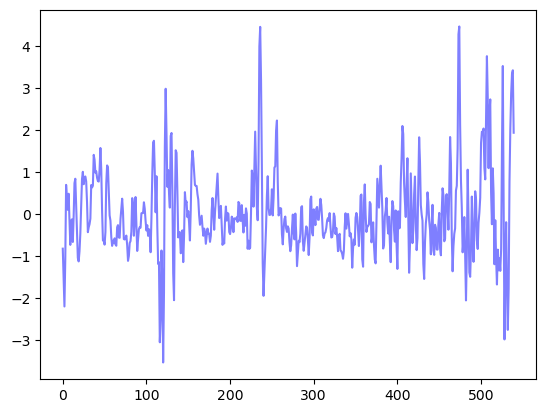

0.5407234890220055


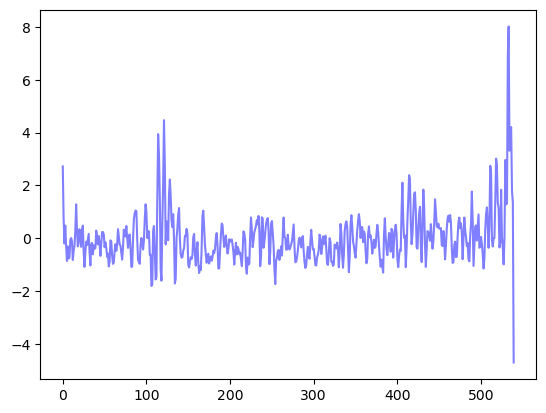

0.5416307365782034


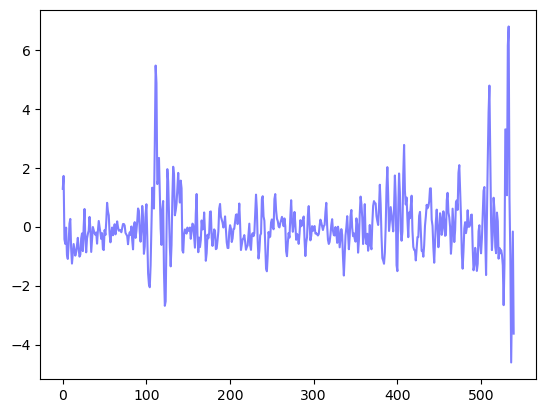

0.5424671228808328


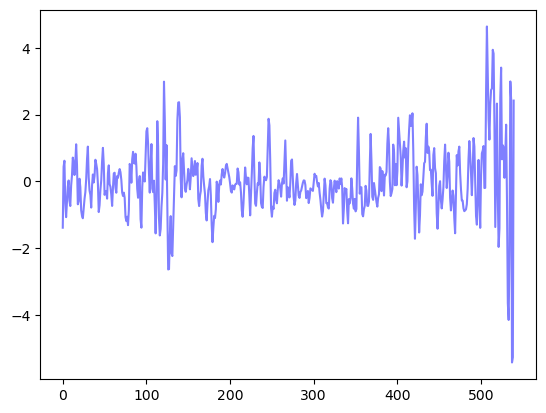

0.546532192783037


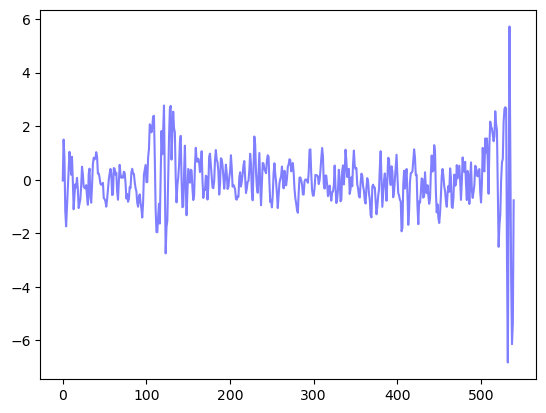

0.5487353602163182


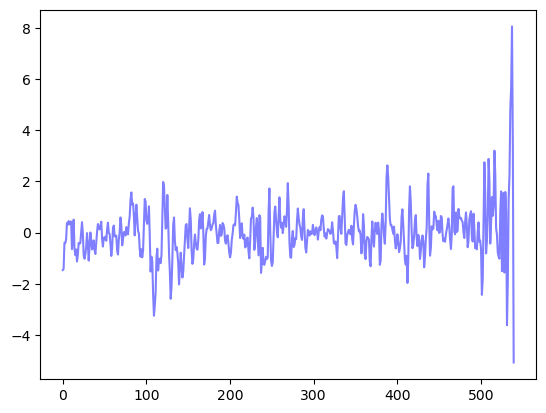

0.5573926075964617


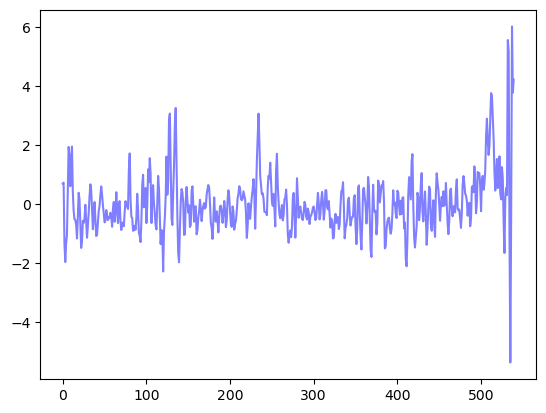

0.5659815157251255


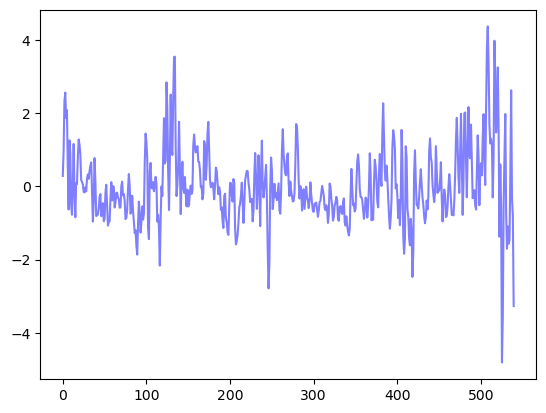

0.5773820172897085


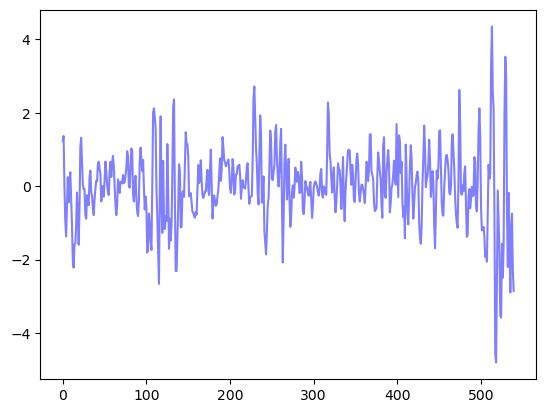

0.5855891986312627


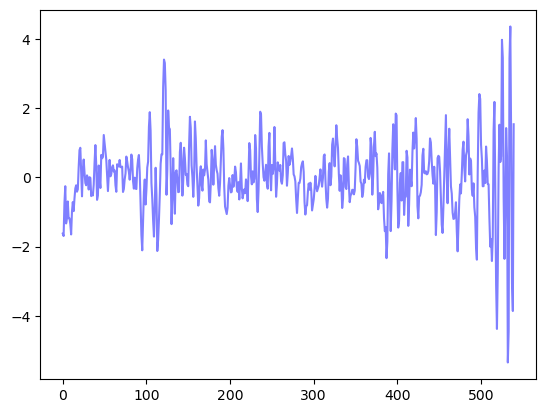

0.6052393909792307


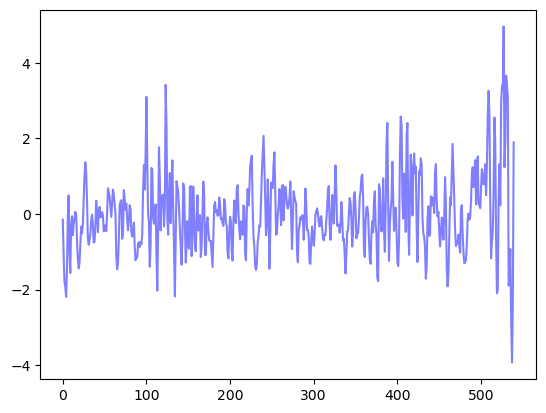

0.6191323994031215


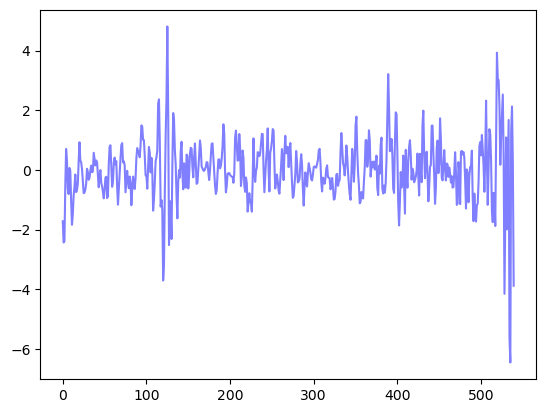

In [60]:
tot_var = np.nanmean(np.abs(np.diff(ir_final,1)), 1)
for i in np.argsort(tot_var):
    print(tot_var[i])
    _ = plt.plot(ir_final[i,:].T,c='b', alpha=.5)
    _ = plt.show()

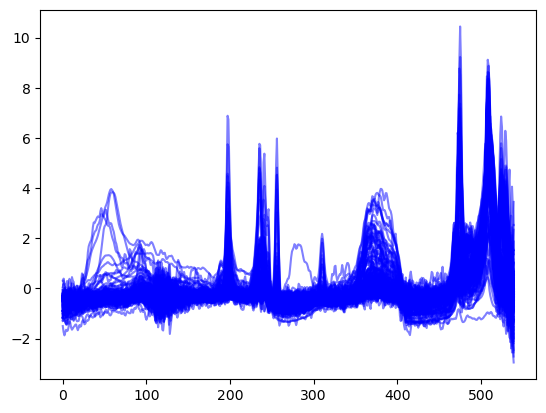

In [74]:
_ = plt.plot(ir_final[ir_bg_label=='no_background'].T,c='b', alpha=.5)

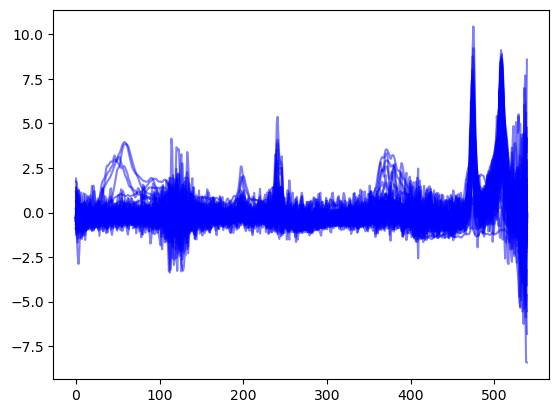

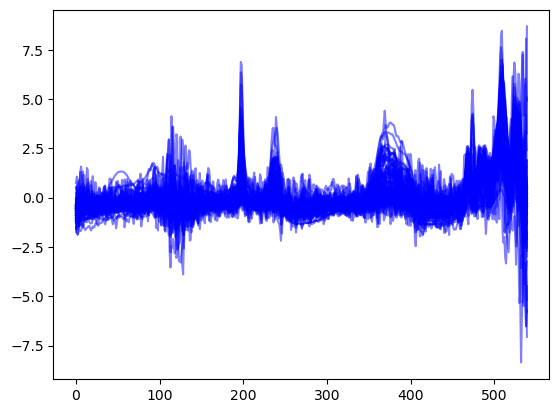

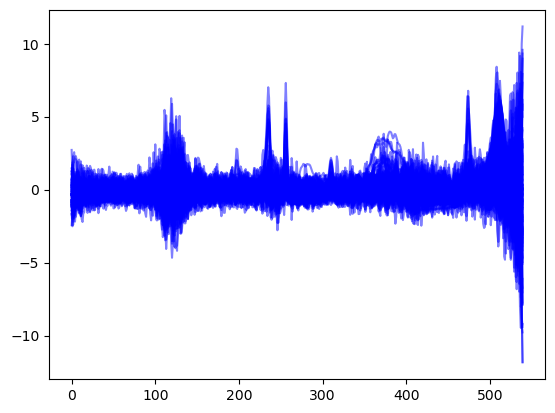

In [52]:
for poly in np.unique(label_list):
    _ = plt.plot(ir_final[np.array(label_list)==poly,:].T,c='b', alpha=.5)
    _ = plt.show()

In [75]:
ir_bg_label == 'background'

array([False, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False,  True,  True,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True, False,  True, False, False, False,
        True,  True, False, False, False,  True,  True,  True,  True,
       False, False,  True,  True,  True, False,  True,  True, False,
       False,  True, False, False, False, False, False,  True, False,
        True, False,  True, False,  True, False,  True,  True, False,
       False, False,  True, False, False,  True,  True, False,  True,
        True,  True,  True,  True, False, False, False, False,  True,
       False, False, False,  True,  True, False,  True, False,  True,
        True,  True, False, False, False, False, False,  True, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True, False,
        True, False,

In [76]:
pol_table = pd.DataFrame({'file':[polymer_list[[p in f for p in polymer_list]][0] for f in file_list]})

In [77]:
label_list

['PSL',
 'PP',
 'LDPE',
 'PP',
 'PP',
 'PP',
 'PP',
 'PSL',
 'PP',
 'PP',
 'PP',
 'LDPE',
 'PSL',
 'PP',
 'PP',
 'PSL',
 'PSL',
 'PSL',
 'PP',
 'PP',
 'PP',
 'PP',
 'PP',
 'PP',
 'PSL',
 'PSL',
 'PP',
 'PP',
 'PP',
 'PP',
 'PSL',
 'LDPE',
 'PSL',
 'PSL',
 'PSL',
 'PSL',
 'PP',
 'PSL',
 'LDPE',
 'PP',
 'PSL',
 'PSL',
 'PP',
 'PSL',
 'PP',
 'LDPE',
 'LDPE',
 'PSL',
 'PSL',
 'LDPE',
 'LDPE',
 'PSL',
 'PSL',
 'LDPE',
 'LDPE',
 'PSL',
 'PSL',
 'LDPE',
 'LDPE',
 'LDPE',
 'LDPE',
 'PSL',
 'LDPE',
 'LDPE',
 'LDPE',
 'LDPE',
 'LDPE',
 'LDPE',
 'LDPE',
 'LDPE',
 'PP',
 'LDPE',
 'LDPE',
 'PSL',
 'PSL',
 'LDPE',
 'LDPE',
 'PSL',
 'PP',
 'PP',
 'PP',
 'PSL',
 'PSL',
 'PSL',
 'LDPE',
 'LDPE',
 'PP',
 'PP',
 'PP',
 'PP',
 'PSL',
 'PP',
 'PSL',
 'PSL',
 'PP',
 'LDPE',
 'PSL',
 'LDPE',
 'PP',
 'PSL',
 'PSL',
 'LDPE',
 'PP',
 'LDPE',
 'LDPE',
 'PSL',
 'LDPE',
 'PP',
 'LDPE',
 'PSL',
 'PSL',
 'PP',
 'PP',
 'PP',
 'LDPE',
 'PP',
 'LDPE',
 'PP',
 'LDPE',
 'PP',
 'LDPE',
 'PP',
 'PSL',
 'LDPE',
 'LDPE',
 'L

In [22]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = list(range(preposs_data_raman.shape[0]))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_raman.to_csv('multiview_hqi_cp/data_raman_mix_rebecca.csv')
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.518556,...,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,0,0,PSL,0
1,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,...,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,0,0,PP,1
2,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.366901,-0.340027,-0.345898,-0.372772,-0.376174,...,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,0,0,LDPE,2
3,-0.313846,-0.328427,-0.334083,-0.337403,-0.336950,-0.338350,-0.343268,-0.371655,-0.415094,-0.394486,...,-0.420593,-0.420593,-0.420593,-0.420593,-0.420593,-0.420593,0,0,PP,3
4,-0.562266,-0.562266,-0.506885,-0.444668,-0.446092,-0.469932,-0.536322,-0.562266,-0.562266,-0.509432,...,-0.562266,-0.562266,-0.562266,-0.562266,-0.562266,-0.562266,0,0,PP,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.400893,-0.371327,-0.351976,...,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,0,0,PP,302
303,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.591380,...,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,0,0,LDPE,303
304,-0.371142,-0.374523,-0.403208,-0.439717,-0.500584,-0.529205,-0.496610,-0.485420,-0.487960,-0.515154,...,-0.356739,-0.371228,-0.368598,-0.338183,-0.344785,-0.371727,0,0,LDPE,304
305,-0.278839,-0.259512,-0.261979,-0.271579,-0.306650,-0.324291,-0.308842,-0.311011,-0.324481,-0.320796,...,-0.450608,-0.450608,-0.450608,-0.450608,-0.450608,-0.450608,0,0,PP,305


In [78]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = list(range(preposs_data_raman.shape[0]))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('multiview_hqi_cp/data_ir_mix_rebecca.csv')
preposs_data_ir


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2971.0,2973.0,2975.0,2977.0,2979.0,map_x,map_y,polymer,id,background
0,-0.533374,-0.715455,-0.437027,-0.278493,-0.371366,-0.485614,-0.584209,-0.608051,-0.516164,-0.548151,...,0.514311,1.244135,0.243864,-1.681738,-1.875712,0,0,PSL,0,no_background
1,-0.385079,-0.382351,-0.389339,-0.374432,-0.404575,-0.472624,-0.458487,-0.421973,-0.425969,-0.401584,...,1.181385,0.843418,0.318511,-0.039018,0.154444,0,0,PP,1,no_background
2,-0.259015,-0.261692,-0.260793,-0.259519,-0.258493,-0.257266,-0.254770,-0.251467,-0.249971,-0.251285,...,0.081520,0.059499,0.028984,0.002899,-0.007331,0,0,LDPE,2,no_background
3,-1.297477,-1.278462,-1.268845,-1.275861,-1.260874,-1.235911,-1.224441,-1.204902,-1.168902,-1.143828,...,0.350058,0.095798,-0.100820,-0.167961,-0.222111,0,0,PP,3,no_background
4,-0.812597,-0.827351,-0.877886,-0.838797,-0.719752,-0.621784,-0.586433,-0.620653,-0.681374,-0.748977,...,0.184933,0.070147,0.222202,0.278195,-0.199132,0,0,PP,4,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,-1.064112,-0.965536,-0.949136,-0.730402,-0.609432,-0.623401,-0.658595,-0.731898,-0.711120,-0.692156,...,0.078699,-0.211329,-0.032659,-0.663564,-0.759194,0,0,PP,302,no_background
303,-0.279452,-0.672831,-0.644104,-0.665629,-0.605041,-0.229777,-0.353308,-0.865069,-0.793504,-0.539918,...,1.266525,1.854900,0.448263,0.493322,-0.456403,0,0,LDPE,303,background
304,0.565726,0.251298,-0.879443,-0.872383,-0.428635,-0.000667,-0.398389,-0.653981,-0.363985,-0.283534,...,3.453235,6.055399,4.252829,0.557955,-1.087366,0,0,LDPE,304,background
305,-0.596498,-0.643858,-0.613417,-0.500021,-0.516213,-0.570385,-0.594021,-0.586496,-0.568403,-0.572797,...,-0.257710,-1.178147,-1.285773,-1.018180,-1.196717,0,0,PP,305,no_background


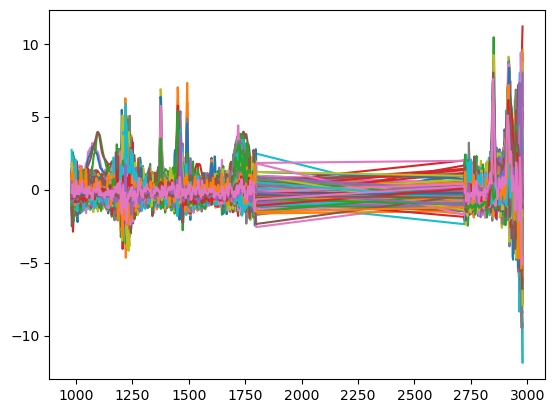

In [29]:
_=plt.plot(preposs_data_ir.iloc[:,:-4].T)

In [11]:
wn = np.array(XX_ir)

idx = np.logical_or(np.logical_and(wn > 980, wn < 1800),
np.logical_and(wn > 2720, wn < 2970) #2993.64990234375-10
) 


In [12]:
np.unique(label_list)

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype='<U7')

NH2SO4


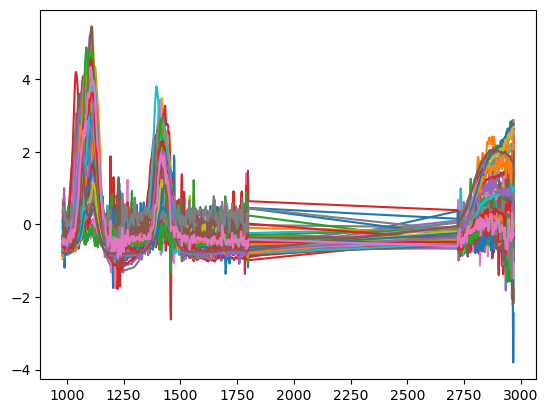

NaNO3


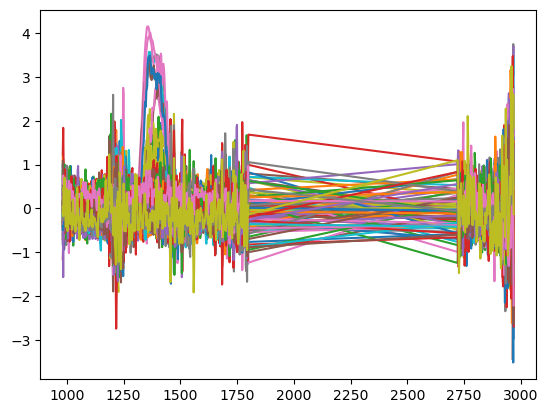

PE


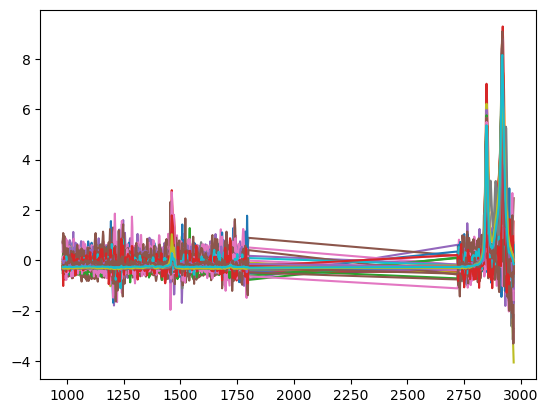

PP


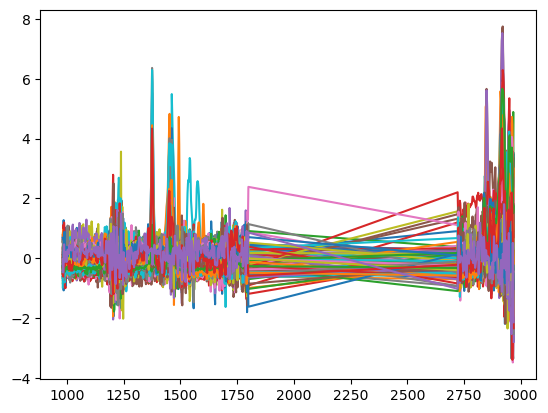

PSL


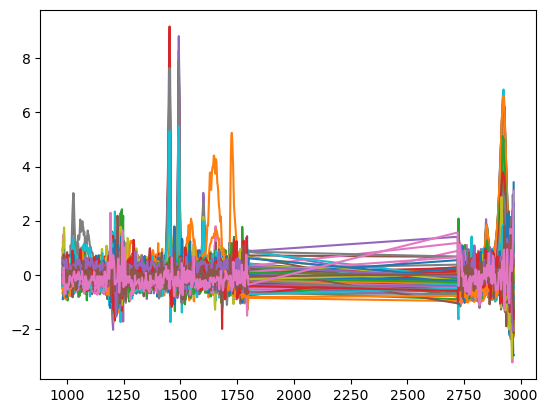

sucrose


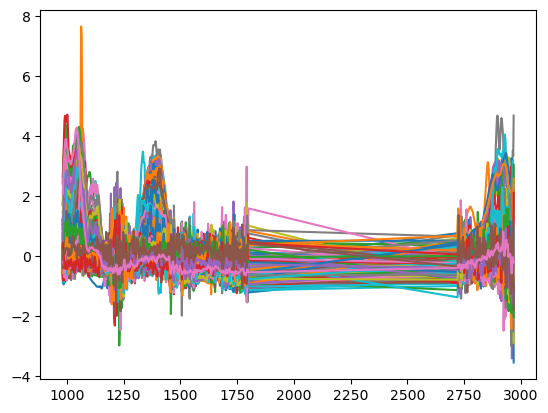

In [13]:
for label in np.unique(label_list):
    print(label)
    _ = plt.plot(XX_ir[idx],
             ir_final[np.array(label_list) == label,:][:,idx].T)#, c='b', alpha=.1)
    _ = plt.show()

NH2SO4


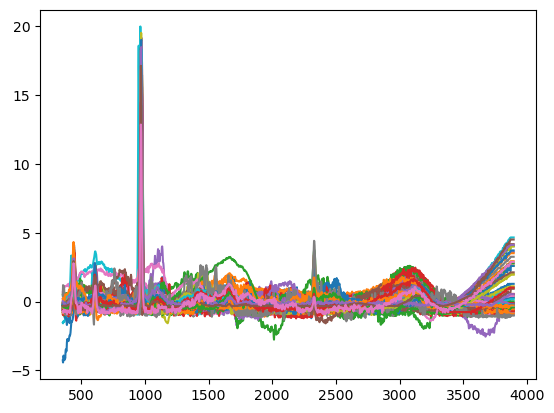

NaNO3


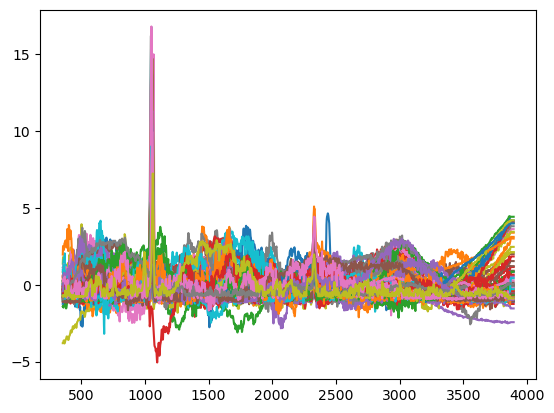

PE


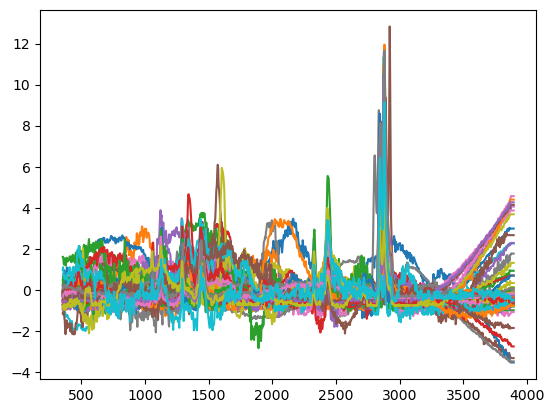

PP


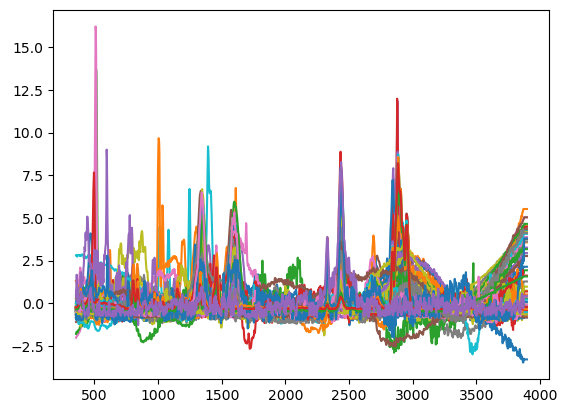

PSL


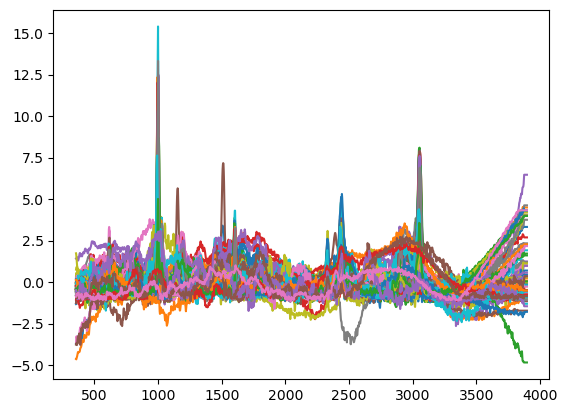

sucrose


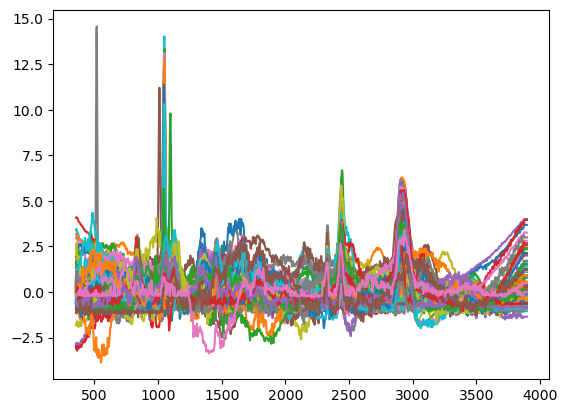

In [36]:
for label in np.unique(label_list):
    print(label)
    _ = plt.plot(XX_raman,
             raman_final[np.array(label_list) == label,:].T)
    _ = plt.show()

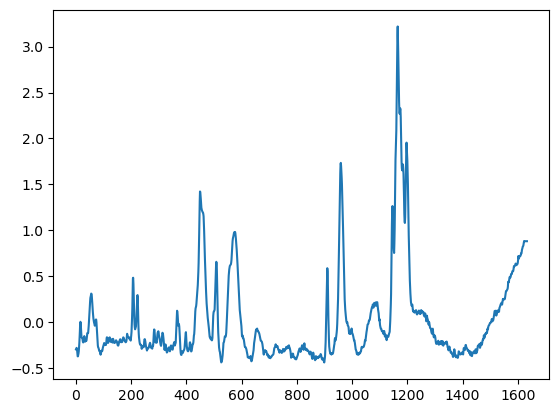

In [40]:
plt.plot(raman_final[np.array(label_list) == 'PP',:].mean(0))